# Quantum Circuits | THC Joint Norm + 881Q DQI

A source-built paired DQI decoder, Phuc Thai's authenticated EXP-225a arithmetic, and Dmitrii Gluzdov's single-group THC chemistry with our complete-H joint norm refit.

**Development projection: approximately 11.384 (estimate; not a leaderboard result).** Chemistry below is a fresh local FULL-PASS; AR and DQI retain the prior v6 evidence. Run All performs all three fresh full official checks and updates the results.

| Task | Q | Mean Toffoli / effective C | R / lambda_eff | Cost | Evidence |
|:--|--:|--:|--:|--:|:--|
| Phuc EXP-225a inverse square root | 82 | C = 1684.085788 | — | 138095.034621 | prior FULL-PASS, 200540928 shots |
| Paired DQI v6 | 881 | 1116995 | R = 1.191260 | 1.032784e12 | prior FULL-PASS, 102400 shots |
| THC joint norm R1/B496/C384 | 833 | 20286 | 47.895474603 | 8.093491290e+08 | fresh local FULL-PASS, 36608 shots |
| Geometric mean reference / cost | | | | ~11.384 | development estimate |

The chemistry replaces the preceding R6/B144/C127 block (FULL-PASS cost 8.80091e8) while retaining the AR EXP-225a binary and every paired-v6 DQI source and check cell unchanged. All eight ANF circuits are recompiled from authenticated words and checked against the accepted SHA256 values. The submitted NPZ keeps the exact dataset bytes.

**Honest public comparison, 25 October 2026:** [Ahmed Berat Ozer v4](https://www.kaggle.com/code/ahmedberatozer/quantum-ai-df-thc-group-compression) has **11.22420 leaderboard score**. Our approximately 11.384 is a component-based estimate, with no observed Kaggle result or rank claim for this revision.


In [1]:
from __future__ import annotations
import gc, hashlib, importlib.util, json, math, os, platform, sys, time
from pathlib import Path
os.environ.update(OPENBLAS_NUM_THREADS='1', OMP_NUM_THREADS='1', MKL_NUM_THREADS='1')
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
RUN_STARTED = time.monotonic()

WORK = Path('/kaggle/working')
INPUT = Path('/kaggle/input')
roots = [INPUT/'competitions/google-verifiable-quantum-circuit-compilation',
         INPUT/'google-verifiable-quantum-circuit-compilation', INPUT]
COMP = next((p for p in roots if (p/'verifiers').is_dir()), None)
if COMP is None:
    raise FileNotFoundError('Attach the official competition data in Inputs.')
SRC, FINAL, REPORTS = WORK/'src', WORK/'submission', WORK/'reports'
for directory in (SRC, FINAL, REPORTS, WORK/'build', WORK/'chem_compiler'):
    directory.mkdir(parents=True, exist_ok=True)
assert not any(FINAL.rglob('*.kmb')), 'Start a fresh Run All session.'
sys.path[:0] = [str(SRC), str(COMP/'kickmix'), str(COMP/'verifiers')]
os.chdir(WORK)
WORKERS = min(2, os.cpu_count() or 1)
print('CPU release: source-built DQI and ANGLE loaders; full official checks.', flush=True)

runtime_display = display(Markdown('**Run All timing:** in progress; two CPU workers, no GPU.'), display_id=True)

results_display = display(Markdown('**Fresh verification results:** pending.'), display_id=True)


CPU release: source-built DQI and ANGLE loaders; full official checks.


**Measured CPU Run All: 21.91 minutes.** All three fresh FULL-PASS; 11 archive members rehashed. Development projection 11.384375; leaderboard result unknown.

**This Run All: all three fresh FULL-PASS.**

| Task | Q | Cost | Reference / cost | Status |
|:--|--:|--:|--:|:--|
| invsqrt | 82 | 1.380950346e+05 | 15.03873× | FULL-PASS |
| dqi | 881 | 1.032784429e+12 | 23.66367× | FULL-PASS |
| dfthcsos | 833 | 8.093491290e+08 | 4.14605× | FULL-PASS |

**Development projection: 11.384375** (secret-salt score unknown).

## Reproduce on CPU

Attach the official competition and [VQCC ViberTeam verified circuits](https://www.kaggle.com/datasets/anazemcev/vqcc-viberteam-verified-circuits), dataset **v2 or newer containing `thc_package_manifest.json`**. This prepared local release requires that dataset update before a public Run All. No other dataset or notebook inputs are needed.

The notebook discovers files under `/kaggle/input`, authenticates the flat THC sources and numeric inputs, recompiles eight exact ANF circuits and runs fresh full verifiers. It never reads an input ZIP. Use the pinned Python 3.13 CPU image, Internet off; numerical refitting is a prior deterministic CPU stage whose public-input recipe is included.

Salt `vqcc-signed-digit-memory-v1-20261023`, seed None. DQI: 102400 shots, batch256, log2_delta=-128; arithmetic: 200540928 shots; chemistry: 572 addresses ×64 =36608 shots. Official Python verifiers are hashed before and after. CPU Run All runtime about 20–35 minutes is an estimate; this v7 has not run on Kaggle.


In [2]:
(WORK/'LICENSE').write_text('\n                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n', encoding='utf-8')
(WORK/'NOTICE.txt').write_text("Source-built DQI audit and reproduction, 25 October 2026\n\nThe in-place J-fraction decoder and its finite-field and polynomial arithmetic\nare credited to SomeJoint / Agniv Banerjee. Public source notebook:\nhttps://www.kaggle.com/code/somejoint/quantum-circuits-8-95-lb-cost-breakdown\n\nThe classical-mask projection is credited to Manwithacat. Pinned public notebook:\nhttps://www.kaggle.com/code/manwithacat/dqi-classical-mask-projection-9-13909?scriptVersionId=362021360\nNotebook SHA-256 bd403c9c5761c3dbe031fa47f66351dd6d3fd99b04c17351f36f0c22952e4211.\nIts source explicitly credits SomeJoint / Agniv Banerjee's decoder under the\nApache License, Version 2.0, subject to that upstream's notices. Its additional\narithmetic/chemistry portfolio artifacts are not copied into this DQI folder.\n\nGoogle Quantum AI / competition authors: unchanged official task specification,\nreference code, verifier and Kickmix. These are installed dependencies, not\nrelicensed here. No upstream authors' endorsement is implied.\n\nOur additions are the source authentication/build/verifier wrapper, independent\nalgebraic fixtures and the audit. No claim to originate the upstream decoder or\nmask projection is made. The extracted source files remain unmodified; their\nindividual byte hashes are recorded in pinned_sources.json. The local Apache\nlicense text is supplied as LICENSE.txt. Further upstream notices in a full\npublished distribution must remain attached rather than being replaced by this\nshort provenance note.\n\n\nArithmetic: Phuc Thai / phucthaiv02 EXP-225a, Apache-2.0 published circuit;\noriginal coefficient fitter unavailable. The arithmetic lineage includes\nDmitrii Gluzdov, Sumit Chongder, Rudra, Kozykorpesh, Alex Chilton,\nKirill Tymchishin (Kirill Tym), Zongao Bian and anazemcev.\nmarsyas contributes the fused phase-stage idea.\n\nDQI pairing idea: Phuc Thai EXP-119a; earlier two-pointer/lean-Forney idea:\nPhuc Thai EXP-118c. Ahmed Berat Ozer published an independent paired source.\nOur all-chart zero-pivot extension, trace-tensor phase, lifetime scheduling,\nHMR-first inverse, recycled norm and borrowed-zero metadata are independent\nViberTeam source. Two first-order gap pointers retain an explicit third-gap\napproximation and the upstream higher-order-gap limitations.\n\nChemistry: ViberTeam A structural R6/B144/C127 training, signed 10-bit\nquantization and fixed-word weight/offset refit. Training builds on Ahmed Berat\nOzer's public group-compression factors and the competition DF-THC starter kit.\nKozykorpesh / kozykappa: signed Givens gauge and four-address decomposition.\nSumit Chongder -> Kozykorpesh -> Kirill Tymchishin -> anazemcev: banked\nlookup and ANF measurement erasure. Phuc Thai: joint fixed-word norm objective;\nViberTeam: complete-H analytic formulation and bounded implementation.\n\nGu et al., Discovering state-of-the-art quantum circuits with large language models,\nhttps://github.com/andigu/uncompute : inherited reversible Reed-Solomon/tower lineage.\nGu source commit credited by the public lineage: 64b5a13aa249f1360846657392e6c66817b26d0f.\nGuang Hao Low / DF-THC starter-kit lineage, LightningV08, Mizero Lucky Gall\nand k256net remain credited. The authenticated package and embedded source\nretain the individual source notices and complete Apache-2.0 text.\n\nApache-2.0 covers attributed code and circuits; numerical inputs and the\nofficial competition/runtime keep their inherited Other / competition /\nQuantum Circuit Toolbox terms. No upstream authors' endorsement is implied.\n", encoding='utf-8')


3505

In [3]:
(WORK/'NOTICE.txt').open('a', encoding='utf-8').write('\nV7 THC update: Dmitrii Gluzdov public v4 single-group THC factorization and chemistry_r5.py ANF lookup compiler, Apache-2.0. Ahmed Berat Ozer v4 integration idea and dfthc_group_build.py wrapper. Artem Nazemtsev ANF/measurement erasure; Kozykorpesh pebbling/signed gauge. ViberTeam K complete-H fixed-word joint W/native-offset refit adapted from F/H with deterministic caps. Phuc Thai joint-norm idea and unchanged EXP-225a; paired-v6 DQI unchanged. Historical R6 chemistry credits remain historical.\n')


503

In [4]:
%%writefile src/portfolio_runtime.py
"""V5 public dataset authentication and bounded local release checks.

SPDX-License-Identifier: Apache-2.0
ViberTeam adaptation of G's portfolio runtime; retain notebook NOTICE.txt.
"""
from __future__ import annotations

import hashlib
import json
from pathlib import Path
import shutil
import time
import zipfile

SALT = 'vqcc-signed-digit-memory-v1-20261023'
AR_SHA = '0f84f5bab3a02e6b357d4656553607174345a33d252cef643f9136db13212141'
DQI_SHA = '1161f7221de935ba1399ced409b9936d8b4cb570ef3314585d4b9bc2c5b24dd9'
REFERENCE_COSTS = {'invsqrt': 2076774.233715282,
                   'dqi': 24439473914136.668, 'dfthcsos': 3355599588.3155365}
ANGLE_COUNT = 8
CHEM_FILES = ['submission.npz'] + [f'angle_k_{i}.kmb' for i in range(ANGLE_COUNT)]
ARCHIVE_MEMBERS = {'invsqrt.kmb', 'dqi.kmb'} | {'dfthcsos/'+n for n in CHEM_FILES}
assert len(ARCHIVE_MEMBERS) == 11


def digest(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()


def save(path, value):
    import numpy as np
    def encode(item):
        if isinstance(item, np.ndarray): return item.tolist()
        if isinstance(item, np.generic): return item.item()
        if isinstance(item, Path): return str(item)
        raise TypeError(type(item).__name__)
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, default=encode)+'\n', encoding='utf-8')


def official_manifest(competition):
    root = Path(competition)/'verifiers'
    return {p.relative_to(root).as_posix(): digest(p) for p in sorted(root.rglob('*.py'))}


def authenticate_sources(source, manifest):
    actual = {name: digest(Path(source)/name) for name in manifest}
    assert actual == manifest, 'Embedded source bytes changed'
    return actual


def measure_full(name, function, reports, *, expected_shots, context):
    started = time.monotonic()
    result = function()
    result['wall_seconds'] = time.monotonic()-started
    if result['status'] != 'PASS' or result['verified_shots'] != expected_shots:
        save(Path(reports)/(name+'_failure.json'), result)
        raise ValueError(f'{name}: full verification did not pass')
    result['classification'] = 'FULL-PASS'
    result['verification_context'] = dict(fresh=True, salt=SALT, seed=None, **context)
    save(Path(reports)/(name+'.json'), result)
    return result


# These functions are embedded into the v7 portfolio_runtime.py.
# SPDX-License-Identifier: Apache-2.0; ViberTeam K.
def locate_package(input_root):
    matches=sorted(Path(input_root).rglob('thc_package_manifest.json'))
    if len(matches)!=1:
        raise FileNotFoundError(f'Expected one THC package manifest, found {len(matches)}')
    return matches[0].parent

def authenticate_package(input_root,pins,reports):
    package=locate_package(input_root)
    manifest_path=package/'thc_package_manifest.json'
    assert digest(manifest_path)==pins['chem_package_manifest_sha256']
    manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
    assert len(manifest)==pins['chem_manifest_entries']
    receipt=[]
    for name,entry in manifest.items():
        filename=entry['file']
        assert Path(filename).name==filename and filename.startswith('thc_'),filename
        target=package/filename
        assert target.is_file() and target.stat().st_size==entry['bytes'],name
        assert digest(target)==entry['sha256'],name
        receipt.append(dict(name=name,file=filename,bytes=entry['bytes'],sha256=entry['sha256']))
    assert set(CHEM_FILES)<=set(manifest)
    assert digest(package/'invsqrt_exp225a.kmb')==AR_SHA
    assert manifest['public_factor.npz']['sha256']==pins['public_thc_sha256']
    save(Path(reports)/'public_input_receipt.json',dict(status='PASS',
        classification='partial/file authentication; no circuit verification',
        public_dataset='anazemcev/vqcc-viberteam-verified-circuits',
        original_factorization='dmitriigluzdov/vqcc-femoco-public-factorization/4',
        located_by='rglob thc_package_manifest.json',manifest_sha256=digest(manifest_path),
        chemistry_manifest_entries=receipt,ar_sha256=AR_SHA,private_inputs=[],input_zip_reads=0))
    return package,manifest

def copy_ar(package,final):
    source=Path(package)/'invsqrt_exp225a.kmb'
    assert digest(source)==AR_SHA
    final=Path(final);final.mkdir(parents=True,exist_ok=True)
    shutil.copyfile(source,final/'invsqrt.kmb')
    assert digest(final/'invsqrt.kmb')==AR_SHA

def copy_chemistry(package,manifest,final):
    output=Path(final)/'dfthcsos';output.mkdir(parents=True,exist_ok=True)
    assert not any(output.iterdir()),'Use a fresh output directory'
    for name in CHEM_FILES:
        entry=manifest[name]
        shutil.copyfile(Path(package)/entry['file'],output/name)
        assert digest(output/name)==entry['sha256'],name
    return output

def recompile_angles(package,manifest,work,reports):
    """Compile all eight ANF circuits from authenticated words and flat sources.

    No input ZIP is opened. The authenticated NPZ remains byte-identical.
    """
    import importlib,sys
    source=Path(work)/'chem_compiler';source.mkdir(parents=True,exist_ok=True)
    output=Path(work)/'chem_recompiled'
    names=('dfthc_group_build.py','banked_lab.py','chemistry_refine.py','thc_angle_compile.py')
    for name in names:
        entry=manifest['source/'+name]
        blob=(Path(package)/entry['file']).read_bytes()
        assert hashlib.sha256(blob).hexdigest()==entry['sha256']
        target=source/name
        if target.exists():assert target.read_bytes()==blob,'Embedded source changed: '+name
        else:target.write_bytes(blob)
    sys.path.insert(0,str(source))
    compiler=importlib.import_module('thc_angle_compile')
    started=time.monotonic()
    report=compiler.compile_angles(Path(package)/manifest['selected_compact.npz']['file'],output)
    hashes={name:digest(output/name) for name in CHEM_FILES[1:]}
    assert hashes=={name:manifest[name]['sha256'] for name in CHEM_FILES[1:]}
    elapsed=time.monotonic()-started
    save(Path(reports)/'chemistry_recompile.json',dict(status='PASS',
        classification='partial/byte-exact source compilation; fresh full verifier follows',
        seconds=elapsed,all_8_kmb_hashes_identical=True,angle_sha256=hashes,
        submission_npz_source='Authenticated dataset bytes',compiler_report=report,input_zip_reads=0))
    return output,elapsed


def make_archive(final, archive_path, members):
    assert set(members) == ARCHIVE_MEMBERS and len(members) == 11
    manifest = []
    for name in sorted(members):
        path = Path(final)/name
        manifest.append(dict(file=name, bytes=path.stat().st_size, sha256=digest(path)))
    with zipfile.ZipFile(archive_path, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as archive:
        for row in manifest:
            archive.write(Path(final)/row['file'], row['file'])
    with zipfile.ZipFile(archive_path) as archive:
        assert sorted(archive.namelist()) == sorted(members)
        for row in manifest:
            with archive.open(row['file']) as stream:
                assert hashlib.file_digest(stream, 'sha256').hexdigest() == row['sha256']
    return manifest


Writing src/portfolio_runtime.py


In [5]:
import portfolio_runtime as P
import kickmix as km
import scipy
from invsqrt import verify_submission_invsqrt as IV
from dfthcsos import verify as CV
SALT = P.SALT
EXPECTED_OFFICIAL = {'dfthcsos/__init__.py': '81915e324cc0cade67f52a54b7a51991fd96abaea94d1f8a4d423dae20e57348', 'dfthcsos/example_submission/angle_k_reference_circuit.py': '8daccdca69f2d718b0176cd9281803df84a988ea5ac6c167fbb02e461ac2b371', 'dfthcsos/scoreinfra/__init__.py': 'be90e0d503d5c20dcac0102af638b9a4ccad0341daa5baa5d49216a259e4516f', 'dfthcsos/scoreinfra/circuits.py': 'fc027b52fdcebe14404f403a089122485d097ed65d03e6d989623d620b1ab68c', 'dfthcsos/scoreinfra/costs_prepare.py': '7f1e190c42fc5325f3e6689fbbef51f95b0cb12f1c828cda92b6c088e72206da', 'dfthcsos/scoreinfra/dfthc_math.py': 'ae82898d47a7a86b96378fb906e0f8a9f46003065cf19c7c09952a123b5b5af8', 'dfthcsos/scoreinfra/reference.py': 'a2d5a63191d655729e29f0fde1e85fe4630bf896a91a63bb894d8d7daf71ed39', 'dfthcsos/verify.py': '0775be7a528922367caebe9e4d051d6199811f1aefeaa4b793eaaa4621b8ec9d', 'dqi/__init__.py': '01c870aa9763f4e4357fc6654bff1d3296cec995bd0943f87b4a48946ada5b40', 'dqi/dqi_reference_circuit.py': '2b8e1b80a806157c333a7e308eaf2499ee09de499efbc05875202c327959959e', 'dqi/verify_submission_dqi.py': 'f14274bc0943fb9769ddb01131be6063191a15009fe1caf1d4bdd9fd25194e65', 'invsqrt/__init__.py': 'e9a6ecf253c343528578be5fa92eb820ccade63333aebb784552fb4ae75dbc0b', 'invsqrt/nr_reference_circuit.py': 'bb90330dcf774f7b502de471293facba67f27952cc8808fe4a9970a9b1322e23', 'invsqrt/verify_submission_invsqrt.py': 'ddef520dec6b68d1cf0a6f328ddd36d79eb84570b9192cf3f7acaf073f06733a'}
assert P.official_manifest(COMP) == EXPECTED_OFFICIAL, 'Official verifier bytes changed.'
environment = dict(python=sys.version, numpy=np.__version__, scipy=scipy.__version__, platform=platform.platform(),
    workers=WORKERS, development_salt=SALT, seed_override=None,
    verification_mode='fresh_full_all_three_tasks', dqi_log2_delta=-128.0,
    default_batch_size=256, official_verifiers_sha256=EXPECTED_OFFICIAL,
    private_input_datasets=[], kernel_sources=[], internet_required=False)
P.save(REPORTS/'environment.json', environment)
print(json.dumps(environment, indent=2))


{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "numpy": "2.1.3",
  "scipy": "1.16.3",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "workers": 2,
  "development_salt": "vqcc-signed-digit-memory-v1-20261023",
  "seed_override": null,
  "verification_mode": "fresh_full_all_three_tasks",
  "dqi_log2_delta": -128.0,
  "default_batch_size": 256,
  "official_verifiers_sha256": {
    "dfthcsos/__init__.py": "81915e324cc0cade67f52a54b7a51991fd96abaea94d1f8a4d423dae20e57348",
    "dfthcsos/example_submission/angle_k_reference_circuit.py": "8daccdca69f2d718b0176cd9281803df84a988ea5ac6c167fbb02e461ac2b371",
    "dfthcsos/scoreinfra/__init__.py": "be90e0d503d5c20dcac0102af638b9a4ccad0341daa5baa5d49216a259e4516f",
    "dfthcsos/scoreinfra/circuits.py": "fc027b52fdcebe14404f403a089122485d097ed65d03e6d989623d620b1ab68c",
    "dfthcsos/scoreinfra/costs_prepare.py": "7f1e190c42fc5325f3e6689fbbef51f95b0cb12f1c828cda92b6c088e72206da",
    "dfthcsos/scoreinfra/dfthc_math.p

In [6]:
RELEASE_PINS = {'chem_package_manifest_sha256': 'a35ccdddfd1bb69d1ae1365db25c0de60dccc7c3763d23392e7f332f659957fa', 'chem_manifest_entries': 41, 'ar_sha256': '0f84f5bab3a02e6b357d4656553607174345a33d252cef643f9136db13212141', 'dqi_sha256': '1161f7221de935ba1399ced409b9936d8b4cb570ef3314585d4b9bc2c5b24dd9', 'dqi_variant': 'paired-v6', 'dqi_source_manifest': {'build_merge_dqi.py': '1217816147f87a8a166bc2d39d8206d4874e2a5ea574937ebb8248744f972c07', 'build_paired_dqi.py': '43829ded2d556d824590b6408a44ace06b6a8b4a0399c8f30341673a53838a1c', 'build_projected_dqi.py': 'f50dff719826b0e4a354715c1e0061ac91610779699d19c045308264e16e2cd9', 'compact_gap_variant.py': '5206a2d109071dc3c9dd275249ea93c17b3c77f6e3b5cbac359d545e8a98ea8a', 'compact_lifetime_kernels.py': 'f47670b0b7c912055a55edba3153a0690473f71e7f31e03204f3b2f39bd90805', 'LICENSE.txt': 'cfc7749b96f63bd31c3c42b5c471bf756814053e847c10f3eb003417bc523d30', 'matrix_pair_kernels.py': '262ccbc491950b82c9eea5ff6f66983888997b3f15122c91825ec6d1c6dca81d', 'mc4_inverse.py': 'ec1e66bcd1ba8723792238be68f91dfc887170cc8a11f81d81420d25d26b5ce4', 'merge_kernels.py': 'e6b5053fcbdf60bc72a96c4c4c2923f666296059f7e08e56da3fff8a11c4d75e', 'norm_recycle_inverse.py': 'a2d136d74ac0acebe48023a73d9b0583a3cfc85fac809c1a757fbee30b8e239e', 'NOTICE.txt': '65a08ae66c1bc7dca13f077c7e61222f7c98c2b52f81c4cd300fad52b1f77447', 'one_mask_inverse.py': 'bcad22161e54598cf3763f12e4d2dcf7f1a5a6d6a210c487417eef7ec2623991', 'paired_kernels.py': 'acbe7508ee68330666c6dd640b8b255de06fff61d8e3b9d847391aa925020016', 'phase_tensor.py': '433ebd7a9e392aa2dbf4483142e997ecb6d96b6ed6957d0de5b227722cfa2856', 'pinned_sources.json': 'a747be631f533aa11537d5edb305e856fc395570691a5fcd2aee98daf9abcb38', 'pointer_phase_codec.py': '71f2adef49ce9467e347b3231e2d126fac2741daec1c9536f5b0af49be487870', 'quadratic_cube.py': '9d8dac8a7fb88169923e0defe7f467fef606437b67add35182e1d85b0e9252ba', 'smallspace_inverse.py': '669bbb035cdc0eef5f113cf1c6627f23464c6dd8c0c38c4cc36042c2614a7173', 'triple_matrix.py': 'd5693f769f6c466b01029466606d255c2c62ecf0be2241b2acf2de4d5e5352c7', 'triple_ordinary.py': 'bd92b3365b249a5a6ba876b85dbf0e1d3ff52e4f85a86fff929f2b986763af02', 'upstream/dqi/common.py': 'f21e9ff6fb5b6f2e665deb546c2751e4ae826cd305931a37a2e328906abea0d7', 'upstream/dqi/compact_euclid.py': '02e78391cde317b1de1bc7f60193560990c9a47640d4d20a119d58fbdb09b1fc', 'upstream/dqi/continued_fraction/jfraction_decoder.py': '532d21556fa7981e73e68bd91f2fdb49ca7091a4daca0267be35ffe8fa563ee3', 'upstream/dqi/continued_fraction/jfraction_gap_decoder.py': 'c41f980ff7778234f4a098c15a3d52657a33f5a9748d8dbc31d4c646675c3ed6', 'upstream/dqi/continued_fraction/keyeq/model_fast_extraction.py': '77fb085f1bf0a1a22167d5010e9ad327295c83555d9c539ca0a5187d82ef0336', 'upstream/dqi/continued_fraction/keyeq/model_jfraction.py': 'e3c3b83a76b520b1720eee865aca20b72433211dbb5c10f422e2abf08be4d1b9', 'upstream/dqi/continued_fraction/mask_projection.py': '21476b1931a0d9d5ace2ad5a25e6fdb2fb1e04c303fce0cd35e84486b68c681e', 'upstream/dqi/continued_fraction/poly_arithmetic.py': 'f26338b25b7c9623e3690fb4e571e87c47391943fe9742016d52a644dfe4a975', 'upstream/dqi/counter.py': '13950281035350b8a4336da90f1d7a9bda453223af02ae78f9b3e1bd7bbd3380', 'upstream/dqi/cubic.py': 'c74e40a0f0ec1d93bf1bd6a64b71794002bc8db62baf05ffbefa2efda174f58a', 'upstream/dqi/early_a.py': '3336ddb6e634437d7f328de78fdfce1acd0cf2090e1ccb69b11390f2970b2cf2', 'upstream/dqi/evaluation.py': '499cb9faf95027d3c9cecca317d251ebaaf309d7aee7e2de4c9b115a2295bc76', 'upstream/dqi/forney_control.py': '2c343b082f9d5700453f479fd69049e82c5f5e27c9d25962fbead43422fb1e29', 'upstream/dqi/narrow.py': '3ede87c02962ddf3827fbabfa47bcbe14a455318838b531a3649fac727f56dcf', 'upstream/dqi/quotient.py': '47b87ca6306ba6a4866e84d434570a8fb2bb0035ff166e3f29088cfdf772405f', 'upstream/dqi/quotient_hmr.py': '155ff7954c10bc25708c8e6fce9f0dd6d73a973d581f5e8978c367c4f1652651', 'upstream/dqi/recursive.py': 'd8fb02e40c042e2c84df11fc0d29bb0a7cb583eac773e0c063e1c13ad96d80d7', 'upstream/dqi/static_divisions.py': '7bc9f4d8a4517158c5a62dc657de8d1e27d8f5b4d294bbb28256773e0cb8670d', 'upstream/dqi/sweep.py': '019fb28b0144d65ec3004426c5f512e1ce743e355ab9d2c04961c16559153ca0', 'upstream/dqi/tower.py': '9e7bd85201a783be5eedbecb2161f425df5c7815dae4fd367a01677366dddcc5', 'upstream/dqi/zero_chain.py': 'dd4e7c3e8edbe2fb0c33ebb12b12ff4c5ab0315ca47b2c7d94f25c66e7917021', 'zero_mask_inverse.py': '610a6b2ea677489d3ae856ca9c9c051b14dacd2d4b1226c531243bc8ef1413bc'}, 'dqi_notebook_sha256': 'e718df26abc4f2ec229c60eacdab9eca2d1877ba29e62676fe1917494da4d56a', 'chemistry_npz_sha256': '9b98b6284b2a846a6a8aa229f4c5a1da62aeba780b57c7341e49b8c3bfd53576', 'public_thc_sha256': 'a29cb868d59906bebcda50c1c44c14090d503665700d725027e25016544782fd'}
ANGLE_COUNT, CHEM_SHOTS = 8, 36608
PACKAGE, CHEM_MANIFEST = P.authenticate_package(INPUT, RELEASE_PINS, REPORTS)
P.save(REPORTS/'component_pins.json', RELEASE_PINS)
print(f'Authenticated {len(CHEM_MANIFEST)} THC package entries and EXP-225a.')


Authenticated 41 THC package entries and EXP-225a.


## Arithmetic: Phuc Thai's EXP-225a

The public `invsqrt_exp225a.kmb` is by
[Phuc Thai / phucthaiv02](https://www.kaggle.com/datasets/phucthaiv02/qcc-best-invsqrt-circuit), Apache-2.0.
Its SHA256 is `0f84f5bab3a02e6b357d4656553607174345a33d252cef643f9136db13212141`.
We load the published binary unchanged; its coefficient generator is unpublished. The lineage includes
Dmitrii Gluzdov, Sumit Chongder, anazemcev, Kozykorpesh, Zongao Bian and **marsyas's fused phase stage**.
Our prior full official report gives C = 1,684.085788058 and cost 138,095.034620789; Run All freshly repeats the full check below.


In [7]:
P.copy_ar(PACKAGE, FINAL)
inv_circuit = km.Circuit.from_file(str(FINAL/'invsqrt.kmb'), format='kmb')
assert inv_circuit.num_qubits == 82
IV.validate_registers(inv_circuit, IV.ProblemSpecInvSqrt.for_n_p(10))
P.save(REPORTS/'ar_build.json', dict(classification='partial/loaded published circuit',
    source='Phuc Thai EXP-225a, public ViberTeam dataset', source_built=False,
    method='Unchanged Apache-2.0 binary, authenticated before loading',
    original_fitter_available=False, circuit_sha256=P.AR_SHA, num_qubits=82))


In [8]:
inv_result = P.measure_full('invsqrt_full', lambda: IV.verify(inv_circuit,
    IV.ProblemSpecInvSqrt.for_n_p(10), salt=SALT, seed=None,
    batch_size=256, max_workers=WORKERS), REPORTS, expected_shots=200540928,
    context=dict(batch_size=256, max_workers=WORKERS,
        official_verifier_sha256=EXPECTED_OFFICIAL['invsqrt/verify_submission_invsqrt.py']))
assert inv_result['circuit_sha256']==P.AR_SHA and inv_result['num_qubits']==82
print(f'Fresh EXP-225a FULL-PASS: C={inv_result["toffoli_equivalent"]:.9f}; cost={inv_result["score"]:.9f}')
del inv_circuit
gc.collect()


Fresh EXP-225a FULL-PASS: C=1684.085788058; cost=138095.034620789


0

## Chemistry: one shared THC group and a complete-H joint refit

Dmitrii Gluzdov's public dataset v4 supplies `(R,B,C)=(1,496,384)`: **572 addressed vectors** instead of the preceding R6 model's 940. We use his **11-bit signed half-open Givens gauge** and **ANF lookup compiler**, integrated in Ahmed Berat Ozer v4. Every output is an exact XOR of address monomials; product pebbling and measurement erasure retain their upstream credits. Eight circuits load ten words each and use **128Q** each.

Our additional complete-H joint W/native-offset refit holds every two-body integer word fixed, uses analytic derivatives certified by deterministic finite differences, and has fixed iteration/evaluation caps. It selects by exact native lambda_eff under the complete-H error constraint; elapsed time and verifier samples never choose a checkpoint. The one-body eigenvector words are refreshed. The public-input CPU recipe and unchanged original factor are in the dataset.

**Fresh local FULL-PASS:** cost **809349128.969641209**, lambda_eff **47.895474603307**, **20286 Toffolis / 833Q**, 36608 shots. E1=0.00632597348309, E2=0.019999; raw Lambda=294.936326945>49 and E_gap=3.914918>3.914898. Floors are strict. Baseline Ahmed/Dmitrii chemistry also FULL-PASS: cost 821433551.314197, lambda_eff 48.610603739526, identical resource counts.

The flat manifest authenticates the numeric inputs, every circuit, reports and sources. The following cells recompile all eight circuits and require byte-identical hashes; a fresh full official verifier then runs on the accepted NPZ plus freshly compiled circuits. No input ZIP is opened.


In [9]:
THC_COMPILER_SOURCES = {'dfthc_group_build.py': b'"""Build the dfthcsos submission from a single-group (THC-style) factorization.\r\nSPDX-License-Identifier: Apache-2.0\r\n\r\nFactorization: Dmitrii Gluzdov\'s `femoco_thc_r5.npz` from the public dataset\r\n`dmitriigluzdov/vqcc-femoco-public-factorization` (Apache-2.0): one shared group\r\n(R, B, C) = (1, 496, 384), so only 76 + 496 = 572 vectors, with 11-bit signed-gauge\r\nGivens words.  It is checked against DATA_SHA256 before use.\r\n\r\nCircuits: the ANF lookups of his `chemistry_r5.py` (Apache-2.0), unchanged in\r\nsubstance: ten words per circuit (eight circuits), every output bit an XOR of\r\nAND-monomials of the address bits, monomials that cannot reach a legal address\r\ndropped, products shared and erased by measurement (ANF/erasure credited to\r\nArtem Nazemtsev, pebbling and the signed gauge to Kozykorpesh).\r\n"""\r\nfrom __future__ import annotations\r\n\r\nfrom functools import lru_cache\r\nimport hashlib\r\nimport io\r\nimport json\r\nimport math\r\nimport pathlib\r\n\r\nimport numpy as np\r\n\r\nimport banked_lab as B\r\nimport chemistry_refine as C\r\n\r\nBROT = 11\r\nJ = 10\r\nDATA_DATASET = \'dmitriigluzdov/vqcc-femoco-public-factorization\'\r\nDATA_FILE = \'femoco_thc_r5.npz\'\r\nDATA_SHA256 = \'a29cb868d59906bebcda50c1c44c14090d503665700d725027e25016544782fd\'\r\n\r\n\r\ndef pack(row, brot):\r\n    return sum(int(value) << (j * brot) for j, value in enumerate(row))\r\n\r\n\r\ndef mobius_transform(table):\r\n    """Packed-output Boolean truth table <-> ANF coefficient table over GF(2)."""\r\n    result = list(map(int, table))\r\n    n = (len(result) - 1).bit_length()\r\n    for bit in range(n):\r\n        step = 1 << bit\r\n        for start in range(0, len(result), 2 * step):\r\n            for offset in range(step):\r\n                result[start + step + offset] ^= result[start + offset]\r\n    return result\r\n\r\n\r\ndef xor_and(b, left, right, targets):\r\n    targets = list(targets)\r\n    if not targets:\r\n        return\r\n    q = targets[0]\r\n    for t in targets[1:]:\r\n        b.cx(q, t)\r\n    b.ccx(left, right, q)\r\n    for t in reversed(targets[1:]):\r\n        b.cx(q, t)\r\n\r\n\r\ndef pebbled_init(b, table, address, outputs, scratch):\r\n    import kickmix as km\r\n    address, outputs, scratch = map(list, (address, outputs, scratch))\r\n    H, n = len(table), len(address)\r\n    coefficients = mobius_transform(list(table) + [0] * ((1 << n) - H))\r\n    coefficients[H:] = [0] * ((1 << n) - H)\r\n    assert mobius_transform(coefficients)[:H] == list(table)\r\n\r\n    @lru_cache(None)\r\n    def children(mask, last):\r\n        return tuple((mask | (1 << j), j) for j in range(last + 1, n) if (mask | (1 << j)) < H)\r\n\r\n    @lru_cache(None)\r\n    def need(mask, last):\r\n        return max([1 + need(c, j) for c, j in children(mask, last) if children(c, j)] + [0])\r\n\r\n    def targets(mask):\r\n        v = coefficients[mask]\r\n        return [outputs[j] for j in range(len(outputs)) if (v >> j) & 1]\r\n\r\n    def walk(mask, last, control, path, free):\r\n        erased = []\r\n        if mask.bit_count() == 5 and need(mask, last) > len(free):\r\n            m = need(mask, last) - len(free)\r\n            erased = path[:m]\r\n            for a, c, t in reversed(erased):\r\n                b.del_and(a, c, t)\r\n                free.append(t)\r\n        ts = targets(mask)\r\n        if ts:\r\n            if control is None:\r\n                b.x(km.array(ts))\r\n            else:\r\n                b.cx(control, km.array(ts))\r\n        for child, j in children(mask, last):\r\n            if not mask:\r\n                walk(child, j, address[j], path, free)\r\n            elif not children(child, j):\r\n                ts = targets(child)\r\n                if ts:\r\n                    xor_and(b, control, address[j], ts)\r\n            else:\r\n                t = free.pop()\r\n                b.init_and(control, address[j], t)\r\n                walk(child, j, t, path + [(control, address[j], t)], free)\r\n                b.del_and(control, address[j], t)\r\n                free.append(t)\r\n        for a, c, t in erased:\r\n            free.remove(t)\r\n            b.init_and(a, c, t)\r\n\r\n    walk(0, -1, None, [], scratch.copy())\r\n\r\n\r\ndef gauge_vectors(u, edges, brot):\r\n    a = np.array(u, dtype=float, copy=True)\r\n    angles = np.empty((len(u), len(edges)))\r\n    for j, (p, q) in reversed(list(enumerate(edges))):\r\n        norm = np.hypot(a[:, p], a[:, q])\r\n        sign = np.where(abs(a[:, p]) < 1e-12, np.where(a[:, q] > 0, -1., 1.), np.where(a[:, p] < 0, -1., 1.))\r\n        angles[:, j] = np.where(norm < 1e-12, 0., np.arctan2(a[:, q] * sign, a[:, p] * sign) / np.pi)\r\n        a[:, p] = np.where(norm < 1e-12, 0., norm * sign)\r\n        a[:, q] = 0.\r\n    scale = 1 << (brot - 1)\r\n    integers = np.floor(angles * scale + .5).astype(np.int64)\r\n    integers = np.where(integers == scale // 2, -scale // 2, integers)\r\n    return integers % (1 << brot)\r\n\r\n\r\ndef canonical_words(ctx, words, edges, brot):\r\n    u = ctx.math.reconstruct_u_vectors(words / (1 << (brot - 1)), edges)\r\n    result = gauge_vectors(u, edges, brot)\r\n    decoded = ctx.math.reconstruct_u_vectors(result / (1 << (brot - 1)), edges)\r\n    signs = np.where(np.sum(u * decoded, axis=1) < 0, -1, 1)\r\n    drift = float(np.max(abs(u - decoded * signs[:, None])))\r\n    assert drift < 1e-11, drift\r\n    assert not np.any(((result >> (brot - 1)) ^ (result >> (brot - 2))) & 1)\r\n    return result\r\n\r\n\r\ndef deltas(words, j):\r\n    a, n = words.shape\r\n    k = math.ceil(n / j)\r\n    p = np.zeros((a, k * j), dtype=np.int64)\r\n    p[:, :n] = words\r\n    batches = p.reshape(a, k, j).transpose(1, 0, 2)\r\n    d = batches.copy()\r\n    d[1:] ^= batches[:-1]\r\n    return d\r\n\r\n\r\ndef qrom_anf(delta, brot):\r\n    import kickmix as km\r\n    a, j = delta.shape\r\n    n = (a - 1).bit_length()\r\n    values = [pack(row, brot) for row in delta]\r\n    b = km.CircuitBuilder()\r\n    sel = b.create_quantum_register(n, \'selection\')\r\n    tgt = [q for k in range(j) for q in b.create_quantum_register(brot, f\'word_{k}\')]\r\n    work = b.alloc_qubits(max(1, n - 2))\r\n    pebbled_init(b, values, sel, tgt, work)\r\n    b.free(work)\r\n    return b.finish_circuit()\r\n\r\n\r\ndef load_factorization(input_root):\r\n    hits = sorted(pathlib.Path(input_root).rglob(DATA_FILE))\r\n    if not hits:\r\n        raise FileNotFoundError(f\'Attach the {DATA_DATASET} dataset ({DATA_FILE} not found under {input_root}).\')\r\n    raw = hits[0].read_bytes()\r\n    if hashlib.sha256(raw).hexdigest() != DATA_SHA256:\r\n        raise ValueError(f\'{hits[0]} is not the expected factorization (SHA-256 mismatch).\')\r\n    with np.load(io.BytesIO(raw), allow_pickle=False) as z:\r\n        return {key: np.array(z[key]) for key in z.files}\r\n\r\n\r\ndef build(comp, toolbox, sub, reports, input_root=\'/kaggle/input\'):\r\n    ctx = C.load_context(comp / \'verifiers\')\r\n    data = load_factorization(input_root)\r\n    words = canonical_words(ctx, np.asarray(data[\'angle_words\'], dtype=np.int64),\r\n                            np.asarray(data[\'tree_edges\'], dtype=np.int64), BROT)\r\n    data[\'angle_words\'] = words\r\n    metrics = C.evaluate_words(ctx, data, BROT)\r\n    assert C.passes_accuracy(metrics), metrics\r\n    folder = sub / \'dfthcsos\'\r\n    folder.mkdir(parents=True, exist_ok=True)\r\n    for stale in folder.glob(\'angle_k_*.km*\'):\r\n        stale.unlink()\r\n    np.savez(folder / \'submission.npz\', **{k: data[k] for k in (\'U\', \'W\', \'H2_I\', \'H1_I\', \'Hsym_lower\', \'tree_edges\')})\r\n    ds = deltas(words, J)\r\n    circuits, rows = [], []\r\n    for k, delta in enumerate(ds):\r\n        c = qrom_anf(delta, BROT)\r\n        assert c.num_qubits <= 128, c.num_qubits\r\n        c.to_file(str(folder / f\'angle_k_{k}.kmb\'), format=\'kmb\')\r\n        circuits.append(c)\r\n        rows.append({\'k\': k, \'num_qubits\': int(c.num_qubits),\r\n                     \'static_toffoli\': int(c.operation_statistics().num_toffoli_like)})\r\n    check = B.test_random_targets(circuits, list(ds), brot=BROT, repeats=4, seed=834192)\r\n    report = {\'source\': f\'dataset {DATA_DATASET}\', \'shape\': list(data[\'W\'].shape), \'vectors\': int(words.shape[0]),\r\n              \'brot\': BROT, \'J\': J, \'metrics\': {k: float(v) for k, v in metrics.items()}, \'qroms\': rows,\r\n              \'random_target_checks\': check}\r\n    pathlib.Path(reports / \'chemistry_build.json\').write_text(json.dumps(report, indent=2, default=str))\r\n    return report\r\n', 'banked_lab.py': b'"""Truncated ANF bank loading and split ANF erasure for exact ANGLES XOR.\r\n\r\nThe contiguous prefix of1988 high addresses uses1976 nonlinear monomials\r\nversus1986 unary products. All legal rows are certified unchanged. A precise\r\npolynomial extension defines the other60 rows and is used for cleanup too.\r\n\r\nOwn follow-up: eleven-bit measurement correction uses 83 Toffoli instead of88,\r\nusing a split Boolean algebraic normal form and measurement-erased products.\r\n\r\nSPDX-License-Identifier: Apache-2.0\r\n\r\nBanked QROM construction adapted from Kozykorpesh / Sumit Chongder:\r\nhttps://www.kaggle.com/code/kozykappa/quantum-ai-compact-arithmetic-banked-qrom?scriptVersionId=361433617\r\nhttps://www.kaggle.com/code/sumitchongder/notebook2f196e646b?scriptVersionId=361357149\r\nRead through Kirill Tym\'s public quantum-circuits-qrom-tower42 v10 source.\r\n\r\nOur change: allocate only nonzero difference columns. Optionally conjugate the\r\ntarget by a reversible CNOT change of basis, reducing the difference bank to\r\nits GF(2) column rank. The same change is applied to BOTH lookup tables. Thus\r\nthe input target can be arbitrary: T^-1(T z XOR T f(a)) = z XOR f(a).\r\nNo coefficient, angle word, address, or measurement branch is approximated.\r\n\r\nNumeric/profile operations work without kickmix. Circuit building/testing\r\nrequires the competition\'s Linux kickmix package.\r\n"""\r\nfrom __future__ import annotations\r\nfrom math import ceil\r\nimport numpy as np\r\n\r\n\r\ndef batch_deltas(words, J=5):\r\n    words = np.asarray(words, dtype=np.int64)\r\n    nv, na = words.shape\r\n    padded = np.zeros((nv, ceil(na / J) * J), dtype=np.int64)\r\n    padded[:, :na] = words\r\n    batches = padded.reshape(nv, -1, J).transpose(1, 0, 2)\r\n    result = batches.copy()\r\n    result[1:] ^= batches[:-1]\r\n    return result\r\n\r\n\r\ndef pack(row, brot):\r\n    return sum(int(value) << (j * brot) for j, value in enumerate(row))\r\n\r\n\r\ndef _change_basis(values, operations):\r\n    result = list(values)\r\n    for source, target in operations:\r\n        result = [value ^ (((value >> source) & 1) << target)\r\n                  for value in result]\r\n    return result\r\n\r\n\r\ndef difference_tables(delta, brot=10, mode="zero"):\r\n    """Return packed d0, compact dd, and exact reversible output transforms."""\r\n    if mode not in {"baseline", "zero", "linear"}:\r\n        raise ValueError("mode must be baseline, zero, or linear")\r\n    delta = np.asarray(delta, dtype=np.int64)\r\n    if delta.ndim != 2 or len(delta) < 4:\r\n        raise ValueError("expected at least four address rows")\r\n    if np.any(delta < 0) or np.any(delta >= (1 << brot)):\r\n        raise ValueError("angle word out of range")\r\n    A, J = delta.shape\r\n    width = J * brot\r\n    d0 = [pack(row, brot) for row in delta[::2]]\r\n    d1 = [pack(delta[2 * h + 1], brot) if 2 * h + 1 < A else value\r\n          for h, value in enumerate(d0)]\r\n    dd = [a ^ b for a, b in zip(d0, d1)]\r\n    paired = delta[::2].copy()\r\n    paired[:len(delta[1::2])] ^= delta[1::2]\r\n    if A & 1:\r\n        paired[-1] = 0\r\n    bit_columns = ((paired[:, :, None] >> np.arange(brot)) & 1).reshape(H := len(d0), width).T\r\n    packed_columns = np.packbits(bit_columns.astype(np.uint8), axis=1, bitorder="little")\r\n    columns = [int.from_bytes(column.tobytes(), "little") for column in packed_columns]\r\n    active = [bit for bit, column in enumerate(columns) if column]\r\n    unique = len(set(columns) - {0})\r\n    basis = {}\r\n    operations = []\r\n    reduced = columns.copy()\r\n    for bit, original in enumerate(columns):\r\n        column = original\r\n        relation = 0\r\n        while column:\r\n            pivot = column.bit_length() - 1\r\n            if pivot not in basis:\r\n                basis[pivot] = (column, relation ^ (1 << bit))\r\n                break\r\n            value, combination = basis[pivot]\r\n            column ^= value\r\n            relation ^= combination\r\n        if not column:\r\n            # Independent coordinates retain their original values. A dependent\r\n            # coordinate is zeroed by XORing only independent coordinates into it.\r\n            # In particular, identical columns need just one CNOT each way.\r\n            operations.extend((source, bit) for source in range(width)\r\n                              if (relation >> source) & 1)\r\n            reduced[bit] = 0\r\n    rank = len(basis)\r\n    if mode == "linear":\r\n        d0 = _change_basis(d0, operations)\r\n        transformed_dd = _change_basis(dd, operations)\r\n        active = [bit for bit, column in enumerate(reduced) if column]\r\n    else:\r\n        transformed_dd = dd\r\n        operations = []\r\n        if mode == "baseline":\r\n            active = list(range(width))\r\n    compact = [sum(((value >> bit) & 1) << target\r\n                   for target, bit in enumerate(active))\r\n               for value in transformed_dd]\r\n    # A complete integer certificate of the table identity for every legal a.\r\n    reconstructed = [sum(((value >> target) & 1) << bit\r\n                         for target, bit in enumerate(active)) for value in compact]\r\n    restored = _change_basis(\r\n        [d0[a // 2] ^ (reconstructed[a // 2] if a & 1 else 0)\r\n         for a in range(A)], reversed(operations))\r\n    assert restored == [pack(row, brot) for row in delta]\r\n    return d0, compact, active, operations, {\r\n        "rows": A, "width": width, "active_columns": sum(bool(c) for c in columns),\r\n        "unique_nonzero_columns": unique, "gf2_rank": rank,\r\n        "bank_width": len(active), "basis_cnot_count": 2 * len(operations),\r\n        "integer_table_certificate": "PASS", "mode": mode,\r\n    }\r\n\r\n\r\ndef mobius_transform(table):\r\n    """Packed-output Boolean truth table <-> ANF coefficient table over GF(2)."""\r\n    result = list(map(int, table))\r\n    if not result or len(result) & (len(result) - 1):\r\n        raise ValueError("truth-table length must be a power of two")\r\n    n = (len(result) - 1).bit_length()\r\n    for bit in range(n):\r\n        step = 1 << bit\r\n        for start in range(0, len(result), 2 * step):\r\n            for offset in range(step):\r\n                result[start + step + offset] ^= result[start + offset]\r\n    return result\r\n\r\n\r\ndef del_lookup_anf(builder, *, table, address, target, low_bits=None):\r\n    """Clear table[address] with exact conditional ANF phase correction.\r\n\r\n    `target` must contain the given lookup value and remain allocated. Extra\r\n    scratch is allocated only when the reset target is too narrow. Clean target\r\n    wires are reused internally; all target and extra scratch finish at zero.\r\n    """\r\n    import kickmix as km\r\n    address = list(address)\r\n    target = list(target)\r\n    n = len(address)\r\n    if len(table) != 1 << n:\r\n        raise ValueError("lookup table must cover the complete address space")\r\n    if n < 2:\r\n        raise ValueError("split ANF cleanup expects at least two address bits")\r\n    low_bits = n // 2 if low_bits is None else low_bits\r\n    if not 0 < low_bits < n:\r\n        raise ValueError("both address halves must be nonempty")\r\n    if any(value < 0 or value >= (1 << len(target)) for value in table):\r\n        raise ValueError("lookup value does not fit the target")\r\n    coefficients = mobius_transform(table)\r\n    assert mobius_transform(coefficients) == list(table), "exact ANF identity failed"\r\n    measurements = builder.alloc_bits(len(target))\r\n    builder.hmr(km.array(target), measurements)\r\n    parity = builder.alloc_bits(1)[0]\r\n\r\n    low_count = 1 << low_bits\r\n    high_bits = n - low_bits\r\n    retained_masks = [mask for mask in range(1, low_count) if mask.bit_count() > 1]\r\n    scratch_count = len(retained_masks) + high_bits - 1\r\n    extra = builder.alloc_qubits(max(0, scratch_count - len(target)))\r\n    scratch = target + list(extra)\r\n    low = {1 << bit: address[bit] for bit in range(low_bits)}\r\n    for mask, qubit in zip(retained_masks, scratch):\r\n        bit = mask.bit_length() - 1\r\n        parent = mask ^ (1 << bit)\r\n        builder.init_and(low[parent], address[bit], qubit)\r\n        low[mask] = qubit\r\n    carries = scratch[len(retained_masks):scratch_count]\r\n\r\n    def correct(high_mask, high_qubit):\r\n        for low_mask in range(low_count):\r\n            coefficient = coefficients[low_mask | (high_mask << low_bits)]\r\n            if not coefficient:\r\n                continue\r\n            builder.bit_store(parity, False)\r\n            while coefficient:\r\n                bit = (coefficient & -coefficient).bit_length() - 1\r\n                builder.cx(measurements[bit], parity)\r\n                coefficient &= coefficient - 1\r\n            if not low_mask and not high_mask:\r\n                builder.neg_if(parity)\r\n                continue\r\n            builder.push_condition(parity)\r\n            if not low_mask:\r\n                builder.z(high_qubit)\r\n            elif not high_mask:\r\n                builder.z(low[low_mask])\r\n            else:\r\n                builder.cz(low[low_mask], high_qubit)\r\n            builder.pop_condition()\r\n\r\n    def walk(mask, highest_bit, control):\r\n        correct(mask, control)\r\n        for bit in range(highest_bit + 1, high_bits):\r\n            child_mask = mask | (1 << bit)\r\n            if not mask:\r\n                walk(child_mask, bit, address[low_bits + bit])\r\n            else:\r\n                child = carries[mask.bit_count() - 1]\r\n                builder.init_and(control, address[low_bits + bit], child)\r\n                walk(child_mask, bit, child)\r\n                builder.del_and(control, address[low_bits + bit], child)\r\n\r\n    walk(0, -1, None)\r\n    for mask in reversed(retained_masks):\r\n        bit = mask.bit_length() - 1\r\n        parent = mask ^ (1 << bit)\r\n        builder.del_and(low[parent], address[bit], low[mask])\r\n    builder.free(extra)\r\n    return {"address_bits": n, "low_bits": low_bits, "high_bits": high_bits,\r\n            "retained_products": len(retained_masks), "traversal_carries": high_bits - 1,\r\n            "anf_toffoli": (1 << low_bits) - low_bits - 1 + (1 << high_bits) - high_bits - 1,\r\n            "scratch_count": scratch_count, "anf_table_identity": "PASS"}\r\n\r\n\r\ndef init_banked_truncated_anf(builder, *, d0, dd, address, target, bank, scratch):\r\n    """XOR d0[h] into target, dd[h] into bank; return the completed dd table.\r\n\r\n    Requires `mobius_transform` in the surrounding module (anf_cleanup.py).\r\n    Legal h ranges from zero through len(d0)-1. `scratch` is clean and remains\r\n    clean. All target bits may start arbitrary; bank initialization is the\r\n    caller\'s usual clean lookup bank.\r\n    """\r\n    import kickmix as km\r\n    address, target, bank, scratch = map(list, (address, target, bank, scratch))\r\n    H, n, W = len(d0), len(address), len(target)\r\n    if len(dd) != H or H > (1 << n) or H <= (1 << (n - 1)):\r\n        raise ValueError("expected a nonempty prefix using every address bit")\r\n    if len(scratch) < n - 1:\r\n        raise ValueError("need n-1 clean traversal carry wires")\r\n    original = [int(first) | (int(second) << W) for first, second in zip(d0, dd)]\r\n    coefficients = mobius_transform(original + [0] * ((1 << n) - H))\r\n    coefficients[H:] = [0] * ((1 << n) - H)\r\n    completed = mobius_transform(coefficients)\r\n    assert completed[:H] == original, "truncated ANF changed a legal table row"\r\n    assert mobius_transform(completed) == coefficients\r\n    outputs = target + bank\r\n\r\n    def load(mask, control):\r\n        value = coefficients[mask]\r\n        targets = [outputs[bit] for bit in range(len(outputs)) if (value >> bit) & 1]\r\n        if targets:\r\n            if control is None:\r\n                builder.x(km.array(targets))\r\n            else:\r\n                builder.cx(control, km.array(targets))\r\n\r\n    def walk(mask, highest_bit, control):\r\n        load(mask, control)\r\n        for bit in range(highest_bit + 1, n):\r\n            child_mask = mask | (1 << bit)\r\n            if child_mask >= H:\r\n                continue\r\n            if not mask:\r\n                walk(child_mask, bit, address[bit])\r\n            else:\r\n                child = scratch[mask.bit_count() - 1]\r\n                builder.init_and(control, address[bit], child)\r\n                walk(child_mask, bit, child)\r\n                builder.del_and(control, address[bit], child)\r\n\r\n    walk(0, -1, None)\r\n    return [value >> W for value in completed], {\r\n        "legal_high_addresses": H, "address_bits": n,\r\n        "nonlinear_products": H - 1 - n,\r\n        "previous_unary_products": H - 2,\r\n        "exact_legal_table_identity": "PASS",\r\n        "extension_mobius_identity": "PASS",\r\n        "completed_high_addresses": (1 << n) - H,\r\n        "max_required_carries": n - 1,\r\n    }\r\n\r\n\r\ndef build_qroam2(delta, brot=10, *, mode="zero", return_report=False):\r\n    """Exact banked XOR oracle; same public register contract as upstream."""\r\n    import kickmix as km\r\n    delta = np.asarray(delta, dtype=np.int64)\r\n    A, J = delta.shape\r\n    nbits = (A - 1).bit_length()\r\n    H = (A + 1) // 2\r\n    hbits = nbits - 1\r\n    W = J * brot\r\n    d0, dd, active, transforms, report = difference_tables(delta, brot, mode)\r\n    b = km.CircuitBuilder()\r\n    sel = b.create_quantum_register(nbits, "selection")\r\n    words = [b.create_quantum_register(brot, f"word_{j}") for j in range(J)]\r\n    tgt = [q for word in words for q in word]\r\n    for source, target in transforms:\r\n        b.cx(tgt[source], tgt[target])\r\n    B = b.alloc_qubits(len(active))\r\n    hreg = sel[1:nbits]\r\n    anc = b.alloc_qubits(hbits - 1)\r\n    completed_dd, load_report = init_banked_truncated_anf(\r\n        b, d0=d0, dd=dd, address=hreg, target=tgt, bank=B, scratch=anc)\r\n    report["anf_bank_load"] = load_report\r\n    b.free(anc)\r\n    for bank_bit, target in enumerate(active):\r\n        b.ccx(sel[0], B[bank_bit], tgt[target])\r\n    if active:\r\n        table = completed_dd\r\n        report["anf_cleanup"] = del_lookup_anf(b, table=table, address=hreg, target=B)\r\n    b.free(B)\r\n    for source, target in reversed(transforms):\r\n        b.cx(tgt[source], tgt[target])\r\n    circuit = b.finish_circuit()\r\n    report.update(num_qubits=circuit.num_qubits,\r\n                  static_toffoli=int(circuit.operation_statistics().num_toffoli_like))\r\n    return (circuit, report) if return_report else circuit\r\n\r\n\r\ndef test_random_targets(circuits, deltas, *, brot=10, repeats=8, seed=20261023):\r\n    """Every legal address, random dirty targets, HMR phase and scratch checks.\r\n\r\n    This is simulation evidence; the exhaustive integer identity is separately\r\n    certified above. This test is not a proof over all measurement branches.\r\n    The full official verifier remains the acceptance check for the family.\r\n    """\r\n    import kickmix as km\r\n    from dfthcsos.scoreinfra.circuits import register_layout, _check_state\r\n    rng = np.random.default_rng(seed)\r\n    layout = register_layout(circuits)\r\n    A = len(deltas[0])\r\n    addresses = np.tile(np.arange(A, dtype=np.int64), repeats)\r\n    address_bits = ((addresses[None, :] >> np.arange(len(layout.selection))[:, None]) & 1).astype(bool)\r\n    sim = km.Simulator(batch_size=len(addresses), debug_print=False,\r\n                       seed=seed, counting_operations=True)\r\n    sim.use_same_registers_as(circuits[0])\r\n    place_values = np.int64(1) << np.arange(brot)\r\n    toffolis = []\r\n    for k, (circuit, delta) in enumerate(zip(circuits, deltas)):\r\n        sim.clear_for_shot()\r\n        sim.write_across_shots(layout.selection, address_bits)\r\n        dirty = rng.integers(0, 1 << brot, size=(len(addresses), len(layout.words)), dtype=np.int64)\r\n        for j, word in enumerate(layout.words):\r\n            sim.write_across_shots(word, ((dirty[:, j][None, :] >> np.arange(brot)[:, None]) & 1).astype(bool))\r\n        before = sim.operation_statistics().num_toffoli_like\r\n        sim.do(circuit)\r\n        _check_state(sim, circuit, layout, address_bits, f"random-target ANGLE_{k}")\r\n        result = np.stack([place_values @ sim.read_across_shots(word).astype(np.int64)\r\n                           for word in layout.words], axis=1)\r\n        assert np.array_equal(result, dirty ^ delta[addresses]), f"ANGLE_{k} wrong XOR"\r\n        toffolis.append((sim.operation_statistics().num_toffoli_like - before) / len(addresses))\r\n    return {"status": "PASS", "addresses": A, "repeats": repeats,\r\n            "shots_per_circuit": len(addresses), "num_circuits": len(circuits),\r\n            "random_target_xor": "PASS", "unchanged_selection": "PASS",\r\n            "clean_workspace": "PASS", "zero_observed_phase_errors": True,\r\n            "toffoli_per_circuit": toffolis, "toffoli_per_pass": sum(toffolis),\r\n            "full_official_verification": "PENDING", "seed": seed}\r\n\r\n', 'chemistry_refine.py': b'"""Physical Gram-preserving rotations and effective-normalization refinement.\r\nNew derivative tooling: Apache-2.0. Retains credit to Kozykappa\'s public\r\nphysical compression/sparse rotations and anazemcev\'s effective-norm method.\r\n"""\r\nfrom __future__ import annotations\r\nimport importlib,math,sys\r\nfrom dataclasses import dataclass\r\nfrom pathlib import Path\r\nfrom typing import Any,Mapping\r\nimport numpy as np\r\nfrom scipy.optimize import minimize\r\nPARAMETER_KEYS=("U","W","H2_I","H1_I","Hsym_lower")\r\n\r\n\r\n@dataclass\r\nclass Context:\r\n    reference: dict[str, Any]\r\n    fixed_shifts: dict[str, np.ndarray]\r\n    energy_upper: float\r\n    math: Any\r\n    prepare_model: Any\r\n    packed_target: np.ndarray | None = None\r\n\r\n\r\ndef load_context(verifiers: str | Path) -> Context:\r\n    """Read the checksummed official integrals and fixed symmetry shifts."""\r\n    path = Path(verifiers).resolve()\r\n    if path.name == "dfthcsos":\r\n        path = path.parent\r\n    if str(path) not in sys.path:\r\n        sys.path.insert(0, str(path))\r\n    reference = importlib.import_module("dfthcsos.scoreinfra.reference")\r\n    maths = importlib.import_module("dfthcsos.scoreinfra.dfthc_math")\r\n    costs = importlib.import_module("dfthcsos.scoreinfra.costs_prepare")\r\n    integrals = reference.load_reference(reference.check_fcidump())\r\n    return Context(integrals, reference.load_fixed_shifts(), reference.UPPER_ENERGY,\r\n                   maths, costs.SpinFreeData_V1)\r\n\r\n\r\ndef load_factorization(path: str | Path) -> dict[str, np.ndarray]:\r\n    with np.load(path, allow_pickle=False) as archive:\r\n        data = {key: np.array(archive[key]) for key in PARAMETER_KEYS}\r\n        for key in ("angle_words", "tree_edges"):\r\n            if key in archive:\r\n                data[key] = np.array(archive[key], dtype=np.int64)\r\n    return data\r\n\r\n\r\ndef copy_data(data: Mapping[str, Any]) -> dict[str, np.ndarray]:\r\n    return {key: np.array(value, copy=True) for key, value in data.items()}\r\n\r\n\r\ndef native_inputs(context: Context, data: Mapping[str, Any]):\r\n    """Use exactly the fixed-shift and float32 symmetrization convention."""\r\n    w = np.asarray(data["W"], dtype=np.float64)\r\n    offset = np.asarray(data["H2_I"], dtype=np.float64) - w.sum(axis=1)\r\n    n = np.shape(data["U"])[-1]\r\n    shift = np.asarray(context.math.symmetric_from_lower(\r\n        context.fixed_shifts["Hsym_lower"], n), dtype=np.float64)\r\n    beta = float(context.fixed_shifts["H1_I"]) - 0.5 * np.trace(shift)\r\n    return w, offset, shift, float(beta)\r\n\r\n\r\ndef encode_vectors(vectors: np.ndarray, tree_edges: np.ndarray, brot: int) -> np.ndarray:\r\n    """Reverse the ordered Givens tree, then round angles to nearest words."""\r\n    if not 1 <= brot <= 30:\r\n        raise ValueError("this numerical encoder supports 1 <= brot <= 30")\r\n    work = np.asarray(vectors, dtype=np.float64).copy()\r\n    work /= np.linalg.norm(work, axis=1, keepdims=True)\r\n    angles = np.empty((len(work), len(tree_edges)), dtype=np.float64)\r\n    for j in reversed(range(len(tree_edges))):\r\n        parent, child = tree_edges[j]\r\n        angles[:, j] = np.arctan2(work[:, child], work[:, parent])\r\n        work[:, parent] = np.hypot(work[:, parent], work[:, child])\r\n        work[:, child] = 0.0\r\n    return np.rint(angles * (2 ** (brot - 1) / np.pi)).astype(np.int64) % (1 << brot)\r\n\r\n\r\ndef decoded_vectors(context: Context, data: Mapping[str, Any], brot: int):\r\n    n = np.shape(data["U"])[-1]\r\n    r, b, _ = np.shape(data["W"])\r\n    vectors = context.math.reconstruct_u_vectors(\r\n        np.asarray(data["angle_words"]) / (1 << (brot - 1)), data["tree_edges"])\r\n    return vectors[:n], vectors[n:].reshape(r, b, n)\r\n\r\n\r\ndef refresh_one_body(context: Context, data: Mapping[str, Any], brot: int):\r\n    """Re-encode the actual h1-prime eigenvectors after modifying factors."""\r\n    result = copy_data(data)\r\n    _, u = decoded_vectors(context, result, brot)\r\n    w, offsets, shift, beta = native_inputs(context, result)\r\n    n = u.shape[-1]\r\n    coefficients = np.einsum("rc,rbc->rb", offsets, w)\r\n    h1 = (context.reference["h1_thc"]\r\n          - 0.5 * context.reference["electrons"] * shift + beta * np.eye(n)\r\n          - np.einsum("rb,rbp,rbq->pq", coefficients, u, u, optimize=True))\r\n    _, vectors = np.linalg.eigh(h1)\r\n    result["angle_words"][:n] = encode_vectors(vectors.T, result["tree_edges"], brot)\r\n    return result\r\n\r\n\r\ndef evaluate_words(context: Context, data: Mapping[str, Any], brot: int):\r\n    w, offsets, shift, beta = native_inputs(context, data)\r\n    return context.math.evaluate_dfthc_angle_words(\r\n        data["angle_words"], w, offsets, shift, beta, context.reference,\r\n        brot=brot, tree_edges=data["tree_edges"], energy_upper=context.energy_upper)\r\n\r\n\r\ndef passes_accuracy(metrics: Mapping[str, Any], *, error_margin: float = 0.0) -> bool:\r\n    return bool(metrics["error_1"] <= 0.020 - error_margin\r\n                and metrics["error_2"] <= 0.020 - error_margin\r\n                and metrics["Lambda"] > 49.0 and metrics["E_gap"] > 3.914898\r\n                and metrics["gap_in_domain"])\r\n\r\n\r\ndef sparsify_columns(data: Mapping[str, Any], *, rounds: int = 20,\r\n                     pairs_per_round: int | None = None, seed: int = 7361):\r\n    """Exact orthogonal rotations reduce sum_c ||[w; w_B]_c||_1 squared.\r\n\r\n    All zero-crossing angles are checked for every pair; accepting a rotation\r\n    preserves both the two-body Gram tensor and the absorbed one-body term.\r\n    """\r\n    result = copy_data(data)\r\n    a = np.concatenate([np.asarray(data["W"], dtype=np.float64),\r\n                        np.asarray(data["H2_I"], dtype=np.float64)[:, None, :]], axis=1)\r\n    r, _, c = a.shape\r\n    before = float(np.sum(np.abs(a).sum(axis=1) ** 2))\r\n    original_gram = a @ a.swapaxes(1, 2)\r\n    rng = np.random.default_rng(seed)\r\n    accepted = 0\r\n    if c > 1:\r\n        for _ in range(rounds):\r\n            for _ in range(pairs_per_round or 4 * c):\r\n                i, j = rng.choice(c, 2, replace=False)\r\n                x, y = a[:, :, i].copy(), a[:, :, j].copy()\r\n                theta = np.mod(np.arctan2(y, x), np.pi / 2)\r\n                theta = np.concatenate([np.zeros((r, 1)), theta], axis=1)\r\n                co, si = np.cos(theta)[:, :, None], np.sin(theta)[:, :, None]\r\n                losses = (np.abs(co * x[:, None] + si * y[:, None]).sum(axis=2) ** 2\r\n                          + np.abs(co * y[:, None] - si * x[:, None]).sum(axis=2) ** 2)\r\n                k = np.argmin(losses, axis=1)\r\n                best = theta[np.arange(r), k]\r\n                old = np.abs(x).sum(axis=1) ** 2 + np.abs(y).sum(axis=1) ** 2\r\n                best = np.where(losses[np.arange(r), k] < old - 1e-12, best, 0.0)\r\n                co, si = np.cos(best)[:, None], np.sin(best)[:, None]\r\n                a[:, :, i], a[:, :, j] = co * x + si * y, co * y - si * x\r\n                accepted += int(np.count_nonzero(best))\r\n    drift = float(np.max(np.abs(a @ a.swapaxes(1, 2) - original_gram)))\r\n    if drift > 1e-8:\r\n        raise ArithmeticError(f"orthogonal column-rotation Gram drift {drift}")\r\n    result["W"], result["H2_I"] = a[:, :-1], a[:, -1]\r\n    return result, {"l1_square_before": before,\r\n                    "l1_square_after": float(np.sum(np.abs(a).sum(axis=1) ** 2)),\r\n                    "accepted_rotations": accepted, "gram_max_drift": drift}\r\n\r\n\r\ndef optimize_effective_norm(context: Context, data: Mapping[str, Any], brot: int,\r\n                            *, maxiter: int = 240, gap_margin: float = 0.001):\r\n    """Optimize the actual lambda_eff, including the LCU one-norm derivative.\r\n\r\n    Minimizing the SOS gap alone ignores the way identity offsets change\r\n    Lambda. This routine trades both physical quantities using their exact\r\n    eigenvalue derivatives. A penalty enforces a positive acceptance margin;\r\n    reported quantities are recomputed from the real parameters, never clipped.\r\n    """\r\n    result = copy_data(data)\r\n    _, u = decoded_vectors(context, result, brot)\r\n    w, original, shift, beta = native_inputs(context, result)\r\n    r, _, c = w.shape\r\n    n = u.shape[-1]\r\n    constant = (context.reference["h1_thc"]\r\n                - 0.5 * context.reference["electrons"] * shift + beta * np.eye(n))\r\n    energy = context.energy_upper - context.reference["ecore"] + context.reference["electrons"] * beta\r\n    sum_w = w.sum(axis=1)\r\n    l1_w = np.abs(w).sum(axis=1)\r\n    floor = 3.914898 + gap_margin\r\n    def quantities(flat):\r\n        offsets = flat.reshape(r, c)\r\n        combined = np.einsum("rc,rbc->rb", offsets, w)\r\n        h1 = constant - np.einsum("rb,rbp,rbq->pq", combined, u, u, optimize=True)\r\n        values, vectors = np.linalg.eigh(h1)\r\n        sign_h1 = (vectors * np.sign(values)) @ vectors.T\r\n        contractions = np.einsum("rbp,pq,rbq->rb", u, sign_h1, u, optimize=True)\r\n        gap = float(energy + np.abs(values).sum() - values.sum() + 0.5 * np.sum(offsets ** 2))\r\n        w_b = offsets + sum_w\r\n        lam = float(np.abs(values).sum() + 0.25 * np.sum((l1_w + np.abs(w_b)) ** 2))\r\n        grad_gap = offsets + np.einsum("rb,rbc->rc", 1.0 - contractions, w)\r\n        grad_lam = (-np.einsum("rb,rbc->rc", contractions, w)\r\n                    + 0.5 * (l1_w + np.abs(w_b)) * np.sign(w_b))\r\n        return gap, lam, grad_gap, grad_lam\r\n    def objective(flat):\r\n        gap, lam, grad_gap, grad_lam = quantities(flat)\r\n        radicand = gap * (2.0 * lam - gap)\r\n        if radicand <= 0:\r\n            return 1e12 + abs(radicand), np.zeros_like(flat)\r\n        loss = 0.5 * math.log(radicand)\r\n        gradient = ((lam - gap) * grad_gap + gap * grad_lam) / radicand\r\n        if gap < floor:\r\n            loss += 1e5 * (floor - gap) ** 2\r\n            gradient -= 2e5 * (floor - gap) * grad_gap\r\n        if lam < 49.001:\r\n            loss += 1e5 * (49.001 - lam) ** 2\r\n            gradient -= 2e5 * (49.001 - lam) * grad_lam\r\n        return loss, gradient.ravel()\r\n    gap0, lam0, _, _ = quantities(original.ravel())\r\n    optimized = minimize(objective, original.ravel(), jac=True, method="L-BFGS-B",\r\n                         options={"maxiter": maxiter, "maxcor": 12,\r\n                                  "ftol": 1e-13, "gtol": 1e-8, "maxls": 40})\r\n    offsets = optimized.x.reshape(r, c)\r\n    gap1, lam1, _, _ = quantities(offsets.ravel())\r\n    before = math.sqrt(gap0 * (2.0 * lam0 - gap0))\r\n    after = math.sqrt(gap1 * (2.0 * lam1 - gap1))\r\n    accepted = gap1 > 3.914898 and lam1 > 49.0 and after < before\r\n    if accepted:\r\n        result["H2_I"] = offsets + sum_w\r\n        result = refresh_one_body(context, result, brot)\r\n    return result, {"lambda_eff_before": before, "lambda_eff_after": after,\r\n                    "gap_before": gap0, "gap_after": gap1,\r\n                    "Lambda_before": lam0, "Lambda_after": lam1,\r\n                    "iterations": int(optimized.nit), "success": bool(optimized.success),\r\n                    "accepted": bool(accepted)}\r\n\r\n', 'thc_angle_compile.py': b'"""Byte-exact 11-bit ANF ANGLE compilation from accepted integer words.\n\nSPDX-License-Identifier: Apache-2.0\nANF lookup code: Dmitrii Gluzdov, chemistry_r5.py, as embedded in\nAhmed Berat Ozer v4 dfthc_group_build.py. Retain those source notices.\nANF/measurement erasure lineage: Artem Nazemtsev; pebbling and signed\nhalf-open Givens gauge: Kozykorpesh. Integration wrapper: ViberTeam K.\n"""\nfrom pathlib import Path\nimport hashlib,json,time\nimport numpy as np\nimport dfthc_group_build as G\n\ndef compile_angles(compact, output):\n    started=time.monotonic();output=Path(output)\n    output.mkdir(parents=True,exist_ok=False)\n    with np.load(compact,allow_pickle=False) as archive:\n        words=np.asarray(archive[\'angle_words\'],dtype=np.int64)\n        shape=tuple(archive[\'W\'].shape)\n    assert shape==(1,496,384) and words.shape==(572,75)\n    assert np.all((words>=0)&(words<2048))\n    assert not np.any(((words>>10)^(words>>9))&1)\n    rows=[]\n    for k,delta in enumerate(G.deltas(words,10)):\n        circuit=G.qrom_anf(delta,11)\n        assert circuit.num_qubits<=128\n        path=output/f\'angle_k_{k}.kmb\'\n        circuit.to_file(str(path),format=\'kmb\')\n        rows.append(dict(k=k,num_qubits=int(circuit.num_qubits),\n            static_toffoli=int(circuit.operation_statistics().num_toffoli_like),\n            sha256=hashlib.sha256(path.read_bytes()).hexdigest(),bytes=path.stat().st_size))\n    assert len(rows)==8\n    return dict(classification=\'partial/byte-exact compilation; full official verifier required\',\n        shape=list(shape),brot=11,J=10,qroms=rows,seconds=time.monotonic()-started)\n\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'compact\');p.add_argument(\'output\');a=p.parse_args()\n    print(json.dumps(compile_angles(a.compact,a.output),indent=2))\n'}
for name, blob in THC_COMPILER_SOURCES.items():
    entry = CHEM_MANIFEST['source/'+name]
    assert hashlib.sha256(blob).hexdigest()==entry['sha256']
    (WORK/'chem_compiler'/name).write_bytes(blob)


In [10]:
assert len(THC_COMPILER_SOURCES)==4
print('Dmitrii Gluzdov ANF source authenticated; 8 circuits × 10 words × 11 bits.')


Dmitrii Gluzdov ANF source authenticated; 8 circuits × 10 words × 11 bits.


In [11]:
CHEM_OUTPUT = P.copy_chemistry(PACKAGE, CHEM_MANIFEST, FINAL)
RECOMPILED, chem_compile_seconds = P.recompile_angles(PACKAGE, CHEM_MANIFEST, WORK, REPORTS)
assert chem_compile_seconds < 300, 'ANGLE compilation exceeded the measured fast path budget'
for name in P.CHEM_FILES[1:]:
    (RECOMPILED/name).replace(CHEM_OUTPUT/name)
    assert P.digest(CHEM_OUTPUT/name)==CHEM_MANIFEST[name]['sha256']
P.save(REPORTS/'chemistry_build.json', json.loads((REPORTS/'chemistry_recompile.json').read_text()))
gc.collect()


3270

In [12]:
chemistry_result = P.measure_full('chemistry_full',
    lambda: CV.verify(CHEM_OUTPUT, salt=SALT, seed=None, shots_per_address=64),
    REPORTS, expected_shots=CHEM_SHOTS, context=dict(shots_per_address=64,
        official_verifier_sha256=EXPECTED_OFFICIAL['dfthcsos/verify.py']))
assert (chemistry_result['num_qubits'], chemistry_result['toffoli_count'],
        chemistry_result['num_circuits']) == (833, 20286, ANGLE_COUNT)
m = chemistry_result['metrics']
assert m['Lambda']>49.0 and m['E_gap']>3.914898
assert m['error_1']<=.020 and m['error_2']<=.020
assert chemistry_result['resources']['angles_qubits']<=128
assert chemistry_result['submission_sha256']=='2eae908fb6780a4f8b81f8a743930f0d93f00abc8b40f49830c565bf62101333'
print(f'Fresh THC joint norm chemistry FULL-PASS: {CHEM_SHOTS:,} shots; cost={chemistry_result["score"]:.9f}')


Fresh THC joint norm chemistry FULL-PASS: 36,608 shots; cost=809349128.969641209


## DQI: two levels per reciprocal, then less live workspace

[SomeJoint / Agniv Banerjee](https://www.kaggle.com/code/somejoint/quantum-circuits-8-95-lb-cost-breakdown)
supplies the in-place J-fraction decoder; [Manwithacat](https://www.kaggle.com/code/manwithacat/dqi-classical-mask-projection-9-13909?scriptVersionId=362021360)
supplies the exact classical-mask projection. We preserve the 70-word syndrome input, all 35 decoding levels,
the official distribution and the projection. The paired-extraction idea is credited to
[Phuc Thai's EXP-119a](https://www.kaggle.com/code/phucthaiv02/qcc-verified-portfolio-df-thc-retraining-study?scriptVersionId=362089830).
[Ahmed v3](https://www.kaggle.com/code/ahmedberatozer/quantum-ai-df-thc-group-compression)
independently publishes a two-slot implementation. Our source is independently constructed from the attributed
decoder; no unpublished generator or public DQI binary is an input.

**Why pairing saves gates.** One ordinary continued-fraction step would invert a power series and the next
step would invert another. Their algebra lets one reciprocal serve both. All coefficients below are in
GF(2¹²), so addition is XOR. For nonzero pivots c₁,c₂, with P₁=1+a₁x, write

```text
E = (P₁ f + c₁)/x² = f f₁
H = c₁ c₂ / E,                 a₂ = H[1] + a₁
f₂ = (H + (1+a₁x)(1+a₂x) + c₂x²) / (x²(1+a₁x)).
```

Only E needs a series reciprocal. Division by the remaining linear polynomial is an in-place multiply-add
sweep, reversed for cleanup. The code extends this identity with exact two-slot linear-fractional matrices
for zero pivots and shortened gap charts; zero is reversibly regularized to one. Substituting zero into
the ordinary formula alone would be wrong. Header/body normalization is fused where the resource profile
wins, and the shorter tails keep the cheaper single-step or earlier paired implementation.

**Our workspace changes, 913 → 881Q.** An exact Forney phase uses two 15-term trilinear
traces over GF(64), avoiding a stored 12-qubit inverse result. The locator accumulator is freed before the
phase workspace peaks; HMR-cleared product scratch is reused. In the earlier 884Q release, retained-norm
scaling kept a 6-qubit norm in free space and reconstructed its scaffold in 21 rather than 36 Toffolis.
This paired source uses the later HMR-first inverse deletion: the erased output becomes its own
norm/reciprocal workspace, reducing peak scratch further. The one-mask GF(8) inverse was a measured
intermediate step: one held AND replaces three held inverse bits, with a mean 0.5-Toffoli deletion cost.
The selected source uses the later exact four-AND controlled-inverse schedule with early measurement
cleanup; attribution and the intermediate one-mask implementation remain embedded.

**Gap pointers and their limitation.** Two 6-bit pointers encode up to two first-order gaps. A third gap
is an explicit approximation, separate from the inherited decoder's higher-order-gap limitations.
Under the conditional random-pivot model p_gap ≤ 1/4095 and the no-adjacent rule,
C(33,3)/4095³ ≈ 7.95×10⁻⁸ per shot bounds third-gap events in that model: about 0.81% chance of at least
one in 102,400 shots. Phuc's description quotes about 6×10⁻⁸ per shot. These are **model estimates**,
not a proved distribution-specific failure bound; sampled FULL-PASS does not prove zero true error.

**Historical dirty-bit fix.** An earlier phase implementation assumed a reused classical `enabled` bit
started at zero. A first zero mask could then enter a transform defined only for nonzero masks.
A small regression reproduced the issue. Explicit initialization and a separate nonzero-mask guard fixed it.
The earlier 192 phase errors were this code defect; they were not measured gap overflow.

The objective is R × Q² × mean Toffoli. Zero observed errors still gives R = 1.191260465 at the official
102,400-shot confidence bound. Stage counts below are static circuit resource counts (**partial**),
while the main cost table uses full-verifier mean Toffolis (**FULL-PASS**).


**Selected paired-v6.** The tower norm of an inverse is the inverse of its tower norm.
Recycling the erased output and temporary norm removes the retained reciprocal word. The fused matrix schedule then
borrows a metadata bit proven zero during the product, with the matrix threshold fixed at 14. Accepted full evidence:
**881Q**, meanT **1,116,994.760791**, R **1.191260465**, cost **1.032784429e12**, value/phase errors **0/0**.
Its 42 source files and all 44 code cells below are copied **byte for byte** from the FULL-PASS E-v6 notebook,
including its unchanged full official build/verification cell. Its original kernel identifiers are upstream provenance;
this release records its own runtime context in the adapter immediately after those cells.


In [13]:
import os,sys,json,hashlib
from pathlib import Path
os.environ.update(OPENBLAS_NUM_THREADS='1',OMP_NUM_THREADS='1',MKL_NUM_THREADS='1')
sys.dont_write_bytecode=True
WORK=Path('/kaggle/working');INPUT=Path('/kaggle/input');SRC=WORK/'source'
roots=[INPUT/'competitions/google-verifiable-quantum-circuit-compilation',INPUT/'google-verifiable-quantum-circuit-compilation',INPUT]
COMP=next(p for p in roots if (p/'verifiers').is_dir())
SRC.mkdir(exist_ok=True);os.chdir(WORK);sys.path.insert(0,str(SRC))


In [14]:
p=SRC/'build_merge_dqi.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Source build + unchanged full official DQI verifier on a large-memory CPU."""\nimport argparse\nimport gc\nimport json\nimport os\nimport platform\nimport sys\nimport time\nfrom pathlib import Path\n\nfrom build_projected_dqi import HERE, PROJECT, SALT, authenticate, load_runtime, sha256, write_json\n\nOFFICIAL_SHA=\'f14274bc0943fb9769ddb01131be6063191a15009fe1caf1d4bdd9fd25194e65\'\n\n\ndef build_circuit(variant=\'merge-v1\'):\n    from common import build\n    from static_divisions import StaticArithmeticBuilder, StaticDivisionDecoder\n    from jfraction_gap_decoder import GapJFractionDecoder\n    from mask_projection import projected_record\n    from merge_kernels import PointerBank, extract_pointers, forney_lean, convert_pointers\n    release_inverse=\'norm\' if variant in (\'merge-v3-norm\',\'merge-exact-history\',\'merge-exact-terminal\') else variant==\'merge-v2-tensor\'\n    exact_history=variant in (\'merge-exact-history\',\'merge-exact-terminal\')\n    terminal=variant==\'merge-exact-terminal\'\n    if exact_history:\n        from compact_gap_variant import GapBank\n        from merge_kernels import extract_exact_late,convert_exact_late\n        if terminal:\n            from merge_kernels import terminal_zero_bank_class\n            GapBank=terminal_zero_bank_class()\n    if release_inverse:\n        from phase_tensor import forney_tensor\n    forney=forney_tensor if release_inverse else forney_lean\n    class MergedDecoder(GapJFractionDecoder):\n        def build_syndrome_decoding_mbuc(self,builder,*,syndromes,error_mbuc,n_iters):\n            assert len(syndromes)==70 and len(error_mbuc)==4095 and n_iters==35\n            residual=projected_record(builder,syndromes,error_mbuc)\n            builder.stage_records=[]\n            words=list(syndromes)\n            bank=GapBank(builder,35) if exact_history else PointerBank(builder,35)\n            self._record(builder,\'initialization\')\n            if exact_history:extract_exact_late(builder,words,bank,inverse_mode=release_inverse,qubit_cap=898 if terminal else None)\n            else:extract_pointers(builder,words,bank,release_inverse=release_inverse)\n            self._record(builder,\'moment_to_fraction\')\n            if exact_history:p,q=convert_exact_late(builder,words,bank,inverse_mode=release_inverse)\n            else:p,q=convert_pointers(builder,words,bank,release_inverse=release_inverse)\n            self._record(builder,\'fraction_to_polynomials\')\n            forney(builder,p,q[1:],residual,field=self.field)\n            self._record(builder,\'phase_correction\')\n            if exact_history:convert_exact_late(builder,words,bank,reverse=True,inverse_mode=release_inverse)\n            else:convert_pointers(builder,words,bank,reverse=True,release_inverse=release_inverse)\n            self._record(builder,\'polynomials_to_fraction\')\n            if exact_history:extract_exact_late(builder,words,bank,reverse=True,inverse_mode=release_inverse,qubit_cap=898 if terminal else None,retire=terminal)\n            else:extract_pointers(builder,words,bank,reverse=True,release_inverse=release_inverse)\n            bank.release_zero()\n            self._record(builder,\'fraction_to_moments\')\n    b=StaticArithmeticBuilder()\n    c=build(b,iterations=35,decoder_type=MergedDecoder)\n    return c,{\'variant\':variant,\'stages\':b.stage_records,\n              \'history\':(\'exact 4->3 codec, omit provably terminal zero flag\' if terminal else \'exact 4->3 no-adjacent codec\') if exact_history else \'two 6-bit pointers, exact for <=2 first-order gaps\',\n              \'attribution\':\'SomeJoint/Agniv Banerjee; Manwithacat; Phuc Thai EXP-118c idea; ViberTeam independent implementation\'}\n\n\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--official-root\',type=Path,default=PROJECT/\'data/competition\')\n    parser.add_argument(\'--output-dir\',type=Path,required=True)\n    parser.add_argument(\'--variant\',default=\'paired-v1\',choices=(\'paired-v1\',\'paired-v2\',\'paired-v3\',\'paired-v4\',\'paired-v5\',\'paired-v6\',\'merge-v1\',\'merge-v2-tensor\',\'merge-v3-norm\',\'merge-exact-history\',\'merge-exact-terminal\'))\n    parser.add_argument(\'--workers\',type=int,default=2)\n    parser.add_argument(\'--build-only\',action=\'store_true\')\n    args=parser.parse_args()\n    assert args.workers in (1,2)\n    # Explicitly disallow a full local build, even if invoked accidentally.\n    assert str(Path.cwd()).startswith(\'/kaggle/\'), \'Full source builds are Kaggle-only in this task.\'\n    authenticate(HERE/\'upstream/dqi\')\n    km,verifier,_=load_runtime(args.official_root,HERE/\'upstream/dqi\')\n    assert sha256(Path(verifier.__file__))==OFFICIAL_SHA\n    output=args.output_dir.resolve();output.mkdir(parents=True,exist_ok=True)\n    started=time.monotonic()\n    print(\'MERGE_SOURCE_BUILD_START\',args.variant,flush=True)\n    c,details=build_circuit(args.variant)\n    stats=c.operation_statistics()\n    assert \'Z_POW\' not in stats\n    spec=verifier.ProblemSpecDQI.benchmark_instance()\n    verifier.validate_registers(c,spec)\n    path=output/\'dqi.kmb\'\n    c.to_file(str(path),format=\'kmb\')\n    digest=sha256(path)\n    receipt={\'status\':\'BUILT_NOT_VERIFIED\',\'classification\':\'partial/resource count\',\n        \'Q\':c.num_qubits,\'static_T\':stats.num_toffoli_like,\'num_ops\':len(c),\'num_bits\':c.num_bits,\n        \'circuit_sha256\':digest,\'bytes\':path.stat().st_size,\'build_seconds\':time.monotonic()-started,\n        **details}\n    write_json(output/\'dqi_build.json\',receipt)\n    print(json.dumps(receipt,indent=2),flush=True)\n    gc.collect()\n    if args.build_only:return\n    assert (spec.m,spec.n,spec.degree,spec.r,spec.num_shots)==(4095,70,12,2016,102400)\n    assert verifier.DEFAULT_BATCH_SIZE==256 and verifier.DEFAULT_LOG2_DELTA==-128.0\n    started=time.monotonic()\n    print(\'FULL_OFFICIAL_102400_START\',flush=True)\n    try:\n        report=verifier.verify(c,spec,salt=SALT,seed=None,batch_size=256,\n                              log2_delta=-128.0,max_workers=args.workers)\n    except Exception as error:\n        write_json(output/\'FAIL_REPORT.json\',{\'status\':\'FAIL\',\'error\':repr(error),\n            \'circuit_sha256\':digest,\'seconds\':time.monotonic()-started})\n        raise\n    assert report[\'verified_shots\']==102400 and report[\'circuit_sha256\']==digest\n    report[\'classification\']=\'FULL-PASS\'\n    report[\'verification_context\']={\'fresh\':True,\'salt\':SALT,\'seed\':None,\'batch_size\':256,\n        \'log2_delta\':-128.0,\'max_workers\':args.workers,\'official_verifier_sha256\':OFFICIAL_SHA,\n        \'verification_seconds\':time.monotonic()-started,\'python\':sys.version,\'platform\':platform.platform(),\n        \'kernel_ref\':os.environ.get(\'VQCC_KERNEL_REF\'),\'kernel_version\':os.environ.get(\'VQCC_KERNEL_VERSION\'),\n        \'variant\':args.variant,\'source_built\':True,\'pregenerated_shots\':False}\n    report[\'Q\']=report[\'num_qubits\'];report[\'meanT\']=report[\'toffoli_count\']\n    report[\'eps_plus\']=report[\'effective_error_rate\'];report[\'R\']=report[\'repetition_factor\']\n    report[\'cost\']=report[\'score\']\n    write_json(output/\'PASS_REPORT.json\',report)\n    print(json.dumps(report,indent=2),flush=True)\n\n\nif __name__==\'__main__\':main()\n',encoding='utf8')


7050

In [15]:
p=SRC/'build_paired_dqi.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Paired source decoder plus unchanged FULL official verification wrapper."""\nimport build_merge_dqi as verification\n\ndef build_circuit(variant=\'paired-v1\'):\n    from common import build\n    from static_divisions import StaticArithmeticBuilder\n    from jfraction_gap_decoder import GapJFractionDecoder\n    from mask_projection import projected_record\n    from merge_kernels import PointerBank,convert_pointers\n    from paired_kernels import extract_paired\n    from phase_tensor import forney_tensor\n    if variant in (\'paired-v3\',\'paired-v4\',\'paired-v5\',\'paired-v6\'):\n        from matrix_pair_kernels import extract_hybrid as extract_paired\n        if variant in (\'paired-v4\',\'paired-v5\',\'paired-v6\'):\n            from functools import partial\n            extract_paired=partial(extract_paired,fused=True)\n            if variant==\'paired-v6\':\n                import matrix_pair_kernels\n                matrix_pair_kernels.BORROW_ZERO_META=True\n                extract_paired=partial(extract_paired,matrix_threshold=14)\n        from mc4_inverse import builder_class\n        StaticArithmeticBuilder=builder_class()\n        if variant in (\'paired-v5\',\'paired-v6\'):\n            import smallspace_inverse\n            from norm_recycle_inverse import init_norm_recycle_inverse\n            smallspace_inverse.init_smallspace_inverse=init_norm_recycle_inverse\n    elif variant!=\'paired-v1\':\n        from one_mask_inverse import builder_class\n        StaticArithmeticBuilder=builder_class()\n    class PairedDecoder(GapJFractionDecoder):\n        def build_syndrome_decoding_mbuc(self,builder,*,syndromes,error_mbuc,n_iters):\n            assert len(syndromes)==70 and len(error_mbuc)==4095 and n_iters==35\n            residual=projected_record(builder,syndromes,error_mbuc)\n            builder.stage_records=[];words=list(syndromes);bank=PointerBank(builder,35)\n            self._record(builder,\'initialization\')\n            extract_paired(builder,words,bank)\n            self._record(builder,\'moment_to_fraction\')\n            p,q=convert_pointers(builder,words,bank,release_inverse=\'small\')\n            self._record(builder,\'fraction_to_polynomials\')\n            forney_tensor(builder,p,q[1:],residual,field=self.field)\n            self._record(builder,\'phase_correction\')\n            convert_pointers(builder,words,bank,reverse=True,release_inverse=\'small\')\n            self._record(builder,\'polynomials_to_fraction\')\n            extract_paired(builder,words,bank,reverse=True);bank.release_zero()\n            self._record(builder,\'fraction_to_moments\')\n    b=StaticArithmeticBuilder();c=build(b,iterations=35,decoder_type=PairedDecoder)\n    return c,dict(variant=variant,stages=b.stage_records,\n        extraction=\'exact two-level output equivalence, including zero pivots; adaptive small-tail threshold\',\n        history=\'inherited two 6-bit pointers, exact for <=2 first-order gaps\',\n        attribution=\'SomeJoint/Agniv Banerjee decoder; Manwithacat mask projection; Phuc Thai EXP-119a paired idea; ViberTeam independent source and exact zero-pivot extension\')\n\ndef main():\n    verification.build_circuit=build_circuit\n    verification.main()\n\nif __name__==\'__main__\':main()\n',encoding='utf8')


3171

In [16]:
p=SRC/'build_projected_dqi.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Rebuild the pinned, attributed public DQI source and run its official check.\n\nThe decoder is SomeJoint / Agniv Banerjee\'s Apache-2.0 J-fraction decoder.\nThe classical mask projection is Manwithacat\'s public addition.  This wrapper\nadds source authentication and a fresh, unchanged competition verifier call.\nIt makes no claim to originate either algorithm.  See NOTICE.txt.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport gc\nimport hashlib\nimport importlib\nimport json\nimport sys\nimport time\nfrom pathlib import Path\n\nHERE = Path(__file__).resolve().parent\nPROJECT = HERE.parents[1]\nSALT = "vqcc-signed-digit-memory-v1-20261023"\nEXPECTED_CIRCUIT = "7aeb66ef64b55273ca1a38498220c442f03be5237bf059c03c147474ef9dd53f"\n\n\ndef sha256(path: Path) -> str:\n    with path.open("rb") as stream:\n        return hashlib.file_digest(stream, "sha256").hexdigest()\n\n\ndef write_json(path: Path, value: dict) -> None:\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2) + "\\n", encoding="utf-8")\n\n\ndef authenticate(source_dir: Path) -> dict:\n    manifest = json.loads((HERE / "pinned_sources.json").read_text(encoding="utf-8"))\n    checked = []\n    for entry in manifest["files"]:\n        path = source_dir / entry["path"]\n        actual = sha256(path)\n        # Notebook %%writefile cells normalize Windows CRLF to LF. Authenticate\n        # the exact text modulo newline encoding, retaining raw byte provenance.\n        normalized = hashlib.sha256(path.read_text(encoding="utf-8").encode("utf-8")).hexdigest()\n        if normalized != entry["canonical_text_sha256"]:\n            raise ValueError(f"Source mismatch: {entry[\'path\']}: {normalized}")\n        checked.append({**entry, "actual_sha256": actual,\n                        "actual_canonical_text_sha256": normalized})\n    return {"status": "PASS", "notebook": manifest["notebook"], "files": checked}\n\n\ndef load_runtime(official_root: Path, source_dir: Path):\n    # Insert the real official locations before importing upstream common.py.\n    # Upstream common.py adds nonexistent notebook-relative paths; no upstream\n    # source needs modification, because the official locations remain here.\n    sys.dont_write_bytecode = True\n    sys.path[:0] = [str(official_root / "kickmix"),\n                   str(official_root / "verifiers" / "dqi"), str(source_dir),\n                   str(source_dir / "continued_fraction"),\n                   str(source_dir / "continued_fraction" / "keyeq")]\n    km = importlib.import_module("kickmix")\n    verifier = importlib.import_module("verify_submission_dqi")\n    projection = importlib.import_module("mask_projection")\n    field = km.GF2Field(12)\n    if field.primitive_element != 2:\n        raise ValueError("Pinned source model expects the official primitive element 2")\n    return km, verifier, projection\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--official-root", type=Path, default=PROJECT / "data/competition")\n    parser.add_argument("--source-dir", type=Path, default=HERE / "upstream/dqi")\n    parser.add_argument("--output-dir", type=Path, default=HERE / "local_candidate")\n    parser.add_argument("--workers", type=int, default=2)\n    mode = parser.add_mutually_exclusive_group()\n    mode.add_argument("--check-only", action="store_true", help="Authenticate and import; emit no circuit")\n    mode.add_argument("--build-only", action="store_true", help="Build a source candidate; defer full verification")\n    mode.add_argument("--verify-only", action="store_true", help="Verify this output directory\'s existing authenticated circuit")\n    args = parser.parse_args()\n    if args.workers < 1:\n        parser.error("workers must be positive")\n    source_dir, official_root = args.source_dir.resolve(), args.official_root.resolve()\n    output = args.output_dir.resolve()\n    pins = authenticate(source_dir)\n    km, verifier, projection = load_runtime(official_root, source_dir)\n    official_path = Path(verifier.__file__).resolve()\n    official_pin = {"module": str(official_path), "sha256": sha256(official_path)}\n    if args.check_only:\n        print(json.dumps({"status": "PASS", "check": "source authentication and runtime imports",\n                          "source_files": len(pins["files"]), "official": official_pin,\n                          "seed": None, "salt": SALT, "no_circuit_built": True}, indent=2), flush=True)\n        return\n    output.mkdir(parents=True, exist_ok=True)\n    write_json(output / "source_authentication.json", pins)\n    circuit_path = output / "dqi.kmb"\n    if not args.verify_only:\n        start = time.monotonic()\n        print("SOURCE_BUILD_START", flush=True)\n        builder = projection.StaticArithmeticBuilder()\n        circuit = projection.build(builder, iterations=35,\n                                   decoder_type=projection.ProjectedGapDecoder)\n        stats = circuit.operation_statistics()\n        # These checks authenticate resource/layout structure, not correctness.\n        assert circuit.num_qubits == 932\n        assert circuit.num_bits == 99145\n        assert len(circuit) == 110834205\n        assert stats.num_toffoli_like == 1424536\n        assert "Z_POW" not in stats\n        circuit.to_file(str(circuit_path), format="kmb")\n        digest = sha256(circuit_path)\n        if digest != EXPECTED_CIRCUIT:\n            raise ValueError(f"Pinned generator produced different circuit bytes: {digest}")\n        build_report = {"status": "BUILT_NOT_VERIFIED", "source": pins["notebook"],\n                        "circuit_sha256": digest, "circuit_bytes": circuit_path.stat().st_size,\n                        "num_qubits": circuit.num_qubits, "num_bits": circuit.num_bits,\n                        "static_toffoli_count": stats.num_toffoli_like,\n                        "num_ops": len(circuit), "stages": builder.stage_records,\n                        "build_seconds": time.monotonic() - start,\n                        "official": official_pin}\n        write_json(output / "dqi_build.json", build_report)\n        print(json.dumps(build_report, indent=2), flush=True)\n        del builder\n        gc.collect()\n        if args.build_only:\n            return\n    else:\n        if sha256(circuit_path) != EXPECTED_CIRCUIT:\n            raise ValueError("Existing circuit does not match the pinned source candidate")\n        circuit = km.Circuit.from_file(str(circuit_path), format="kmb")\n    spec = verifier.ProblemSpecDQI.benchmark_instance()\n    assert (spec.m, spec.n, spec.degree, spec.r, spec.num_shots) == (4095, 70, 12, 2016, 102400)\n    assert verifier.DEFAULT_BATCH_SIZE == 256 and verifier.DEFAULT_LOG2_DELTA == -128.0\n    start = time.monotonic()\n    print("FRESH_OFFICIAL_VERIFY_START fixed_salt seed=None shots=102400", flush=True)\n    try:\n        report = verifier.verify(circuit, spec, seed=None, salt=SALT,\n                                 batch_size=verifier.DEFAULT_BATCH_SIZE,\n                                 log2_delta=verifier.DEFAULT_LOG2_DELTA,\n                                 max_workers=args.workers)\n    except Exception as error:\n        write_json(output / "dqi_full_failure.json",\n                   {"status": "FAIL", "error": repr(error), "salt": SALT, "seed": None,\n                    "official": official_pin, "wall_seconds": time.monotonic() - start})\n        raise\n    report["verification_context"] = {"fresh": True, "salt": SALT, "seed": None,\n        "batch_size": verifier.DEFAULT_BATCH_SIZE, "num_shots": spec.num_shots,\n        "log2_delta": verifier.DEFAULT_LOG2_DELTA, "workers": args.workers,\n        "official": official_pin, "wall_seconds": time.monotonic() - start,\n        "source_notebook": pins["notebook"], "no_pregenerated_shots": True}\n    write_json(output / "dqi_full.json", report)\n    print(json.dumps(report, indent=2), flush=True)\n\n\nif __name__ == "__main__":\n    main()\n',encoding='utf8')


7887

In [17]:
p=SRC/'compact_gap_variant.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Exact lifetime/flag compression around SomeJoint\'s public J-fraction decoder.\n\nSomeJoint / Agniv Banerjee: Apache-2.0 decoder, arithmetic and gap/conversion\nalgorithm. Manwithacat: exact classical mask projection. Our additions:\nsigma/inverse word sharing, an HMR-cleared mask-word reuse, and a coherent\nfour-flag codec. Upstream files and approximation policy remain unchanged.\n"""\nfrom __future__ import annotations\n\nfrom contextlib import contextmanager\n\nfrom compact_lifetime_kernels import forney_reused_sigma, scale_active_reused_mask\n\n\ndef codec(builder, bits, *, inverse=False):\n    """Map the8 no-adjacent-one four-bit words into3 bits, with fourth=0."""\n    gates = (("cx", 3, 0), ("ccx", 0, 1, 3), ("cx", 3, 1),\n             ("cx", 3, 2), ("ccx", 1, 2, 3))\n    for gate in reversed(gates) if inverse else gates:\n        getattr(builder, gate[0])(*(bits[i] for i in gate[1:]))\n\n\nclass GapBank:\n    """Append chronological flags; temporarily decode only the accessed blocks.\n\n    A completed block is an exact4-to3 encoding. All calls that change a flag\n    preserve the no-adjacent-one invariant (forward toggle or reverse removal).\n    Access unconditionally decodes/re-encodes a whole local block, so controls\n    are the original flags, not a replacement approximation or measurement.\n    """\n    def __init__(self, builder, count):\n        self.builder, self.count = builder, count\n        self.blocks = {}\n        self.encoded = set()\n        self.appended = 0\n        self.codec_calls = 0\n\n    def _free(self, bits):\n        from common import km\n        self.builder.free(km.array(bits))\n\n    def append(self, index):\n        assert index == self.appended and index < self.count\n        block = index // 4\n        self.blocks.setdefault(block, []).append(self.builder.alloc_qubits(1)[0])\n        self.appended += 1\n\n    def compress_completed(self, index):\n        block = index // 4\n        if index % 4 != 3:\n            return\n        assert block not in self.encoded and len(self.blocks[block]) == 4\n        bits = self.blocks[block]\n        codec(self.builder, bits)\n        self.codec_calls += 1\n        self._free([bits[3]])\n        self.blocks[block] = bits[:3]\n        self.encoded.add(block)\n\n    @contextmanager\n    def access(self, indices):\n        indices = sorted(set(indices))\n        assert all(0 <= i < self.appended for i in indices)\n        opened = []\n        for block in sorted({i // 4 for i in indices}):\n            if block in self.encoded:\n                bits = self.blocks[block] + [self.builder.alloc_qubits(1)[0]]\n                codec(self.builder, bits, inverse=True)\n                self.codec_calls += 1\n                self.blocks[block] = bits\n                self.encoded.remove(block)\n                opened.append(block)\n        try:\n            yield {i: self.blocks[i // 4][i % 4] for i in indices}\n        finally:\n            for block in reversed(opened):\n                bits = self.blocks[block]\n                codec(self.builder, bits)\n                self.codec_calls += 1\n                self._free([bits[3]])\n                self.blocks[block] = bits[:3]\n                self.encoded.add(block)\n\n    def release_zero(self):\n        assert self.appended == self.count\n        for bits in self.blocks.values():\n            self._free(bits)\n        self.blocks.clear()\n        self.encoded.clear()\n\n\ndef extract_compact(builder, words, bank, *, reverse=False):\n    from jfraction_gap_decoder import reciprocal_active, rotate, toggle_gap\n    slots = len(words) // 2\n    assert bank.count == slots\n    for j in reversed(range(slots)) if reverse else range(slots):\n        if not reverse:\n            bank.append(j)\n        with bank.access([j - 1, j] if j else [j]) as flag:\n            active = words[2 * j:]\n            previous, gap = flag[j - 1] if j else False, flag[j]\n            if not reverse:\n                toggle_gap(builder, active, previous, gap)\n            shortened = builder.alloc_qubits(1)[0]\n            builder.cx(gap, shortened)\n            if j:\n                builder.cx(previous, shortened)\n            rotate(builder, active, shortened, left=True)\n            if reverse:\n                reciprocal_active(builder, [1] + active[1:], shortened, reverse=True)\n                scale_active_reused_mask(builder, active[0], active[1:], shortened, divide=False)\n            else:\n                scale_active_reused_mask(builder, active[0], active[1:], shortened, divide=True)\n                reciprocal_active(builder, [1] + active[1:], shortened)\n            rotate(builder, active, shortened, left=False)\n            if j:\n                builder.cx(previous, shortened)\n            builder.cx(gap, shortened)\n            builder.free(shortened)\n            if reverse:\n                toggle_gap(builder, active, previous, gap)\n        if not reverse:\n            bank.compress_completed(j)\n\n\ndef convert_compact(builder, words, bank, *, reverse=False):\n    from jfraction_decoder import conversion_layout, scale_words\n    from jfraction_gap_decoder import conversion_core, rotate, toggle_header\n    p, q, stages = conversion_layout(words)\n    stages = [(bank.count - 1 - i, *stage) for i, stage in enumerate(stages)]\n    for j, x, y, old_p, old_q in reversed(stages) if reverse else stages:\n        with bank.access([j - 1, j] if j else [j]) as flag:\n            pending, gap = flag[j - 1] if j else False, flag[j]\n            new_p = [x] + old_q[1:]\n            rotations = [x, y] + old_q[1:]\n            if reverse:\n                rotate(builder, new_p, gap, left=True)\n                scale_words(builder, x, old_q[1:], divide=True)\n                toggle_header(builder, y, old_q, pending)\n            else:\n                if j:\n                    builder.cswap(pending, x, y)\n                rotate(builder, rotations, gap, left=True)\n            conversion_core(builder, y, old_p, old_q, pending)\n            if reverse:\n                rotate(builder, rotations, gap, left=False)\n                if j:\n                    builder.cswap(pending, x, y)\n            else:\n                toggle_header(builder, y, old_q, pending)\n                scale_words(builder, x, old_q[1:], divide=False)\n                rotate(builder, new_p, gap, left=False)\n    return p, q\n\n\ndef decoder_class(*, projection=True):\n    from jfraction_gap_decoder import GapJFractionDecoder\n    from mask_projection import projected_record\n\n    class CompactGapDecoder(GapJFractionDecoder):\n        def build_syndrome_decoding_mbuc(self, builder, *, syndromes, error_mbuc, n_iters):\n            assert len(syndromes) == 70 and len(error_mbuc) == 4095 and n_iters == 35\n            residual = projected_record(builder, syndromes, error_mbuc) if projection else error_mbuc\n            builder.stage_records = []\n            words = list(syndromes)\n            bank = GapBank(builder, 35)\n            self._record(builder, "initialization")\n            extract_compact(builder, words, bank)\n            self._record(builder, "moment_to_fraction")\n            numerator, denominator = convert_compact(builder, words, bank)\n            assert len(numerator) == 35 and len(denominator) == 36 and denominator[0] == 1\n            self._record(builder, "fraction_to_polynomials")\n            forney_reused_sigma(builder, numerator, denominator[1:], residual, field=self.field)\n            self._record(builder, "phase_correction")\n            convert_compact(builder, words, bank, reverse=True)\n            self._record(builder, "polynomials_to_fraction")\n            extract_compact(builder, words, bank, reverse=True)\n            builder.compact_gap_codec_calls = bank.codec_calls\n            bank.release_zero()\n            self._record(builder, "fraction_to_moments")\n\n    return CompactGapDecoder\n\n\ndef build_circuit():\n    """After authenticating/loading the runtime, return a freshly built circuit."""\n    from common import build\n    from static_divisions import StaticArithmeticBuilder\n    builder = StaticArithmeticBuilder()\n    circuit = build(builder, iterations=35, decoder_type=decoder_class(projection=True))\n    return circuit, {"stages": builder.stage_records,\n                     "codec_calls": builder.compact_gap_codec_calls,\n                     "codec_static_Toffoli": 2 * builder.compact_gap_codec_calls,\n                     "algorithm": "exact lifetime sharing and coherent gap-history4-to3 compression"}\n',encoding='utf8')


8398

In [18]:
p=SRC/'compact_lifetime_kernels.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Experimental exact lifetime changes for the credited SomeJoint decoder.\n\nUses SomeJoint / Agniv Banerjee\'s Apache-2.0 finite-field implementation,\nwithout modifying the pinned upstream source or the production wrapper.\nNo whole-decoder circuit is built by this module.\n"""\nfrom __future__ import annotations\n\n\ndef discard_inverse_scaffold(builder, source, scaffold):\n    """MBU-erase the norm/inverse scaffold while retaining inverse(source)."""\n    basis = builder.bases[12]\n    b = builder.native\n    assert len(source) == 12 and len(scaffold) == 18\n    basis.change_basis(b, source, to_tower=True)\n    a, c = source[:6], source[6:]\n    norm, reciprocal, chain = scaffold[:6], scaffold[6:12], scaffold[12:]\n    builder.del_gf2_inverse_with_scaffold(norm, target=reciprocal,\n                                         scaffold=chain, field=basis.inner)\n    b.free(reciprocal + chain)\n    basis.add_linear(b, a, norm, basis.square_columns)\n    basis.add_linear(b, c, norm, basis.delta_square_columns)\n    b.del_gf2_mul(a, c, target=norm, field=basis.inner)\n    b.free(norm)\n    basis.change_basis(b, source, to_tower=False)\n\n\ndef init_compact_inverse(builder, source, *, field):\n    inverse, scaffold = builder.init_gf2_inverse_with_scaffold(source, field=field)\n    discard_inverse_scaffold(builder, source, scaffold)\n    return inverse\n\n\ndef delete_compact_inverse(builder, source, inverse, *, field):\n    """Recreate36-Toffoli scaffold, then use the original free MBU deletion."""\n    basis = builder.bases[12]\n    b = builder.native\n    basis.change_basis(b, source, to_tower=True)\n    a, c = source[:6], source[6:]\n    norm = builder.init_gf2_mul(a, c, field=basis.inner)\n    basis.add_linear(b, a, norm, basis.square_columns)\n    basis.add_linear(b, c, norm, basis.delta_square_columns)\n    reciprocal, chain = builder.init_gf2_inverse_with_scaffold(norm, field=basis.inner)\n    basis.change_basis(b, source, to_tower=False)\n    scaffold = norm + reciprocal + chain\n    builder.del_gf2_inverse_with_scaffold(source, target=inverse,\n                                         scaffold=scaffold, field=field)\n    b.free(scaffold)\n\n\ndef scale_active_reused_mask(builder, pivot, words, shortened, *, divide):\n    """SomeJoint scale_active, sharing its HMR-cleared word with its AND mask.\n\n    The gate sequence is the upstream algorithm with masked=temporary after\n    HMR. This registers no second12-qubit allocation and introduces no gates.\n    """\n    from jfraction_decoder import GF\n    b = builder\n    zero = b.alloc_qubits(1)[0]\n    b.flip_if_equal(pivot, 0, target=zero)\n    b.cx(zero, pivot[0])\n    inverse, scaffold = b.init_gf2_inverse_with_scaffold(pivot, field=GF)\n    temporary = b.alloc_qubits(12)\n    factor, undo_factor = (inverse, pivot) if divide else (pivot, inverse)\n    for word in words[:-1]:\n        b.ixor_gf2_mul(word, factor, target=temporary, field=GF)\n        b.swap(word, temporary)\n        b.del_gf2_mul(word, undo_factor, target=temporary, field=GF)\n    word = words[-1]\n    b.ixor_gf2_mul(word, factor, target=temporary, field=GF)\n    b.x(shortened)\n    b.cswap(shortened, word, temporary)\n    mask = b.alloc_bits(12)\n    b.hmr(temporary, mask)\n    b.gf2_phase_by_product(word, factor, mask=mask, field=GF)\n    b.init_and(shortened, word, temporary)\n    b.cx(undo_factor, factor)\n    b.gf2_phase_by_product(temporary, factor, mask=mask, field=GF)\n    b.cx(undo_factor, factor)\n    b.del_and(shortened, word, temporary)\n    b.free(mask)\n    b.x(shortened)\n    b.free(temporary)\n    b.del_gf2_inverse_with_scaffold(pivot, target=inverse,\n                                   scaffold=scaffold, field=GF)\n    b.free(inverse + scaffold)\n    b.cx(zero, pivot[0])\n    b.flip_if_equal(pivot, 0, target=zero)\n    b.free(zero)\n\n\ndef forney_reused_sigma(builder, numerator, denominator_tail, outcomes, *, field):\n    """Forney phase with one12-bit word shared by sigma(x) and inverse(D(x)).\n\n    numerator has coefficients Omega[0..34]; denominator_tail has sigma[1..35]\n    with implicit sigma[0]=1. Forney evaluates x=alpha^-j. Inputs and scratch\n    are restored. Existing tower inverse, retained zero chain and phase-only\n    multiplication are reused; the change is the accumulator\'s lifetime.\n    """\n    import common\n    from compact_euclid import _EnabledZeroTest\n\n    km = common.km\n    b = builder\n    assert len(numerator) == len(denominator_tail) == 35\n    degree = field.degree\n    assert degree == 12\n    work = b.alloc_qubits(degree)\n    flag = b.alloc_qubits(1)[0]\n    enabled = b.alloc_bits(1)\n    zero_test = _EnabledZeroTest(b, work, True)\n    alpha = field.primitive_element\n    omega = numerator[0]\n    derivative = denominator_tail[0]\n\n    def accumulate_omega():\n        for word in numerator[1:]:\n            b.cx(word, omega)\n\n    def accumulate_derivative():\n        for i in range(2, 35, 2):\n            b.cx(denominator_tail[i], derivative)\n\n    def accumulate_sigma():\n        b.x(work[0])\n        for i in range(1, 35, 2):\n            b.cx(denominator_tail[i], work)\n        b.cx(derivative, work)\n\n    positions = min((1 << degree) - 1, len(outcomes))\n    for j in range(positions):\n        b.bit_store(enabled[0], True, control=outcomes[j])\n        b.push_condition(enabled[0])\n        accumulate_omega()\n        accumulate_derivative()\n        accumulate_sigma()\n        zero_test.flip_if_equal(work, 0, target=flag)\n        # Retain the predicate and its exact AND chain, but free the value\n        # accumulator using the unchanged coefficient sources.\n        accumulate_sigma()\n        _, scaffold = b.init_controlled_inverse(derivative, flag, target=work)\n        x = field.pow(alpha, -j % ((1 << degree) - 1))\n        b.gf2_imul(x, target=omega, field=field)\n        b.gf2_phase_by_product(omega, work, mask=outcomes[j], field=field)\n        b.gf2_idiv(x, target=omega, field=field)\n        b.del_controlled_inverse(derivative, flag, target=work, scaffold=scaffold)\n        b.free(scaffold)\n        # Inverse deletion has returned work to zero. Recreate sigma(x) so\n        # the retained predicate chain can be erased by the upstream MBU.\n        accumulate_sigma()\n        zero_test.flip_if_equal(work, 0, target=flag)\n        accumulate_sigma()\n        accumulate_derivative()\n        accumulate_omega()\n        b.pop_condition()\n        b.bit_store(enabled[0], False)\n        if j + 1 < positions:\n            for i, word in enumerate(denominator_tail, 1):\n                b.gf2_imul(field.pow(alpha, -i % 4095), target=word, field=field)\n            for i, word in enumerate(numerator):\n                if i:\n                    b.gf2_imul(field.pow(alpha, -i % 4095), target=word, field=field)\n    if positions > 1:\n        for i, word in enumerate(denominator_tail, 1):\n            b.gf2_imul(field.pow(alpha, i * (positions - 1) % 4095), target=word, field=field)\n        for i, word in enumerate(numerator):\n            if i:\n                b.gf2_imul(field.pow(alpha, i * (positions - 1) % 4095), target=word, field=field)\n    assert zero_test.chain is None and zero_test.calls == 2 * positions\n    b.free(work + km.array([flag]) + enabled)\n',encoding='utf8')


7114

In [19]:
p=SRC/'LICENSE.txt'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('\n                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n',encoding='utf8')


11358

In [20]:
p=SRC/'matrix_pair_kernels.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Direct matrix pair: one reciprocal, only two long gap rotations.\n\nExact output equivalence to two original steps on every field input.\nIdea of paired extraction: Phuc Thai EXP-119a. Matrix derivation/source:\nViberTeam task E; the inherited SomeJoint decoder remains attributed.\n"""\nfrom contextlib import contextmanager\nfrom paired_kernels import short,single_step,scale_unit_active,square\nBORROW_ZERO_META=False\n\n\ndef zero_flags(b,h,s,t):\n    z1,z2=b.alloc_qubits(2)\n    b.cswap(s,h[0],h[1]);b.flip_if_equal(h[0],0,target=z1);b.cswap(s,h[0],h[1])\n    b.cswap(t,h[2],h[3]);b.flip_if_equal(h[2],0,target=z2);b.cswap(t,h[2],h[3])\n    return z1,z2\n\ndef clear_zero_flags(b,h,s,t,z1,z2):\n    b.cswap(t,h[2],h[3]);b.flip_if_equal(h[2],0,target=z2);b.cswap(t,h[2],h[3])\n    b.cswap(s,h[0],h[1]);b.flip_if_equal(h[0],0,target=z1);b.cswap(s,h[0],h[1])\n    b.free(z1);b.free(z2)\n\ndef first_unit_product(b,h,s,z1,source,target,*,phase=None):\n    from jfraction_decoder import GF\n    b.cswap(s,h[0],h[1]);b.cx(z1,h[0][0])\n    if phase is None:b.ixor_gf2_mul(h[0],source,target=target,field=GF)\n    else:b.gf2_phase_by_product(h[0],source,mask=phase,field=GF)\n    b.cx(z1,h[0][0]);b.cswap(s,h[0],h[1])\n\ndef make_factor(b,h,t,z2,target):\n    b.x(t);b.init_and(t,h[2],target);b.x(t);b.cx(t,target[0])\n    flag=b.alloc_qubits(1)[0];b.x(t);b.init_and(t,z2,flag);b.x(t)\n    b.cx(flag,target[0]);b.x(t);b.del_and(t,z2,flag);b.x(t);b.free(flag)\n\ndef clear_factor(b,h,t,z2,target):\n    flag=b.alloc_qubits(1)[0];b.x(t);b.init_and(t,z2,flag);b.x(t)\n    b.cx(flag,target[0]);b.x(t);b.del_and(t,z2,flag);b.x(t);b.free(flag)\n    b.cx(t,target[0]);b.x(t);b.del_and(t,h[2],target);b.x(t)\n\ndef make_B(b,h,s,t,z2,out,work,index):\n    from jfraction_decoder import GF\n    from quadratic_cube import xor_cube,phase_cube\n    if index==2:\n        b.cx(h[2],out);b.x(s);b.init_and(s,h[1],work);b.x(s)\n        square(b,work);b.cx(work,out);square(b,work,reverse=True)\n        b.x(s);b.del_and(s,h[1],work);b.x(s)\n        return\n    make_factor(b,h,t,z2,work)\n    b.ixor_gf2_mul(work,h[3],target=out,field=GF)\n    clear_factor(b,h,t,z2,work)\n    b.init_and(s,h[2],work);square(b,work);b.cx(work,out);square(b,work,reverse=True)\n    b.del_and(s,h[2],work)\n    xor_cube(b,h[1],work);b.x(s);b.gf2_iadd(work,target=out,field=GF,control=s);b.x(s)\n    measured=b.alloc_bits(12);b.hmr(work,measured);phase_cube(b,h[1],measured);b.free(measured)\n\ndef phase_B(b,h,s,t,z2,mask,index,work):\n    from jfraction_decoder import GF\n    from quadratic_cube import phase_cube\n    if index==2:\n        for i in range(12):b.cz(mask[i],h[2][i])\n        square(b,h[1]);b.x(s)\n        for i in range(12):b.ccz(mask[i],s,h[1][i])\n        b.x(s);square(b,h[1],reverse=True)\n        return\n    make_factor(b,h,t,z2,work)\n    b.gf2_phase_by_product(work,h[3],mask=mask,field=GF)\n    clear_factor(b,h,t,z2,work)\n    square(b,h[2])\n    for i in range(12):b.ccz(mask[i],s,h[2][i])\n    square(b,h[2],reverse=True)\n    b.x(s);phase_cube(b,h[1],mask,control=s);b.x(s)\n\ndef erase_B(b,h,s,t,z2,word,index):\n    mask=b.alloc_bits(12);b.hmr(word,mask)\n    phase_B(b,h,s,t,z2,mask,index,word);b.free(mask)\n\n@contextmanager\ndef raw_moment(b,h,s,t,z1,z2,index):\n    """Recover one original prefix coefficient in two field words, MBU erase."""\n    lhs,result=b.alloc_qubits(12),b.alloc_qubits(12)\n    make_B(b,h,s,t,z2,lhs,result,index)\n    first_unit_product(b,h,s,z1,lhs,result)\n    erase_B(b,h,s,t,z2,lhs,index);b.free(lhs)\n    try:yield result\n    finally:\n        mask=b.alloc_bits(12);b.hmr(result,mask)\n        lhs=b.alloc_qubits(12)\n        make_B(b,h,s,t,z2,lhs,result,index)\n        first_unit_product(b,h,s,z1,lhs,None,phase=mask)\n        erase_B(b,h,s,t,z2,lhs,index)\n        b.free(mask+lhs+result)\n\n@contextmanager\ndef coefficients(b,h,s,t,z2):\n    """Cbar=1+A*x+B*x^2. A uses one field word, B one bit."""\n    A=b.alloc_qubits(12)\n    b.x(s);b.init_and(s,h[1],A);b.x(s)\n    flag=b.alloc_qubits(1)[0];b.init_and(s,t,flag)\n    b.ccx(flag,h[2],A);b.del_and(s,t,flag)\n    b.x(t);b.init_and(s,t,flag);b.x(t)\n    b.ccx(flag,z2,A[0])\n    b.x(t);b.del_and(s,t,flag);b.x(t);b.free(flag)\n    B=b.alloc_qubits(1)[0];b.cx(t,s);b.x(s);b.init_and(s,z2,B);b.x(s);b.cx(t,s)\n    try:yield A,B\n    finally:\n        b.cx(t,s);b.x(s);b.del_and(s,z2,B);b.x(s);b.cx(t,s);b.free(B)\n        mask=b.alloc_bits(12);b.hmr(A,mask);b.free(A)\n        b.x(s)\n        for i in range(12):b.ccz(mask[i],s,h[1][i])\n        b.x(s)\n        flag=b.alloc_qubits(1)[0];b.init_and(s,t,flag)\n        for i in range(12):b.ccz(mask[i],flag,h[2][i])\n        b.del_and(s,t,flag)\n        b.x(t);b.init_and(s,t,flag);b.x(t)\n        b.ccz(mask[0],flag,z2)\n        b.x(t);b.del_and(s,t,flag);b.x(t);b.free(flag);b.free(mask)\n\ndef pre_body(b,h,s,t,z1,z2,*,reverse=False):\n    from jfraction_decoder import GF\n    def bulk():\n        with coefficients(b,h,s,t,z2) as (A,B):\n            for i in range(6,len(h)) if reverse else reversed(range(6,len(h))):\n                b.ixor_gf2_mul(A,h[i-1],target=h[i],field=GF)\n                b.gf2_iadd(h[i-2],target=h[i],field=GF,control=B)\n    def fifth():\n        if len(h)>5:\n            with coefficients(b,h,s,t,z2) as (A,B):b.ixor_gf2_mul(A,h[4],target=h[5],field=GF)\n    def third_source():\n        with raw_moment(b,h,s,t,z1,z2,3) as raw:\n            with coefficients(b,h,s,t,z2) as (A,B):\n                if len(h)>5:b.gf2_iadd(raw,target=h[5],field=GF,control=B)\n                b.ixor_gf2_mul(A,raw,target=h[4],field=GF)\n    def second_source():\n        with raw_moment(b,h,s,t,z1,z2,2) as raw:\n            with coefficients(b,h,s,t,z2) as (A,B):b.gf2_iadd(raw,target=h[4],field=GF,control=B)\n    if reverse:second_source();third_source();fifth();bulk()\n    else:bulk();fifth();third_source();second_source()\n\ndef header_H1(b,h,s,t):\n    from jfraction_decoder import GF\n    flag=b.alloc_qubits(1)[0]\n    b.x(s);b.x(t);b.init_and(s,t,flag);b.x(t);b.x(s)\n    b.gf2_iadd(h[1],target=h[3],field=GF,control=flag)\n    b.x(s);b.x(t);b.del_and(s,t,flag);b.x(t);b.x(s)\n    b.x(t);b.init_and(s,t,flag);b.x(t)\n    b.gf2_iadd(h[2],target=h[3],field=GF,control=flag)\n    b.x(t);b.del_and(s,t,flag);b.x(t);b.free(flag)\n\ndef reciprocal_body(b,h,s,t,z1,z2,*,reverse=False):\n    from jfraction_gap_decoder import rotate\n    from merge_kernels import reciprocal_early\n    b.cswap(s,h[0],h[1]);b.cx(z1,h[0][0])\n    header_H1(b,h,s,t)\n    b.cswap(t,h[2],h[3]);b.cx(z2,h[2][0])\n    scale_unit_active(b,h[0],[h[2]],False,divide=False)\n    if not reverse:scale_unit_active(b,h[2],h[4:],False,divide=True)\n    rotate(b,h[3:],t,left=True)\n    reciprocal_early(b,[1]+h[3:],t,reverse=reverse)\n    rotate(b,h[3:],t,left=False)\n    if reverse:scale_unit_active(b,h[2],h[4:],False,divide=False)\n    scale_unit_active(b,h[0],[h[2]],False,divide=True)\n    b.cx(z2,h[2][0]);b.cswap(t,h[2],h[3])\n    header_H1(b,h,s,t)\n    b.cx(z1,h[0][0]);b.cswap(s,h[0],h[1])\n\ndef body_correction(b,h,s,t):\n    from jfraction_decoder import GF\n    # s=t=0: add a1*a2+c2 to the constant body coefficient.\n    flag=b.alloc_qubits(1)[0];b.x(s);b.x(t);b.init_and(s,t,flag);b.x(t);b.x(s)\n    b.ixor_gf2_mul(h[1],h[3],target=h[4],field=GF,control=flag)\n    b.gf2_iadd(h[2],target=h[4],field=GF,control=flag)\n    b.x(s);b.x(t);b.del_and(s,t,flag);b.x(t);b.x(s)\n    # s=0,t=1: add a1 to body[0] and c2 to body[2].\n    b.x(s);b.init_and(s,t,flag);b.x(s)\n    b.gf2_iadd(h[1],target=h[4],field=GF,control=flag)\n    if len(h)>6:b.gf2_iadd(h[3],target=h[6],field=GF,control=flag)\n    b.x(s);b.del_and(s,t,flag);b.x(s)\n    # s=t=1: add kept first coefficient and second pivot.\n    b.init_and(s,t,flag)\n    b.gf2_iadd(h[2],target=h[4],field=GF,control=flag)\n    if len(h)>5:b.gf2_iadd(h[3],target=h[5],field=GF,control=flag)\n    b.del_and(s,t,flag);b.free(flag)\n\ndef post_body(b,h,s,t,z2,*,reverse=False):\n    from jfraction_decoder import GF\n    if not reverse:body_correction(b,h,s,t)\n    with coefficients(b,h,s,t,z2) as (A,B):\n        for i in reversed(range(5,len(h))) if reverse else range(5,len(h)):\n            b.ixor_gf2_mul(A,h[i-1],target=h[i],field=GF)\n            if i>=6:b.gf2_iadd(h[i-2],target=h[i],field=GF,control=B)\n    if reverse:body_correction(b,h,s,t)\n\ndef matrix_pair_step(b,h,bank,j,*,reverse=False):\n    assert len(h)>=6\n    if not reverse:\n        single_step(b,h[:4],bank,j)\n        single_step(b,h[2:4],bank,j+1)\n    with short(b,bank,j) as s,short(b,bank,j+1) as t:\n        z1,z2=zero_flags(b,h,s,t)\n        if reverse:\n            post_body(b,h,s,t,z2,reverse=True)\n            reciprocal_body(b,h,s,t,z1,z2,reverse=True)\n            pre_body(b,h,s,t,z1,z2,reverse=True)\n        else:\n            pre_body(b,h,s,t,z1,z2)\n            reciprocal_body(b,h,s,t,z1,z2)\n            post_body(b,h,s,t,z2)\n        clear_zero_flags(b,h,s,t,z1,z2)\n    if reverse:\n        single_step(b,h[2:4],bank,j+1,reverse=True)\n        single_step(b,h[:4],bank,j,reverse=True)\n\ndef extract_matrix_paired(b,words,bank,*,reverse=False,min_pair_length=22):\n    stages=[];j=0\n    while j<bank.count:\n        paired=len(words)-2*j>=min_pair_length\n        stages.append((j,paired));j+=2 if paired else 1\n    for j,paired in reversed(stages) if reverse else stages:\n        if paired:matrix_pair_step(b,words[2*j:],bank,j,reverse=reverse)\n        else:single_step(b,words[2*j:],bank,j,reverse=reverse)\n\ndef extract_hybrid(b,words,bank,*,reverse=False,matrix_threshold=18,fused=False):\n    from paired_kernels import pair_step\n    stages=[];j=0\n    while j<bank.count:\n        n=len(words)-2*j\n        kind=\'matrix\' if n>=matrix_threshold else \'pair\' if n>=14 else \'single\'\n        stages.append((j,kind));j+=1 if kind==\'single\' else 2\n    for j,kind in reversed(stages) if reverse else stages:\n        fn=(fused_matrix_pair_step if fused else fast_matrix_pair_step) if kind==\'matrix\' else pair_step if kind==\'pair\' else single_step\n        fn(b,words[2*j:],bank,j,reverse=reverse)\n\n\ndef held_scale(b,pivot,inverse,words,shortened,*,divide):\n    """Use a retained scalar reciprocal; caller owns its exact MBU deletion."""\n    from jfraction_decoder import GF\n    temporary=b.alloc_qubits(12);factor,undo=(inverse,pivot) if divide else (pivot,inverse)\n    for word in words if shortened is False else words[:-1]:\n        b.ixor_gf2_mul(word,factor,target=temporary,field=GF)\n        b.swap(word,temporary);b.del_gf2_mul(word,undo,target=temporary,field=GF)\n    if shortened is not False:\n        word=words[-1];b.ixor_gf2_mul(word,factor,target=temporary,field=GF)\n        b.x(shortened);b.cswap(shortened,word,temporary)\n        mask=b.alloc_bits(12);b.hmr(temporary,mask)\n        b.gf2_phase_by_product(word,factor,mask=mask,field=GF)\n        b.init_and(shortened,word,temporary);b.cx(undo,factor)\n        b.gf2_phase_by_product(temporary,factor,mask=mask,field=GF)\n        b.cx(undo,factor);b.del_and(shortened,word,temporary);b.x(shortened);b.free(mask)\n    b.free(temporary)\n\n\ndef pre_partial(b,h,s,t,z2,*,reverse=False):\n    """Raw tail still survives: only three boundary word corrections."""\n    from jfraction_decoder import GF\n    b.cswap(s,h[2],h[3]) # Original f3 now sits in h3 on both charts.\n    u=b.alloc_qubits(1)[0];b.x(t);b.init_and(s,t,u);b.x(t)\n    A=b.alloc_qubits(12);b.x(u);b.init_and(u,h[1],A);b.x(u);b.ccx(u,z2,A[0])\n    b.x(t);b.del_and(s,t,u);b.x(t);b.free(u)\n    B=b.alloc_qubits(1)[0];b.cx(t,s);b.x(s);b.init_and(s,z2,B);b.x(s);b.cx(t,s)\n    def boundary():\n        flag=b.alloc_qubits(1)[0];b.init_and(s,B,flag)\n        b.gf2_iadd(h[0],target=h[3],field=GF,control=flag)\n        b.ixor_gf2_mul(A,h[3],target=h[4],field=GF)\n        b.gf2_iadd(h[0],target=h[3],field=GF,control=flag)\n        b.del_and(s,B,flag)\n        b.x(s);b.init_and(s,B,flag);b.x(s)\n        b.gf2_iadd(h[2],target=h[4],field=GF,control=flag)\n        b.x(s);b.del_and(s,B,flag);b.x(s);b.free(flag)\n    if reverse:boundary()\n    for i in range(5,len(h)) if reverse else reversed(range(5,len(h))):\n        b.ixor_gf2_mul(A,h[i-1],target=h[i],field=GF)\n        b.gf2_iadd(h[i-2],target=h[i],field=GF,control=B)\n    if not reverse:boundary()\n    b.cx(t,s);b.x(s);b.del_and(s,z2,B);b.x(s);b.cx(t,s);b.free(B)\n    u=b.alloc_qubits(1)[0];b.x(t);b.init_and(s,t,u);b.x(t)\n    b.ccx(u,z2,A[0]);b.x(u);b.del_and(u,h[1],A);b.x(u);b.free(A)\n    b.x(t);b.del_and(s,t,u);b.x(t);b.free(u)\n    b.cswap(s,h[2],h[3])\n\n\ndef fast_matrix_pair_step(b,h,bank,j,*,reverse=False):\n    """Retain one reciprocal while raw boundary moments are still available."""\n    from jfraction_decoder import GF\n    from jfraction_gap_decoder import rotate\n    from merge_kernels import reciprocal_early,scale_builder\n    from compact_lifetime_kernels import scale_active_reused_mask\n    from paired_kernels import first_flag\n    assert len(h)>=6\n    scaler=scale_builder(b,\'small\')\n    if not reverse:\n        first_flag(b,h[:4],bank,j)\n        with short(b,bank,j) as s:rotate(b,h[:4],s,left=True)\n        z1=b.alloc_qubits(1)[0];b.flip_if_equal(h[0],0,target=z1);b.cx(z1,h[0][0]);b._paired_unit=h[0]\n        inverse,scaffold=scaler.init_gf2_inverse_with_scaffold(h[0],field=GF)\n        held_scale(b,h[0],inverse,[h[1]],False,divide=True)\n        z2=b.alloc_qubits(1)[0];detect_second_lowspace(b,h[:4],bank,j,z2)\n        with short(b,bank,j) as s,short(b,bank,j+1) as t:\n            pre_partial(b,h,s,t,z2)\n            held_scale(b,h[0],inverse,h[2:4],s,divide=True)\n            scaler.del_gf2_inverse_with_scaffold(h[0],target=inverse,scaffold=scaffold,field=GF);b.free(inverse+scaffold)\n            reciprocal_early(b,[1]+h[1:4],s)\n            b.cx(z1,h[0][0]);del b._paired_unit\n            rotate(b,h[:4],s,left=False)\n            scale_active_reused_mask(scaler,h[2],[h[3]],t,divide=True)\n            reciprocal_body(b,h,s,t,z1,z2)\n            post_body(b,h,s,t,z2)\n            clear_zero_flags(b,h,s,t,z1,z2)\n    else:\n        with short(b,bank,j) as s,short(b,bank,j+1) as t:\n            z1,z2=zero_flags(b,h,s,t)\n            post_body(b,h,s,t,z2,reverse=True)\n            reciprocal_body(b,h,s,t,z1,z2,reverse=True)\n            scale_active_reused_mask(scaler,h[2],[h[3]],t,divide=False)\n            rotate(b,h[:4],s,left=True)\n            b.cx(z1,h[0][0]);b._paired_unit=h[0]\n            reciprocal_early(b,[1]+h[1:4],s,reverse=True)\n            inverse,scaffold=scaler.init_gf2_inverse_with_scaffold(h[0],field=GF)\n            held_scale(b,h[0],inverse,h[2:4],s,divide=False)\n            pre_partial(b,h,s,t,z2,reverse=True)\n        detect_second_lowspace(b,h[:4],bank,j,z2,reverse=True);b.free(z2)\n        held_scale(b,h[0],inverse,[h[1]],False,divide=False)\n        scaler.del_gf2_inverse_with_scaffold(h[0],target=inverse,scaffold=scaffold,field=GF);b.free(inverse+scaffold)\n        b.cx(z1,h[0][0]);del b._paired_unit\n        b.flip_if_equal(h[0],0,target=z1);b.free(z1)\n        with short(b,bank,j) as s:rotate(b,h[:4],s,left=False)\n        first_flag(b,h[:4],bank,j,reverse=True)\n\n\ndef lowspace_toggle_second_gap(b,h,bank,j,target):\n    from jfraction_gap_decoder import rotate\n    with short(b,bank,j) as s:\n        rotate(b,h[1:4],s,left=False)\n        previous=bank.read(j)\n        z0,z1=b.alloc_qubits(2)\n        xor_zero12(b,h[2],z0);xor_zero12(b,h[3],z1)\n        enabled=b.alloc_qubits(1)[0];b.x(previous);b.init_and(previous,z0,enabled);b.x(previous)\n        b.x(z1);b.ccx(enabled,z1,target);b.x(z1)\n        b.x(previous);b.del_and(previous,z0,enabled);b.x(previous);b.free(enabled)\n        xor_zero12(b,h[3],z1);xor_zero12(b,h[2],z0);b.free(z0);b.free(z1)\n        bank.unread(j,previous)\n        rotate(b,h[1:4],s,left=True)\n\n\ndef detect_second_lowspace(b,h,bank,j,z,*,reverse=False):\n    from paired_kernels import header_probe\n    header_probe(b,h,bank,j)\n    if reverse:\n        second_zero_lean(b,h,bank,j,z)\n        flag=bank.pop(j+1);lowspace_toggle_second_gap(b,h,bank,j,flag);b.free(flag)\n    else:\n        flag=b.alloc_qubits(1)[0];lowspace_toggle_second_gap(b,h,bank,j,flag);bank.push(j+1,flag)\n        second_zero_lean(b,h,bank,j,z)\n    header_probe(b,h,bank,j,reverse=True)\n\n\ndef xor_zero12(b,word,target):\n    """12-input zero conjunction with ten disposable AND intermediates."""\n    b.x(word);chain=b.alloc_qubits(10)\n    b.init_and(word[0],word[1],chain[0])\n    for i in range(1,10):b.init_and(chain[i-1],word[i+1],chain[i])\n    b.ccx(chain[9],word[11],target)\n    for i in reversed(range(1,10)):b.del_and(chain[i-1],word[i+1],chain[i])\n    b.del_and(word[0],word[1],chain[0]);b.free(chain);b.x(word)\n\n\ndef second_zero_lean(b,h,bank,j,z):\n    from paired_kernels import modes\n    with modes(b,bank,j) as (s,t,u,v):\n        b.cswap(u,h[1],h[2]);b.cswap(v,h[2],h[3])\n        xor_zero12(b,h[2],z)\n        b.cswap(v,h[2],h[3]);b.cswap(u,h[1],h[2])\n\n\ndef reciprocal_four(b,h,s):\n    """[1,a,b,c]^-1=[1,a,b+a^2,c+a^3], only one field temporary."""\n    from jfraction_decoder import GF,add_scaled\n    from quadratic_cube import xor_cube,phase_cube\n    temporary=b.alloc_qubits(12);xor_cube(b,h[1],temporary)\n    b.x(s);b.gf2_iadd(temporary,target=h[3],field=GF,control=s);b.x(s)\n    mask=b.alloc_bits(12);b.hmr(temporary,mask);phase_cube(b,h[1],mask);b.free(mask+temporary)\n    add_scaled(b,h[1],h[2],frobenius=2)\n\n\ndef mix_H1_numerator(b,h,s,t,z2):\n    """h3 += (c2 or 1)*R, R=a1 or c2, on the full second slot."""\n    from jfraction_decoder import GF\n    flag=b.alloc_qubits(1)[0]\n    b.x(s);b.x(t);b.init_and(s,t,flag);b.x(t);b.x(s)\n    b.ixor_gf2_mul(h[1],h[2],target=h[3],field=GF,control=flag)\n    b.x(s);b.x(t);b.del_and(s,t,flag);b.x(t);b.x(s)\n    b.x(t);b.init_and(s,t,flag);b.x(t)\n    square(b,h[2]);b.gf2_iadd(h[2],target=h[3],field=GF,control=flag);square(b,h[2],reverse=True)\n    zero=b.alloc_qubits(1)[0];b.init_and(flag,z2,zero)\n    b.gf2_iadd(h[2],target=h[3],field=GF,control=zero)\n    b.del_and(flag,z2,zero);b.free(zero)\n    b.x(t);b.del_and(s,t,flag);b.x(t);b.free(flag)\n\n\ndef clear_held(b,source,inverse,scaffold):\n    from jfraction_decoder import GF\n    from merge_kernels import scale_builder\n    scale_builder(b,\'small\').del_gf2_inverse_with_scaffold(source,target=inverse,scaffold=scaffold,field=GF)\n    b.free(inverse+scaffold)\n\n\ndef fused_middle_forward(b,h,s,t,z1,z2,inverse,scaffold):\n    from jfraction_decoder import GF\n    from jfraction_gap_decoder import rotate\n    from merge_kernels import reciprocal_early,scale_builder\n    held_scale(b,h[0],inverse,h[2:4],s,divide=True)\n    reciprocal_four(b,h,s)\n    b.cx(z1,h[0][0]);rotate(b,h[:4],s,left=False)\n    b.cswap(s,h[0],h[1]);b.cx(z1,h[0][0])\n    b.cswap(t,h[2],h[3]);b.cx(z2,h[2][0])\n    mix_H1_numerator(b,h,s,t,z2)\n    held_scale(b,h[0],inverse,[h[3]],t,divide=False)\n    held_scale(b,h[0],inverse,[h[2]],False,divide=False)\n    clear_held(b,h[0],inverse,scaffold)\n    reciprocal,chain=scale_builder(b,\'small\').init_gf2_inverse_with_scaffold(h[2],field=GF)\n    held_scale(b,h[2],reciprocal,[h[3]],t,divide=True)\n    held_scale(b,h[2],reciprocal,h[4:],False,divide=True)\n    clear_held(b,h[2],reciprocal,chain)\n    rotate(b,h[3:],t,left=True);reciprocal_early(b,[1]+h[3:],t);rotate(b,h[3:],t,left=False)\n    scale_unit_active(b,h[0],[h[2]],False,divide=True)\n    b.cx(z2,h[2][0]);b.cswap(t,h[2],h[3]);header_H1(b,h,s,t)\n    b.cx(z1,h[0][0]);b.cswap(s,h[0],h[1]);del b._paired_unit\n\n\ndef fused_middle_reverse(b,h,s,t,z1,z2):\n    from jfraction_decoder import GF\n    from jfraction_gap_decoder import rotate\n    from merge_kernels import reciprocal_early,scale_builder\n    b.cswap(s,h[0],h[1]);b.cx(z1,h[0][0]);b._paired_unit=h[0]\n    header_H1(b,h,s,t);b.cswap(t,h[2],h[3]);b.cx(z2,h[2][0])\n    scale_unit_active(b,h[0],[h[2]],False,divide=False)\n    rotate(b,h[3:],t,left=True);reciprocal_early(b,[1]+h[3:],t,reverse=True);rotate(b,h[3:],t,left=False)\n    reciprocal,chain=scale_builder(b,\'small\').init_gf2_inverse_with_scaffold(h[2],field=GF)\n    held_scale(b,h[2],reciprocal,h[4:],False,divide=False)\n    held_scale(b,h[2],reciprocal,[h[3]],t,divide=False)\n    clear_held(b,h[2],reciprocal,chain)\n    inverse,scaffold=scale_builder(b,\'small\').init_gf2_inverse_with_scaffold(h[0],field=GF)\n    held_scale(b,h[0],inverse,[h[2]],False,divide=True)\n    held_scale(b,h[0],inverse,[h[3]],t,divide=True)\n    mix_H1_numerator(b,h,s,t,z2)\n    b.cx(z2,h[2][0]);b.cswap(t,h[2],h[3])\n    b.cx(z1,h[0][0]);b.cswap(s,h[0],h[1])\n    rotate(b,h[:4],s,left=True);b.cx(z1,h[0][0])\n    reciprocal_four(b,h,s)\n    held_scale(b,h[0],inverse,h[2:4],s,divide=False)\n    return inverse,scaffold\n\n\ndef fused_matrix_pair_step(b,h,bank,j,*,reverse=False):\n    from jfraction_decoder import GF\n    from jfraction_gap_decoder import rotate\n    from merge_kernels import scale_builder\n    from paired_kernels import first_flag\n    assert len(h)>=6;scaler=scale_builder(b,\'small\')\n    if not reverse:\n        first_flag(b,h[:4],bank,j)\n        with short(b,bank,j) as s:rotate(b,h[:4],s,left=True)\n        z1=b.alloc_qubits(1)[0];b.flip_if_equal(h[0],0,target=z1);b.cx(z1,h[0][0]);b._paired_unit=h[0]\n        inverse,scaffold=scaler.init_gf2_inverse_with_scaffold(h[0],field=GF)\n        held_scale(b,h[0],inverse,[h[1]],False,divide=True)\n        z2=b.alloc_qubits(1)[0];detect_second_lowspace(b,h[:4],bank,j,z2)\n        with short(b,bank,j) as s,short(b,bank,j+1) as t:\n            if BORROW_ZERO_META:pre_partial_borrow(b,h,s,t,z2,z1=z1)\n            else:pre_partial(b,h,s,t,z2)\n            fused_middle_forward(b,h,s,t,z1,z2,inverse,scaffold)\n            post_body(b,h,s,t,z2);clear_zero_flags(b,h,s,t,z1,z2)\n    else:\n        with short(b,bank,j) as s,short(b,bank,j+1) as t:\n            z1,z2=zero_flags(b,h,s,t);post_body(b,h,s,t,z2,reverse=True)\n            inverse,scaffold=fused_middle_reverse(b,h,s,t,z1,z2)\n            if BORROW_ZERO_META:pre_partial_borrow(b,h,s,t,z2,z1=z1,reverse=True)\n            else:pre_partial(b,h,s,t,z2,reverse=True)\n        detect_second_lowspace(b,h[:4],bank,j,z2,reverse=True);b.free(z2)\n        held_scale(b,h[0],inverse,[h[1]],False,divide=False);clear_held(b,h[0],inverse,scaffold)\n        b.cx(z1,h[0][0]);del b._paired_unit;b.flip_if_equal(h[0],0,target=z1);b.free(z1)\n        with short(b,bank,j) as s:rotate(b,h[:4],s,left=False)\n        first_flag(b,h[:4],bank,j,reverse=True)\n\n\ndef pre_partial_borrow(b,h,s,t,z2,*,z1,reverse=False):\n    """Borrow the original pivot-zero bit, with exact dirty-bit corrections."""\n    from jfraction_decoder import GF\n    b.cswap(s,h[2],h[3])\n    u=b.alloc_qubits(1)[0];b.x(t);b.init_and(s,t,u);b.x(t)\n    A=b.alloc_qubits(12);b.x(u);b.init_and(u,h[1],A);b.x(u);b.ccx(u,z2,A[0])\n    b.x(t);b.del_and(s,t,u);b.x(t);b.free(u)\n    B=b.alloc_qubits(1)[0];b.cx(t,s);b.x(s);b.init_and(s,z2,B);b.x(s);b.cx(t,s)\n    def boundary():\n        # z1\'=z1 XOR s*B. The old z1 contribution is A*z1 because\n        # z1=1 implies that the regularized pivot h0 is exactly1.\n        b.ccx(s,B,z1)\n        b.gf2_iadd(h[0],target=h[3],field=GF,control=z1)\n        b.ixor_gf2_mul(A,h[3],target=h[4],field=GF)\n        b.gf2_iadd(h[0],target=h[3],field=GF,control=z1)\n        b.ccx(s,B,z1)\n        b.gf2_iadd(A,target=h[4],field=GF,control=z1)\n        # Borrow the same bit for (!s)*B; the two old-bit terms cancel.\n        b.x(s);b.ccx(s,B,z1);b.x(s)\n        b.gf2_iadd(h[2],target=h[4],field=GF,control=z1)\n        b.x(s);b.ccx(s,B,z1);b.x(s)\n        b.gf2_iadd(h[2],target=h[4],field=GF,control=z1)\n    if reverse:boundary()\n    for i in range(5,len(h)) if reverse else reversed(range(5,len(h))):\n        b.ixor_gf2_mul(A,h[i-1],target=h[i],field=GF)\n        b.gf2_iadd(h[i-2],target=h[i],field=GF,control=B)\n    if not reverse:boundary()\n    b.cx(t,s);b.x(s);b.del_and(s,z2,B);b.x(s);b.cx(t,s);b.free(B)\n    u=b.alloc_qubits(1)[0];b.x(t);b.init_and(s,t,u);b.x(t)\n    b.ccx(u,z2,A[0]);b.x(u);b.del_and(u,h[1],A);b.x(u);b.free(A)\n    b.x(t);b.del_and(s,t,u);b.x(t);b.free(u)\n    b.cswap(s,h[2],h[3])\n',encoding='utf8')


23694

In [21]:
p=SRC/'mc4_inverse.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Exact4-AND circuit for c*inverse_GF8(x), no held scaffold.\n\nFixed affine-XOR/AND program synthesized and checked on all16 inputs.\nThree ANDs were UNSAT in the same exhaustive SAT model. Runtime needs no\nsolver. Delayed outer inverse-output allocation hides the transient4 gates.\n"""\nfrom contextlib import contextmanager\n\nAND_INPUTS=((4,25),(3,46),(113,106),(7,114))\nOUTPUTS=(166,336,316)\n\n\n@contextmanager\ndef affine_operands(b,variables,left,right):\n    """Compute two independent affine parities in place, then restore wires."""\n    changes=[]\n    p=next(i for i in range(len(variables)) if left>>(i+1)&1)\n    for i,q in enumerate(variables):\n        if i!=p and left>>(i+1)&1:\n            b.cx(q,variables[p]);changes.append((\'cx\',q,variables[p]))\n    if left&1:b.x(variables[p]);changes.append((\'x\',variables[p]))\n    if right>>(p+1)&1:right^=left^(1<<(p+1))\n    q=next(i for i in range(len(variables)) if i!=p and right>>(i+1)&1)\n    for i,wire in enumerate(variables):\n        if i!=q and right>>(i+1)&1:\n            b.cx(wire,variables[q]);changes.append((\'cx\',wire,variables[q]))\n    if right&1:b.x(variables[q]);changes.append((\'x\',variables[q]))\n    try:yield variables[p],variables[q]\n    finally:\n        for gate in reversed(changes):getattr(b,gate[0])(*gate[1:])\n\n\ndef init_mc4(b,input,control,*,target=\'alloc\'):\n    out=b.alloc_qubits(3) if isinstance(target,str) and target==\'alloc\' else target\n    b.reset(out)\n    variables=[control,*input];gates=[]\n    for left,right in AND_INPUTS:\n        gate=b.alloc_qubits(1)[0]\n        with affine_operands(b,variables,left,right) as (a,c):b.init_and(a,c,gate)\n        gates.append(gate);variables.append(gate)\n    for bit,mask in enumerate(OUTPUTS):\n        if mask&1:b.x(out[bit])\n        for i,wire in enumerate(variables):\n            if mask>>(i+1)&1:b.cx(wire,out[bit])\n    for i in reversed(range(4)):\n        left,right=AND_INPUTS[i]\n        with affine_operands(b,variables[:4+i],left,right) as (a,c):b.del_and(a,c,gates[i])\n        b.free(gates[i])\n    return out\n\n\ndef builder_class():\n    from common import km\n    from zero_mask_inverse import builder_class as zero_class\n    class MC4InverseBuilder(zero_class()):\n        def init_controlled_inverse(self,input,control,*,target=\'alloc\'):\n            n=len(input)\n            if n==3 and isinstance(control,km.q):\n                return init_mc4(self.native,input,control,target=target),km.array([])\n            if n not in (6,12) or not isinstance(target,str) or target!=\'alloc\':\n                return super().init_controlled_inverse(input,control,target=target)\n            b=self.native;basis=self.bases[n];h=n//2\n            basis.change_basis(b,input,to_tower=True)\n            a,c=input[:h],input[h:]\n            norm=self.init_gf2_mul(a,c,field=basis.inner)\n            basis.add_linear(b,a,norm,basis.square_columns)\n            basis.add_linear(b,c,norm,basis.delta_square_columns)\n            reciprocal,chain=self.init_controlled_inverse(norm,control)\n            out=b.alloc_qubits(n)\n            b.reset(out)\n            self.init_gf2_mul(a,reciprocal,target=out[:h],field=basis.inner)\n            self.init_gf2_mul(c,reciprocal,target=out[h:],field=basis.inner)\n            b.cx(out[h:],out[:h])\n            basis.change_basis(b,out,to_tower=False)\n            basis.change_basis(b,input,to_tower=False)\n            return out,norm+reciprocal+chain\n    return MC4InverseBuilder\n',encoding='utf8')


3418

In [22]:
p=SRC/'merge_kernels.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""DQI memory merge, built on attributed Apache-2.0 SomeJoint sources.\n\nThe two-pointer history follows the publicly described Phuc Thai EXP-118c\nidea, independently implemented here. It is exact on histories of weight <=2.\nThe insertion is a permutation; a final HMR discards only its overflow bit.\n"""\nfrom contextlib import contextmanager\n\n\nclass PointerBank:\n    def __init__(self, builder, count):\n        self.b, self.count = builder, count\n        self.width = count.bit_length()\n        self.pointers = [builder.alloc_qubits(self.width) for _ in range(2)]\n        self.overflow_measurements = 0\n\n    def _transposition(self, pointer, code, flag):\n        """Swap pointer values 0 <-> code, controlled by flag; fix all others."""\n        from common import km\n        pivot = (code & -code).bit_length() - 1\n        others = [i for i in range(self.width) if i != pivot]\n        targets = [i for i in others if code >> i & 1]\n        for i in targets:\n            self.b.cx(pointer[pivot], pointer[i])\n        self.b.flip_if_equal(km.array([pointer[i] for i in others]), 0,\n                             target=pointer[pivot], control=flag)\n        for i in reversed(targets):\n            self.b.cx(pointer[pivot], pointer[i])\n\n    def push(self, index, flag):\n        b, code = self.b, index + 1\n        for pointer in self.pointers:\n            self._transposition(pointer, code, flag)\n            b.flip_if_equal(pointer, code, target=flag)\n        # This bit is identically zero on the promised <=2-gap subspace.\n        # Overflow is an explicit approximation, never freed dirty.\n        measured = b.alloc_bits(1)\n        b.hmr(flag, measured[0])\n        b.free(measured)\n        b.free(flag)\n        self.overflow_measurements += 1\n\n    def pop(self, index):\n        b, code = self.b, index + 1\n        flag = b.alloc_qubits(1)[0]\n        for pointer in reversed(self.pointers):\n            b.flip_if_equal(pointer, code, target=flag)\n            self._transposition(pointer, code, flag)\n        return flag\n\n    def read(self, index):\n        assert 0 <= index < self.count\n        flag = self.b.alloc_qubits(1)[0]\n        self.xor_read(index, flag)\n        return flag\n\n    def xor_read(self, index, flag):\n        for pointer in self.pointers:\n            self.b.flip_if_equal(pointer, index + 1, target=flag)\n\n    def unread(self, index, flag):\n        for pointer in reversed(self.pointers):\n            self.b.flip_if_equal(pointer, index + 1, target=flag)\n        self.b.free(flag)\n\n    @contextmanager\n    def access(self, indices):\n        flags = {i: self.read(i) for i in sorted(set(indices))}\n        try:\n            yield flags\n        finally:\n            for i, flag in reversed(list(flags.items())):\n                self.unread(i, flag)\n\n    def release_zero(self):\n        for pointer in self.pointers:\n            self.b.free(pointer)\n\n\ndef extract_pointers(builder, words, bank, *, reverse=False, early_buffer=True, release_inverse=False):\n    from jfraction_gap_decoder import rotate, toggle_gap\n    from compact_lifetime_kernels import scale_active_reused_mask\n    scaler = scale_builder(builder, release_inverse)\n    slots = len(words) // 2\n    assert slots == bank.count\n    for j in reversed(range(slots)) if reverse else range(slots):\n        active = words[2*j:]\n        if not reverse:\n            gap = builder.alloc_qubits(1)[0]\n            previous = bank.read(j - 1) if j else False\n            toggle_gap(builder, active, previous, gap)\n            if j:\n                bank.unread(j - 1, previous)\n            bank.push(j, gap)\n        shortened = bank.read(j)\n        if j:\n            bank.xor_read(j - 1, shortened)\n        rotate(builder, active, shortened, left=True)\n        if reverse:\n            reciprocal_early(builder, [1] + active[1:], shortened,\n                             reverse=True, early_buffer=early_buffer)\n            scale_active_reused_mask(scaler, active[0], active[1:], shortened, divide=False)\n        else:\n            scale_active_reused_mask(scaler, active[0], active[1:], shortened, divide=True)\n            reciprocal_early(builder, [1] + active[1:], shortened, early_buffer=early_buffer)\n        rotate(builder, active, shortened, left=False)\n        if j:\n            bank.xor_read(j - 1, shortened)\n        bank.xor_read(j, shortened)\n        builder.free(shortened)\n        if reverse:\n            gap = bank.pop(j)\n            previous = bank.read(j - 1) if j else False\n            toggle_gap(builder, active, previous, gap)\n            if j:\n                bank.unread(j - 1, previous)\n            builder.free(gap)\n\n\ndef convert_pointers(builder, words, bank, *, reverse=False, release_inverse=False):\n    """Read rotation controls only around rotations, not across field scaling."""\n    from jfraction_decoder import conversion_layout, scale_words\n    from jfraction_gap_decoder import conversion_core, rotate, toggle_header\n    scaler = scale_builder(builder, release_inverse)\n    p,q,stages=conversion_layout(words)\n    stages=[(bank.count-1-i,*stage) for i,stage in enumerate(stages)]\n    for j,x,y,old_p,old_q in reversed(stages) if reverse else stages:\n        new_p=[x]+old_q[1:]\n        rotations=[x,y]+old_q[1:]\n        if reverse:\n            gap=bank.read(j)\n            rotate(builder,new_p,gap,left=True)\n            bank.unread(j,gap)\n            scale_words(scaler,x,old_q[1:],divide=True)\n            pending=bank.read(j-1) if j else False\n            toggle_header(builder,y,old_q,pending)\n        else:\n            pending=bank.read(j-1) if j else False\n            if j:builder.cswap(pending,x,y)\n            gap=bank.read(j)\n            rotate(builder,rotations,gap,left=True)\n            bank.unread(j,gap)\n        conversion_core(builder,y,old_p,old_q,pending)\n        if reverse:\n            gap=bank.read(j)\n            rotate(builder,rotations,gap,left=False)\n            bank.unread(j,gap)\n            if j:builder.cswap(pending,x,y)\n            if j:bank.unread(j-1,pending)\n        else:\n            toggle_header(builder,y,old_q,pending)\n            if j:bank.unread(j-1,pending)\n            scale_words(scaler,x,old_q[1:],divide=False)\n            gap=bank.read(j)\n            rotate(builder,new_p,gap,left=False)\n            bank.unread(j,gap)\n    return p,q\n\n\nclass EphemeralInverseBuilder:\n    """Release 18 scaffold wires while a scale\'s inverse is held.\n\n    Recreate its small norm/reciprocal scaffold immediately before MBU\n    deletion: +36 Toffolis per scale, no new approximation.\n    """\n    def __init__(self,builder):self.builder=builder\n    def __getattr__(self,name):return getattr(self.builder,name)\n    def init_gf2_inverse_with_scaffold(self,source,*,field):\n        from common import km\n        from compact_lifetime_kernels import init_compact_inverse\n        return init_compact_inverse(self.builder,source,field=field),km.array([])\n    def del_gf2_inverse_with_scaffold(self,source,*,target,scaffold,field):\n        from compact_lifetime_kernels import delete_compact_inverse\n        assert len(scaffold)==0\n        delete_compact_inverse(self.builder,source,target,field=field)\n\n\nclass RetainedNormInverseBuilder:\n    """Retain the six-bit top norm in otherwise unused peak-Q slack.\n\n    Only the GF64 reciprocal and its six-bit scaffold are deleted/recreated.\n    This pays 21 rather than 36 extra Toffolis, at the same peak as the\n    fully ephemeral inverse when exactly one 12-bit temporary is held.\n    """\n    def __init__(self,builder):self.builder=builder\n    def __getattr__(self,name):return getattr(self.builder,name)\n    def init_gf2_inverse_with_scaffold(self,source,*,field):\n        b=self.builder\n        inverse,scaffold=b.init_gf2_inverse_with_scaffold(source,field=field)\n        norm,reciprocal,chain=scaffold[:6],scaffold[6:12],scaffold[12:]\n        b.del_gf2_inverse_with_scaffold(norm,target=reciprocal,scaffold=chain,field=b.bases[12].inner)\n        b.free(reciprocal+chain)\n        return inverse,norm\n    def del_gf2_inverse_with_scaffold(self,source,*,target,scaffold,field):\n        b=self.builder\n        assert len(scaffold)==6\n        reciprocal,chain=b.init_gf2_inverse_with_scaffold(scaffold,field=b.bases[12].inner)\n        b.del_gf2_inverse_with_scaffold(source,target=target,scaffold=scaffold+reciprocal+chain,field=field)\n        b.free(reciprocal+chain)\n\n\ndef scale_builder(builder,mode):\n    if mode==\'small\':\n        from smallspace_inverse import SmallSpaceInverseBuilder\n        return SmallSpaceInverseBuilder(builder)\n    if mode==\'norm\':return RetainedNormInverseBuilder(builder)\n    return EphemeralInverseBuilder(builder) if mode else builder\n\n\ndef extract_exact_late(builder,words,bank,*,reverse=False,inverse_mode=\'norm\',qubit_cap=None,retire=False):\n    """Keep the exact 4->3 history codec closed across every field operation."""\n    from jfraction_gap_decoder import rotate,toggle_gap\n    from compact_lifetime_kernels import scale_active_reused_mask\n    for j in reversed(range(bank.count)) if reverse else range(bank.count):\n        if not reverse:bank.append(j)\n        active=words[2*j:]\n        shortened=builder.alloc_qubits(1)[0]\n        with bank.access([j-1,j] if j else [j]) as flags:\n            prev,gap=flags[j-1] if j else False,flags[j]\n            if not reverse and gap is not False:toggle_gap(builder,active,prev,gap)\n            builder.cx(gap,shortened)\n            if j:builder.cx(prev,shortened)\n        if not reverse:bank.compress_completed(j)\n        mode=inverse_mode\n        if qubit_cap is not None and builder.num_allocated_qubits+43<=qubit_cap:\n            mode=False\n        scaler=scale_builder(builder,mode)\n        rotate(builder,active,shortened,left=True)\n        if reverse:\n            reciprocal_early(builder,[1]+active[1:],shortened,reverse=True)\n            scale_active_reused_mask(scaler,active[0],active[1:],shortened,divide=False)\n        else:\n            scale_active_reused_mask(scaler,active[0],active[1:],shortened,divide=True)\n            reciprocal_early(builder,[1]+active[1:],shortened)\n        rotate(builder,active,shortened,left=False)\n        with bank.access([j-1,j] if j else [j]) as flags:\n            prev,gap=flags[j-1] if j else False,flags[j]\n            if j:builder.cx(prev,shortened)\n            builder.cx(gap,shortened)\n            if reverse and gap is not False:toggle_gap(builder,active,prev,gap)\n        builder.free(shortened)\n        if reverse and retire and j%4==0:\n            block=j//4\n            bank._free(bank.blocks.pop(block))\n            bank.encoded.discard(block)\n\n\ndef convert_exact_late(builder,words,bank,*,reverse=False,inverse_mode=\'norm\'):\n    from jfraction_decoder import conversion_layout,scale_words\n    from jfraction_gap_decoder import conversion_core,rotate,toggle_header\n    scaler=scale_builder(builder,inverse_mode)\n    p,q,stages=conversion_layout(words)\n    stages=[(bank.count-1-i,*stage) for i,stage in enumerate(stages)]\n    for j,x,y,old_p,old_q in reversed(stages) if reverse else stages:\n        new_p=[x]+old_q[1:];rotations=[x,y]+old_q[1:]\n        if reverse:\n            with bank.access([j]) as flags:rotate(builder,new_p,flags[j],left=True)\n            scale_words(scaler,x,old_q[1:],divide=True)\n        with bank.access([j-1,j] if j else [j]) as flags:\n            pending,gap=flags[j-1] if j else False,flags[j]\n            if reverse:\n                toggle_header(builder,y,old_q,pending)\n            else:\n                if j:builder.cswap(pending,x,y)\n                rotate(builder,rotations,gap,left=True)\n            conversion_core(builder,y,old_p,old_q,pending)\n            if reverse:\n                rotate(builder,rotations,gap,left=False)\n                if j:builder.cswap(pending,x,y)\n            else:toggle_header(builder,y,old_q,pending)\n        if not reverse:\n            scale_words(scaler,x,old_q[1:],divide=False)\n            with bank.access([j]) as flags:rotate(builder,new_p,flags[j],left=False)\n    return p,q\n\n\ndef terminal_zero_bank_class():\n    from compact_gap_variant import GapBank\n    class TerminalZeroBank(GapBank):\n        """Omit the last gap, which cannot occur on a supported degree<=L chart.\n\n        At the final non-pending slot only one degree remains. A first-order\n        gap needs two degrees (four moments); a pending slot already forces\n        gap=False. The original higher-order-gap approximation is retained.\n        """\n        def append(self,index):\n            if index==self.count-1:\n                assert self.count%4!=0 and index==self.appended\n                self.blocks.setdefault(index//4,[]).append(False)\n                self.appended+=1\n            else:super().append(index)\n        def _free(self,bits):\n            bits=[bit for bit in bits if bit is not False]\n            if bits:super()._free(bits)\n    return TerminalZeroBank\n\n\ndef top_power_update_early(builder, words, d, shortened):\n    from jfraction_decoder import GF, add_scaled\n    last = len(words) - 1\n    terms = [(i, last - d*i) for i in range(1, last//d + 1)]\n    if not terms:\n        return\n    assert all(j > 0 for _, j in terms)\n    delta, frobenius = builder.alloc_qubits(12), builder.alloc_qubits(12)\n    for i, j in terms:\n        add_scaled(builder, words[i], frobenius, frobenius=d)\n        builder.ixor_gf2_mul(frobenius, words[j], target=delta, field=GF)\n        add_scaled(builder, words[i], frobenius, frobenius=d)\n    builder.x(shortened)\n    builder.gf2_iadd(delta, target=words[-1], control=shortened, field=GF)\n    builder.x(shortened)\n    mask = builder.alloc_bits(12)\n    builder.hmr(delta, mask)\n    builder.free(delta)\n    for i, j in terms:\n        add_scaled(builder, words[i], frobenius, frobenius=d)\n        builder.gf2_phase_by_product(frobenius, words[j], mask=mask, field=GF)\n        add_scaled(builder, words[i], frobenius, frobenius=d)\n    builder.free(mask + frobenius)\n\n\ndef reciprocal_early(builder, words, shortened, *, reverse=False, early_buffer=True):\n    from jfraction_decoder import power_map\n    from jfraction_gap_decoder import top_power_update\n    update = top_power_update_early if early_buffer else top_power_update\n    d, exponent, factors = 2, 1, []\n    while exponent < len(words) - 1:\n        factors.append(d)\n        exponent *= 1 + d\n        d *= d\n    for factor in reversed(factors) if reverse else factors:\n        if reverse:\n            power_map(builder, words[:-1], factor, reverse=True)\n            update(builder, words, factor, shortened)\n        else:\n            update(builder, words, factor, shortened)\n            power_map(builder, words[:-1], factor)\n\n\nclass LeanZeroTest:\n    """Unconditional 12-input conjunction: ten intermediates, not eleven."""\n    def __init__(self, builder, sigma, enabled=True):\n        assert enabled is True\n        self.builder, self.sigma = builder, sigma\n        self.chain, self.calls = None, 0\n\n    def flip_if_equal(self, lhs, rhs, *, target, control=True):\n        assert lhs is self.sigma and rhs == 0 and control is True\n        b = self.builder\n        self.calls += 1\n        b.x(lhs)\n        if self.chain is None:\n            self.chain = b.alloc_qubits(len(lhs) - 2)\n            b.init_and(lhs[0], lhs[1], self.chain[0])\n            for i in range(1, len(self.chain)):\n                b.init_and(self.chain[i-1], lhs[i+1], self.chain[i])\n            b.init_and(self.chain[-1], lhs[-1], target)\n        else:\n            b.del_and(self.chain[-1], lhs[-1], target)\n            for i in reversed(range(1, len(self.chain))):\n                b.del_and(self.chain[i-1], lhs[i+1], self.chain[i])\n            b.del_and(lhs[0], lhs[1], self.chain[0])\n            b.free(self.chain)\n            self.chain = None\n        b.x(lhs)\n\n\ndef forney_lean(builder, numerator, denominator_tail, outcomes, *, field):\n    # Reuse the previously FULL-PASS sigma/inverse lifetime schedule; only\n    # specialize its enabled=True zero test. Restore the module after building.\n    import compact_euclid\n    from compact_lifetime_kernels import forney_reused_sigma\n    old = compact_euclid._EnabledZeroTest\n    compact_euclid._EnabledZeroTest = LeanZeroTest\n    try:\n        return forney_reused_sigma(builder, numerator, denominator_tail, outcomes, field=field)\n    finally:\n        compact_euclid._EnabledZeroTest = old\n',encoding='utf8')


16265

In [23]:
p=SRC/'norm_recycle_inverse.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""66T GF4096 inverse output with only18 scratch, by output-norm recycling.\n\nThe GF64 norm is inverted in place. Once y=inverse(x) is produced,\nNorm(y)=inverse(Norm(x)), so that retained field word is erased from y.\nAll zero values and every HMR outcome are handled exactly.\n"""\n\ndef inplace_inverse6(b,source):\n    from common import km\n    basis=b.bases[6];native=b.native\n    basis.change_basis(native,source,to_tower=True)\n    a,c=source[:3],source[3:]\n    norm=b.init_gf2_mul(a,c,field=basis.inner)\n    basis.add_linear(native,a,norm,basis.square_columns)\n    basis.add_linear(native,c,norm,basis.delta_square_columns)\n    reciprocal,chain=b.init_gf2_inverse_with_scaffold(norm,field=basis.inner)\n    assert len(chain)==0\n    native.cx(c,a)\n    temporary=b.alloc_qubits(3)\n    for word in (a,c):\n        b.ixor_gf2_mul(word,reciprocal,target=temporary,field=basis.inner)\n        native.swap(word,temporary)\n        b.del_gf2_mul(word,norm,target=temporary,field=basis.inner)\n    native.free(temporary)\n    b.del_gf2_inverse_with_scaffold(reciprocal,target=norm,scaffold=km.array([]),field=basis.inner)\n    native.free(norm)\n    basis.add_linear(native,a,reciprocal,basis.square_columns)\n    basis.add_linear(native,c,reciprocal,basis.delta_square_columns)\n    b.del_gf2_mul(a,c,target=reciprocal,field=basis.inner);native.free(reciprocal)\n    basis.change_basis(native,source,to_tower=False)\n\n\ndef init_norm_recycle_inverse(b,source,*,field):\n    basis=b.bases[12];native=b.native\n    assert len(source)==12 and field.modulus==basis.outer.modulus\n    basis.change_basis(native,source,to_tower=True)\n    a,c=source[:6],source[6:]\n    norm=b.init_gf2_mul(a,c,field=basis.inner)\n    basis.add_linear(native,a,norm,basis.square_columns)\n    basis.add_linear(native,c,norm,basis.delta_square_columns)\n    inplace_inverse6(b,norm)\n    out=b.alloc_qubits(12)\n    b.init_gf2_mul(a,norm,target=out[:6],field=basis.inner)\n    b.init_gf2_mul(c,norm,target=out[6:],field=basis.inner)\n    native.cx(out[6:],out[:6])\n    # The original norm word now equals Norm(out), including x=0.\n    basis.add_linear(native,out[:6],norm,basis.square_columns)\n    basis.add_linear(native,out[6:],norm,basis.delta_square_columns)\n    b.del_gf2_mul(out[:6],out[6:],target=norm,field=basis.inner)\n    native.free(norm)\n    basis.change_basis(native,out,to_tower=False)\n    basis.change_basis(native,source,to_tower=False)\n    return out\n',encoding='utf8')


2411

In [24]:
p=SRC/'NOTICE.txt'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text("Source-built DQI audit and reproduction, 25 October 2026\n\nThe in-place J-fraction decoder and its finite-field and polynomial arithmetic\nare credited to SomeJoint / Agniv Banerjee. Public source notebook:\nhttps://www.kaggle.com/code/somejoint/quantum-circuits-8-95-lb-cost-breakdown\n\nThe classical-mask projection is credited to Manwithacat. Pinned public notebook:\nhttps://www.kaggle.com/code/manwithacat/dqi-classical-mask-projection-9-13909?scriptVersionId=362021360\nNotebook SHA-256 bd403c9c5761c3dbe031fa47f66351dd6d3fd99b04c17351f36f0c22952e4211.\nIts source explicitly credits SomeJoint / Agniv Banerjee's decoder under the\nApache License, Version 2.0, subject to that upstream's notices. Its additional\narithmetic/chemistry portfolio artifacts are not copied into this DQI folder.\n\nGoogle Quantum AI / competition authors: unchanged official task specification,\nreference code, verifier and Kickmix. These are installed dependencies, not\nrelicensed here. No upstream authors' endorsement is implied.\n\nOur additions are the source authentication/build/verifier wrapper, independent\nalgebraic fixtures and the audit. No claim to originate the upstream decoder or\nmask projection is made. The extracted source files remain unmodified; their\nindividual byte hashes are recorded in pinned_sources.json. The local Apache\nlicense text is supplied as LICENSE.txt. Further upstream notices in a full\npublished distribution must remain attached rather than being replaced by this\nshort provenance note.\n\nPaired extraction idea: Phuc Thai EXP-119a, public V9 notebook\nhttps://www.kaggle.com/code/phucthaiv02/qcc-verified-portfolio-df-thc-retraining-study?scriptVersionId=362089830\nOnly the small licensed notebook description was used. Its unpublished generator\nand binary DQI asset were not downloaded or used. Independent paired arithmetic,\nall-chart zero-pivot extension, source generator and fixtures: ViberTeam task E.\nThe HMR-first inverse and newer Forney/history schedules are attributed to\nViberTeam task B; its accepted source hashes are separately recorded.\n",encoding='utf8')


2065

In [25]:
p=SRC/'one_mask_inverse.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Controlled GF8 inverse with one held AND instead of three inverse bits.\n\nForward cost remains6T. HMR deletion pays one classically conditioned CCZ\n(mean0.5T), saving two held qubits throughout the recursive inverse phase.\n"""\n\n\ndef builder_class():\n    from common import km\n    from static_divisions import StaticArithmeticBuilder\n    class OneMaskInverseBuilder(StaticArithmeticBuilder):\n        def init_controlled_inverse(self,input,control,*,target=\'alloc\'):\n            if len(input)!=3:return super().init_controlled_inverse(input,control,target=target)\n            b=self.native\n            out=b.alloc_qubits(3) if isinstance(target,str) and target==\'alloc\' else target\n            b.reset(out)\n            held=b.alloc_qubits(1)\n            b.init_and(control,input[0],held[0])\n            b.init_and(control,input[1],out[2])\n            b.cx(held[0],out[0]);b.cx(out[2],out[0])\n            b.ccx(out[2],input[2],out[0])\n            b.init_and(control,input[2],out[1])\n            b.cx(out[1],out[0]);b.cx(out[1],out[2])\n            b.ccx(held[0],input[1],out[1])\n            b.ccx(held[0],input[2],out[2])\n            return out,held\n\n        def del_controlled_inverse(self,input,control,*,target,scaffold):\n            if len(input)!=3:return super().del_controlled_inverse(input,control,target=target,scaffold=scaffold)\n            assert len(scaffold)==1\n            b=self.native;held=scaffold[0]\n            measured=b.alloc_bits(3)\n            b.hmr(target,measured)\n            b.cz(measured[0],held)\n            linear=b.alloc_bits(1)\n            b.bit_store(linear[0],False)\n            b.cx(measured[0],linear[0]);b.cx(measured[2],linear[0])\n            b.ccz(linear[0],control,input[1])\n            b.cx(measured[1],linear[0])\n            b.ccz(linear[0],control,input[2])\n            b.ccz(measured[1],held,input[1])\n            b.ccz(measured[2],held,input[2])\n            b.push_condition(measured[0])\n            b.ccz(control,input[1],input[2])\n            b.pop_condition()\n            b.del_and(control,input[0],held)\n            b.free(measured+linear)\n    return OneMaskInverseBuilder\n',encoding='utf8')


2120

In [26]:
p=SRC/'paired_kernels.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Exact paired extraction. Idea: Phuc Thai EXP-119a (Apache-2.0).\n\nIndependent ViberTeam implementation, including exact zero->1 pivot\nextensions. Outputs equal two frozen upstream 3+1 steps on every input.\nThe inherited two-pointer history policy is a separate approximation.\n"""\nfrom contextlib import contextmanager\nfrom functools import cache\n\n\n@contextmanager\ndef short(b,bank,j):\n    cached=getattr(bank,\'_paired_modes\',None)\n    if cached is not None and j in (cached[0],cached[0]+1):\n        yield cached[1][j-cached[0]]\n        return\n    bit=bank.read(j)\n    if j:bank.xor_read(j-1,bit)\n    try:yield bit\n    finally:\n        if j:bank.xor_read(j-1,bit)\n        bank.unread(j,bit)\n\n\n@contextmanager\ndef modes(b,bank,j):\n    cached=getattr(bank,\'_paired_modes\',None)\n    if cached is not None and cached[0]==j:\n        yield cached[1]\n        return\n    with short(b,bank,j) as s,short(b,bank,j+1) as t:\n        u,v=b.alloc_qubits(2)\n        b.x(t);b.init_and(s,t,u);b.x(t)\n        b.x(s);b.init_and(s,t,v);b.x(s)\n        try:yield s,t,u,v\n        finally:\n            b.x(s);b.del_and(s,t,v);b.x(s)\n            b.x(t);b.del_and(s,t,u);b.x(t)\n            b.free(u);b.free(v)\n\n\n@contextmanager\ndef unit_pivot(b,c):\n    """c is replaced by c or 1 only inside this exact reversible context."""\n    if getattr(b,\'_paired_unit\',None) is c:\n        yield c\n        return\n    zero=b.alloc_qubits(1)[0]\n    b.flip_if_equal(c,0,target=zero);b.cx(zero,c[0])\n    try:yield c\n    finally:\n        b.cx(zero,c[0]);b.flip_if_equal(c,0,target=zero);b.free(zero)\n\n\ndef hold_unit(b,c):\n    zero=b.alloc_qubits(1)[0];b.flip_if_equal(c,0,target=zero);b.cx(zero,c[0])\n    b._paired_unit=c\n    return zero\n\n\ndef drop_unit(b,c,zero):\n    del b._paired_unit\n    b.cx(zero,c[0]);b.flip_if_equal(c,0,target=zero);b.free(zero)\n\n\ndef scale_unit_active(b,pivot,words,shortened,*,divide):\n    """The exact active scaler with a proven nonzero pivot, no repeated test."""\n    from jfraction_decoder import GF\n    from merge_kernels import scale_builder\n    inverse,scaffold=scale_builder(b,\'small\').init_gf2_inverse_with_scaffold(pivot,field=GF)\n    temporary=b.alloc_qubits(12)\n    factor,undo=(inverse,pivot) if divide else (pivot,inverse)\n    plain=words if shortened is False else words[:-1]\n    for word in plain:\n        b.ixor_gf2_mul(word,factor,target=temporary,field=GF)\n        b.swap(word,temporary);b.del_gf2_mul(word,undo,target=temporary,field=GF)\n    if shortened is not False:\n        word=words[-1];b.ixor_gf2_mul(word,factor,target=temporary,field=GF)\n        b.x(shortened);b.cswap(shortened,word,temporary)\n        mask=b.alloc_bits(12);b.hmr(temporary,mask)\n        b.gf2_phase_by_product(word,factor,mask=mask,field=GF)\n        b.init_and(shortened,word,temporary);b.cx(undo,factor)\n        b.gf2_phase_by_product(temporary,factor,mask=mask,field=GF)\n        b.cx(undo,factor);b.del_and(shortened,word,temporary)\n        b.free(mask);b.x(shortened)\n    b.free(temporary)\n    scale_builder(b,\'small\').del_gf2_inverse_with_scaffold(pivot,target=inverse,scaffold=scaffold,field=GF)\n    b.free(inverse+scaffold)\n\n\n@cache\ndef square_gates():\n    from jfraction_decoder import GF\n    from tower import elimination_gates\n    return tuple(elimination_gates([GF.pow(1<<i,2) for i in range(12)]))\n\n\ndef square(b,a,*,reverse=False):\n    gates=square_gates() if reverse else reversed(square_gates())\n    for kind,i,k in gates:getattr(b,kind)(a[i],a[k])\n\n\ndef c_a_square(b,c,a,target,*,control=True):\n    from jfraction_decoder import GF\n    with unit_pivot(b,c):\n        square(b,a)\n        b.ixor_gf2_mul(c,a,target=target,field=GF,control=control)\n        square(b,a,reverse=True)\n\n\ndef header_probe(b,w,bank,j,*,reverse=False):\n    from jfraction_decoder import GF\n    def high():\n        if len(w)>4:b.ixor_gf2_mul(w[1],w[2],target=w[3],field=GF)\n        else:\n            with short(b,bank,j) as s:\n                b.x(s);b.ixor_gf2_mul(w[1],w[2],target=w[3],field=GF,control=s);b.x(s)\n    if reverse:c_a_square(b,w[0],w[1],w[2]);high()\n    else:high();c_a_square(b,w[0],w[1],w[2])\n\n\ndef toggle_second_gap(b,w,bank,j,target):\n    from jfraction_gap_decoder import rotate,toggle_gap\n    with short(b,bank,j) as s:\n        rotate(b,w[1:4],s,left=False)\n        g=bank.read(j)\n        toggle_gap(b,w[2:4],g,target)\n        bank.unread(j,g)\n        rotate(b,w[1:4],s,left=True)\n\n\ndef toggle_second_zero(b,w,bank,j,z):\n    with modes(b,bank,j) as (s,t,u,v):\n        b.cswap(u,w[1],w[2]);b.cswap(v,w[2],w[3])\n        b.flip_if_equal(w[2],0,target=z)\n        b.cswap(v,w[2],w[3]);b.cswap(u,w[1],w[2])\n\n\ndef detect_second(b,w,bank,j,z,*,reverse=False):\n    header_probe(b,w,bank,j)\n    if reverse:\n        toggle_second_zero(b,w,bank,j,z)\n        flag=bank.pop(j+1)\n        toggle_second_gap(b,w,bank,j,flag)\n        b.free(flag)\n    else:\n        flag=b.alloc_qubits(1)[0]\n        toggle_second_gap(b,w,bank,j,flag)\n        bank.push(j+1,flag)\n        toggle_second_zero(b,w,bank,j,z)\n    header_probe(b,w,bank,j,reverse=True)\n\n\ndef pre_extra(b,w,bank,j,z):\n    """Coefficient three\'s z*c*a term; a is stored normalized by c."""\n    from jfraction_decoder import GF\n    with modes(b,bank,j) as (s,t,u,v):\n        zw=b.alloc_qubits(1)[0]\n        b.x(u);b.init_and(z,u,zw);b.x(u)\n        ctrl=zw\n        if len(w)==4:\n            ctrl=b.alloc_qubits(1)[0]\n            b.x(s);b.init_and(zw,s,ctrl);b.x(s)\n        with unit_pivot(b,w[0]):\n            b.ixor_gf2_mul(w[0],w[1],target=w[3],field=GF,control=ctrl)\n        if len(w)==4:\n            b.x(s);b.del_and(zw,s,ctrl);b.x(s);b.free(ctrl)\n        b.x(u);b.del_and(z,u,zw);b.x(u);b.free(zw)\n\n\ndef pre_sweep(b,w,bank,j,z,*,reverse=False):\n    from jfraction_decoder import GF\n    with modes(b,bank,j) as (s,t,u,v):\n        zu,zw=b.alloc_qubits(2)\n        b.init_and(z,u,zu);b.x(u);b.init_and(z,u,zw);b.x(u)\n        def inject():\n            with unit_pivot(b,w[0]):b.gf2_iadd(w[0],target=w[2],field=GF,control=zw)\n        def high():\n            b.x(s);b.ixor_gf2_mul(w[1],w[-2],target=w[-1],field=GF,control=s);b.x(s)\n            if len(w)>4:\n                active=b.alloc_qubits(1)[0]\n                b.x(s);b.init_and(zw,s,active);b.x(s)\n                b.gf2_iadd(w[-3],target=w[-1],field=GF,control=active)\n                b.x(s);b.del_and(zw,s,active);b.x(s);b.free(active)\n        if not reverse:\n            if len(w)==4:inject()\n            high()\n        A=b.alloc_qubits(12)\n        b.x(u);b.init_and(u,w[1],A);b.x(u)\n        b.cx(zu,A[0]) # Share the already-paid product with the z*u shift.\n        def low():\n            b.cx(zu,A[0])\n            c_a_square(b,w[0],A,w[2])\n            b.cx(zu,A[0])\n        if reverse:low()\n        indices=range(3,len(w)-1) if reverse else reversed(range(3,len(w)-1))\n        for k in indices:\n            last=k==len(w)-1\n            if k==3 and not reverse:inject()\n            ctrl=True\n            if last:\n                b.x(s);ctrl=s\n            b.ixor_gf2_mul(A,w[k-1],target=w[k],field=GF,control=ctrl)\n            if last:b.x(s)\n            # The omitted highest coefficient must survive both additions.\n            for flag,source in ((zw,w[k-2]),):\n                if k==3:continue # already folded into A*(f2+z*c)\n                if last:\n                    active=b.alloc_qubits(1)[0]\n                    b.x(s);b.init_and(flag,s,active);b.x(s)\n                    b.gf2_iadd(source,target=w[k],field=GF,control=active)\n                    b.x(s);b.del_and(flag,s,active);b.x(s);b.free(active)\n                else:b.gf2_iadd(source,target=w[k],field=GF,control=flag)\n            if k==3 and reverse:inject()\n        if not reverse:low()\n        b.cx(zu,A[0])\n        b.x(u);b.del_and(u,w[1],A);b.x(u);b.free(A)\n        if reverse:\n            high()\n            if len(w)==4:inject()\n        b.x(u);b.del_and(z,u,zw);b.x(u);b.del_and(z,u,zu)\n        b.free(zu);b.free(zw)\n\n\ndef u_scale(b,w,bank,j,*,divide=False):\n    from compact_lifetime_kernels import scale_active_reused_mask\n    from merge_kernels import scale_builder\n    cached=getattr(bank,\'_paired_modes\',None)\n    if cached is not None and cached[0]==j:\n        u=cached[1][2];b.x(u)\n        scale_unit_active(b,w[0],[w[1]],u,divide=divide)\n        b.x(u)\n        return\n    # Keep only u across this inverse/scaling, rather than all pair modes.\n    u=b.alloc_qubits(1)[0]\n    with short(b,bank,j) as s,short(b,bank,j+1) as t:\n        b.x(t);b.ccx(s,t,u);b.x(t)\n    b.x(u)\n    scale_active_reused_mask(scale_builder(b,\'small\'),w[0],[w[1]],u,divide=divide)\n    b.x(u)\n    with short(b,bank,j) as s,short(b,bank,j+1) as t:\n        b.x(t);b.ccx(s,t,u);b.x(t)\n    b.free(u)\n\n\ndef pre_rotate(b,w,bank,j,z,*,reverse=False):\n    from jfraction_gap_decoder import rotate\n    def injection():\n        with modes(b,bank,j) as (s,t,u,v):\n            zu=b.alloc_qubits(1)[0];b.init_and(z,u,zu)\n            with unit_pivot(b,w[0]):b.gf2_iadd(w[0],target=w[1],control=zu)\n            b.del_and(z,u,zu);b.free(zu)\n    if not reverse:u_scale(b,w,bank,j);injection()\n    with modes(b,bank,j) as (s,t,u,v):\n        if reverse:\n            rotate(b,w[2:],v,left=False);rotate(b,w[1:],u,left=True)\n        else:\n            rotate(b,w[1:],u,left=False);rotate(b,w[2:],v,left=True)\n    if reverse:injection();u_scale(b,w,bank,j,divide=True)\n\n\ndef post_sweep(b,w,bank,j,z,*,reverse=False):\n    from jfraction_decoder import GF\n    with modes(b,bank,j) as (s,t,u,v):\n        zu,zw=b.alloc_qubits(2)\n        b.init_and(z,u,zu);b.x(u);b.init_and(z,u,zw);b.x(u)\n        def high():\n            if len(w)<6:return\n            active=b.alloc_qubits(1)[0]\n            b.x(s);b.x(t);b.init_and(s,t,active);b.x(t);b.x(s)\n            coefficient=b.alloc_qubits(12)\n            b.init_and(active,w[1],coefficient);b.cx(zu,coefficient[0])\n            b.ixor_gf2_mul(coefficient,w[-2],target=w[-1],field=GF)\n            b.cx(zu,coefficient[0]);b.del_and(active,w[1],coefficient);b.free(coefficient)\n            b.x(s);b.x(t);b.del_and(s,t,active);b.x(t);b.x(s)\n            if len(w)>=8:\n                b.x(t);b.init_and(zw,t,active);b.x(t)\n                b.gf2_iadd(w[-3],target=w[-1],field=GF,control=active)\n                b.x(t);b.del_and(zw,t,active);b.x(t)\n            b.free(active)\n        if reverse:high()\n        A=b.alloc_qubits(12)\n        b.x(u);b.init_and(u,w[1],A);b.x(u);b.cx(zu,A[0])\n        def a1():\n            if len(w)>4:\n                b.cx(A,w[3]);b.gf2_iadd(w[2],target=w[3],field=GF,control=u)\n            else:\n                b.x(t);b.gf2_iadd(A,target=w[3],field=GF,control=t)\n                au=b.alloc_qubits(1)[0];b.init_and(t,u,au)\n                b.gf2_iadd(w[2],target=w[3],field=GF,control=au)\n                b.del_and(t,u,au);b.free(au);b.x(t)\n        def correction():\n            if len(w)<6:return\n            b.ixor_gf2_mul(A,w[3],target=w[4],field=GF)\n            # k=2 iff s=t. The same bit controls the b* correction.\n            b.cx(t,s);b.x(s)\n            b.gf2_iadd(w[2],target=w[4],field=GF,control=s)\n            b.x(s);b.cx(t,s)\n            b.cx(zw,w[4][0])\n            active=v\n            if len(w)==6:\n                active=b.alloc_qubits(1)[0]\n                b.x(t);b.init_and(v,t,active);b.x(t)\n            b.gf2_iadd(w[2],target=w[5],field=GF,control=active)\n            if len(w)==6:\n                b.x(t);b.del_and(v,t,active);b.x(t);b.free(active)\n                active=b.alloc_qubits(1)[0]\n                b.x(t);b.init_and(zw,t,active);b.x(t)\n            else:active=zw\n            b.gf2_iadd(w[3],target=w[5],field=GF,control=active)\n            if len(w)==6:\n                b.x(t);b.del_and(zw,t,active);b.x(t);b.free(active)\n        if not reverse:a1();correction()\n        indices=reversed(range(5,len(w)-1)) if reverse else range(5,len(w)-1)\n        for k in indices:\n            last=k==len(w)-1\n            if last:b.x(t)\n            b.ixor_gf2_mul(A,w[k-1],target=w[k],field=GF,control=t if last else True)\n            if last:b.x(t)\n            if k>=6:\n                active=zw\n                if last:\n                    active=b.alloc_qubits(1)[0]\n                    b.x(t);b.init_and(zw,t,active);b.x(t)\n                b.gf2_iadd(w[k-2],target=w[k],field=GF,control=active)\n                if last:\n                    b.x(t);b.del_and(zw,t,active);b.x(t);b.free(active)\n        if reverse:correction();a1()\n        b.cx(zu,A[0]);b.x(u);b.del_and(u,w[1],A);b.x(u);b.free(A)\n        if not reverse:high()\n        b.x(u);b.del_and(z,u,zw);b.x(u);b.del_and(z,u,zu)\n        b.free(zu);b.free(zw)\n\n\ndef final_rotate(b,w,bank,j,*,reverse=False):\n    from jfraction_gap_decoder import rotate\n    with modes(b,bank,j) as (s,t,u,v):\n        b.cx(u,s) # s becomes s&t\n        if reverse:\n            b.cswap(u,w[0],w[1]);rotate(b,w,s,left=True);rotate(b,w[2:],v,left=True)\n        else:\n            rotate(b,w[2:],v,left=False);rotate(b,w,s,left=False);b.cswap(u,w[0],w[1])\n        b.cx(u,s)\n\n\ndef first_flag(b,w,bank,j,*,reverse=False):\n    from jfraction_gap_decoder import toggle_gap\n    flag=bank.pop(j) if reverse else b.alloc_qubits(1)[0]\n    prev=bank.read(j-1) if j else False\n    toggle_gap(b,w,prev,flag)\n    if j:bank.unread(j-1,prev)\n    if reverse:b.free(flag)\n    else:bank.push(j,flag)\n\n\ndef pair_step(b,w,bank,j,*,reverse=False):\n    from jfraction_decoder import scale_words\n    from jfraction_gap_decoder import rotate\n    from compact_lifetime_kernels import scale_active_reused_mask\n    from merge_kernels import reciprocal_early,scale_builder\n    scaler=scale_builder(b,\'small\')\n    if not reverse:\n        first_flag(b,w,bank,j)\n        with short(b,bank,j) as s:rotate(b,w,s,left=True)\n        zc=hold_unit(b,w[0])\n        scale_unit_active(b,w[0],[w[1]],False,divide=True)\n        z=b.alloc_qubits(1)[0]\n        detect_second(b,w,bank,j,z)\n        with modes(b,bank,j) as state:\n            bank._paired_modes=(j,state)\n            try:\n                pre_sweep(b,w,bank,j,z)\n                pre_rotate(b,w,bank,j,z)\n                with short(b,bank,j+1) as t:\n                    scale_unit_active(b,w[2],w[3:],t,divide=True)\n                    reciprocal_early(b,[1]+w[3:],t)\n                scale_unit_active(b,w[0],[w[2]],False,divide=True)\n                post_sweep(b,w,bank,j,z)\n                b.cx(z,w[2][0]);b.flip_if_equal(w[2],0,target=z);b.free(z)\n                drop_unit(b,w[0],zc)\n                final_rotate(b,w,bank,j)\n            finally:del bank._paired_modes\n    else:\n        with modes(b,bank,j) as state:\n            bank._paired_modes=(j,state)\n            try:\n                final_rotate(b,w,bank,j,reverse=True)\n                zc=hold_unit(b,w[0])\n                z=b.alloc_qubits(1)[0];b.flip_if_equal(w[2],0,target=z);b.cx(z,w[2][0])\n                post_sweep(b,w,bank,j,z,reverse=True)\n                scale_unit_active(b,w[0],[w[2]],False,divide=False)\n                with short(b,bank,j+1) as t:\n                    reciprocal_early(b,[1]+w[3:],t,reverse=True)\n                    scale_unit_active(b,w[2],w[3:],t,divide=False)\n                pre_rotate(b,w,bank,j,z,reverse=True)\n                pre_sweep(b,w,bank,j,z,reverse=True)\n            finally:del bank._paired_modes\n        detect_second(b,w,bank,j,z,reverse=True);b.free(z)\n        scale_unit_active(b,w[0],[w[1]],False,divide=False)\n        drop_unit(b,w[0],zc)\n        with short(b,bank,j) as s:rotate(b,w,s,left=False)\n        first_flag(b,w,bank,j,reverse=True)\n\n\ndef single_step(b,w,bank,j,*,reverse=False):\n    from jfraction_gap_decoder import rotate\n    from compact_lifetime_kernels import scale_active_reused_mask\n    from merge_kernels import scale_builder,reciprocal_early\n    if not reverse:first_flag(b,w,bank,j)\n    with short(b,bank,j) as s:\n        rotate(b,w,s,left=True)\n        scaler=scale_builder(b,\'small\')\n        if reverse:\n            reciprocal_early(b,[1]+w[1:],s,reverse=True)\n            scale_active_reused_mask(scaler,w[0],w[1:],s,divide=False)\n        else:\n            scale_active_reused_mask(scaler,w[0],w[1:],s,divide=True)\n            reciprocal_early(b,[1]+w[1:],s)\n        rotate(b,w,s,left=False)\n    if reverse:first_flag(b,w,bank,j,reverse=True)\n\n\ndef extract_paired(b,words,bank,*,reverse=False,min_pair_length=14):\n    starts=[];j=0\n    while j<bank.count:\n        paired=len(words)-2*j>=min_pair_length\n        starts.append((j,paired));j+=2 if paired else 1\n    for j,paired in reversed(starts) if reverse else starts:\n        w=words[2*j:]\n        if paired:pair_step(b,w,bank,j,reverse=reverse)\n        else:single_step(b,w,bank,j,reverse=reverse)\n',encoding='utf8')


16533

In [27]:
p=SRC/'phase_tensor.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Exact inverse phase without a materialized GF4096 inverse output.\n\nUse a classical mask-dependent, invertible linear change of Omega and\ntwo rank-15 trilinear trace phases over GF64. No quantum mask multiplication\nor zero-test-chain deletion is introduced. The classical elimination is\nfully compiled; it never reads syndrome qubits or branches on a simulator.\n"""\nfrom functools import cache\n\n\ndef trace(field, value):\n    result=0\n    for _ in range(field.degree):\n        result ^= value\n        value=field.square(value)\n    assert result in (0,1)\n    return result\n\n\n@cache\ndef mask_matrix_columns():\n    from common import km\n    from mask_projection import dual_basis\n    f=km.GF2Field(12)\n    dual=dual_basis()\n    return tuple(tuple(f.mul(d,1<<col) for col in range(12)) for d in dual)\n\n\nclass ClassicalMaskMultiplier:\n    """Compile nonzero classical GF4096 multiplication as controlled CX/SWAP.\n\n    Gaussian elimination computes a gate schedule in classical bits. Applying\n    its reverse to the quantum word multiplies by the field element dual to\n    the input parity mask. Applying it forward restores the quantum word.\n    """\n    def __init__(self,b,mask):\n        self.b=b\n        self.matrix=[b.alloc_bits(12) for _ in range(12)]\n        self.controls=[]\n        self.gates=[]\n        columns=mask_matrix_columns()\n        for row in self.matrix:b.bit_store(row,False)\n        for k in range(12):\n            for col in range(12):\n                value=columns[k][col]\n                for row in range(12):\n                    if value>>row&1:b.cx(mask[k],self.matrix[row][col])\n        for i in range(12):\n            for j in range(i+1,12):\n                flag=b.alloc_bits(1)[0]\n                b.bit_store(flag,False)\n                b.x(self.matrix[i][i])\n                b.push_condition(self.matrix[i][i])\n                b.bit_store(flag,True,control=self.matrix[j][i])\n                b.pop_condition()\n                b.x(self.matrix[i][i])\n                b.push_condition(flag)\n                b.swap(self.matrix[i],self.matrix[j])\n                b.pop_condition()\n                self.controls.append(flag)\n                self.gates.append((\'swap\',i,j,flag))\n            for j in range(12):\n                if j==i:continue\n                flag=b.alloc_bits(1)[0]\n                b.bit_store(flag,False)\n                b.cx(self.matrix[j][i],flag)\n                b.push_condition(flag)\n                b.cx(self.matrix[i],self.matrix[j])\n                b.pop_condition()\n                self.controls.append(flag)\n                self.gates.append((\'cx\',i,j,flag))\n\n    def apply(self,word,*,inverse=False):\n        for name,i,j,flag in self.gates if inverse else reversed(self.gates):\n            self.b.push_condition(flag)\n            getattr(self.b,name)(word[i],word[j])\n            self.b.pop_condition()\n\n    def free(self):\n        from common import km\n        for row in self.matrix:self.b.free(row)\n        self.b.free(km.array(self.controls))\n\n\n@cache\ndef trace_tensor_terms():\n    """Rank-15 decomposition of Tr_GF64/F2(A B C), derived from public basis."""\n    from common import km\n    from cubic import EvaluationBasis\n    from tower import xor_columns\n    basis=EvaluationBasis(6,2)\n    f,g=basis.outer,basis.inner\n    coordinates={xor_columns(basis.columns,i):i for i in range(64)}\n    terms=[]\n    # GF4 product: a0*b0*(1+z) + a1*b1 + (a0+a1)*(b0+b1)*z.\n    for point,weights in zip(basis.points,basis.weights):\n        eval_columns=[]\n        for bit in range(6):\n            packed=coordinates[1<<bit]\n            chunks=[(packed>>(2*i))&3 for i in range(3)]\n            value=chunks[-1] if point is None else 0\n            if point is not None:\n                for i,x in enumerate(chunks):value^=g.mul(x,g.pow(point,i))\n            eval_columns.append(value)\n        for inmask,outweight in ((1,3),(2,1),(3,2)):\n            amask=sum(((x&inmask).bit_count()%2)<<i for i,x in enumerate(eval_columns))\n            packed=sum(g.mul(w,outweight)<<(2*i) for i,w in enumerate(weights))\n            coefficient=xor_columns(basis.columns,packed)\n            cmask=sum(trace(f,f.mul(coefficient,1<<i))<<i for i in range(6))\n            assert amask and cmask\n            terms.append((amask,amask,cmask))\n    assert len(terms)==15\n    return tuple(terms)\n\n\ndef trace_triple_phase(b,a,c,t):\n    for masks in trace_tensor_terms():\n        pivots=[]\n        changes=[]\n        for word,mask in zip((a,c,t),masks):\n            pivot=(mask&-mask).bit_length()-1\n            pivots.append(word[pivot])\n            for i in range(6):\n                if i!=pivot and mask>>i&1:\n                    b.cx(word[i],word[pivot]);changes.append((word[i],word[pivot]))\n        b.ccz(*pivots)\n        for src,dst in reversed(changes):b.cx(src,dst)\n\n\ndef inverse_phase(b,omega,derivative,flag,mask):\n    """Apply (-1)^popcount(mask & omega/derivative), controlled by flag."""\n    # The multiplier is invertible only for nonzero masks. Classical scratch\n    # allocation does not promise a zero initial value; initialize explicitly.\n    nonzero=b.alloc_bits(1)\n    b.bit_store(nonzero[0],False)\n    b.bit_store(nonzero[0],True,control=mask)\n    b.push_condition(nonzero[0])\n    transform=ClassicalMaskMultiplier(b,mask)\n    transform.apply(omega)\n    basis=b.bases[12]\n    basis.change_basis(b,omega,to_tower=True)\n    basis.change_basis(b,derivative,to_tower=True)\n    a,c=derivative[:6],derivative[6:]\n    norm=b.init_gf2_mul(a,c,field=basis.inner)\n    basis.add_linear(b,a,norm,basis.square_columns)\n    basis.add_linear(b,c,norm,basis.delta_square_columns)\n    reciprocal,chain=b.init_controlled_inverse(norm,flag)\n    # Tr_4096/64((u+v*theta) / (a+c*theta))=(u*c+v*a)/norm.\n    trace_triple_phase(b,omega[:6],c,reciprocal)\n    trace_triple_phase(b,omega[6:],a,reciprocal)\n    b.del_controlled_inverse(norm,flag,target=reciprocal,scaffold=chain)\n    b.free(reciprocal+chain)\n    basis.add_linear(b,c,norm,basis.delta_square_columns)\n    basis.add_linear(b,a,norm,basis.square_columns)\n    b.del_gf2_mul(a,c,target=norm,field=basis.inner)\n    b.free(norm)\n    basis.change_basis(b,derivative,to_tower=False)\n    basis.change_basis(b,omega,to_tower=False)\n    transform.apply(omega,inverse=True)\n    transform.free()\n    b.pop_condition()\n    b.free(nonzero)\n\n\ndef forney_tensor(b,numerator,denominator_tail,outcomes,*,field):\n    from common import km\n    from merge_kernels import LeanZeroTest\n    work=b.alloc_qubits(12)\n    flag=b.alloc_qubits(1)[0]\n    enabled=b.alloc_bits(1)\n    b.bit_store(enabled[0],False)\n    zero=LeanZeroTest(b,work)\n    omega,derivative=numerator[0],denominator_tail[0]\n    def acc_omega():\n        for word in numerator[1:]:b.cx(word,omega)\n    def acc_derivative():\n        for i in range(2,35,2):b.cx(denominator_tail[i],derivative)\n    def acc_sigma():\n        b.x(work[0])\n        for i in range(1,35,2):b.cx(denominator_tail[i],work)\n        b.cx(derivative,work)\n    positions=min(4095,len(outcomes))\n    alpha=field.primitive_element\n    for j in range(positions):\n        b.bit_store(enabled[0],True,control=outcomes[j])\n        b.push_condition(enabled[0])\n        acc_omega();acc_derivative();acc_sigma()\n        zero.flip_if_equal(work,0,target=flag)\n        acc_sigma()\n        b.free(work)\n        x=field.pow(alpha,-j%4095)\n        b.gf2_imul(x,target=omega,field=field)\n        inverse_phase(b,omega,derivative,flag,outcomes[j])\n        b.gf2_idiv(x,target=omega,field=field)\n        work=b.alloc_qubits(12)\n        zero.sigma=work\n        acc_sigma()\n        zero.flip_if_equal(work,0,target=flag)\n        acc_sigma();acc_derivative();acc_omega()\n        b.pop_condition();b.bit_store(enabled[0],False)\n        if j+1<positions:\n            for i,word in enumerate(denominator_tail,1):b.gf2_imul(field.pow(alpha,-i%4095),target=word,field=field)\n            for i,word in enumerate(numerator):\n                if i:b.gf2_imul(field.pow(alpha,-i%4095),target=word,field=field)\n    if positions>1:\n        for i,word in enumerate(denominator_tail,1):b.gf2_imul(field.pow(alpha,i*(positions-1)%4095),target=word,field=field)\n        for i,word in enumerate(numerator):\n            if i:b.gf2_imul(field.pow(alpha,i*(positions-1)%4095),target=word,field=field)\n    assert zero.chain is None\n    b.free(work+km.array([flag])+enabled)\n',encoding='utf8')


8315

In [28]:
p=SRC/'pinned_sources.json'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('{\n  "notebook": {\n    "ref": "manwithacat/dqi-classical-mask-projection-9-13909",\n    "version": 2,\n    "run_id": 362021360,\n    "sha256": "bd403c9c5761c3dbe031fa47f66351dd6d3fd99b04c17351f36f0c22952e4211",\n    "somejoint_source": "https://www.kaggle.com/code/somejoint/quantum-circuits-8-95-lb-cost-breakdown",\n    "attribution": "SomeJoint / Agniv Banerjee: decoder; Manwithacat: mask projection"\n  },\n  "files": [\n    {\n      "path": "common.py",\n      "bytes": 1097,\n      "sha256": "6355728b19eeff09601c5e0716b0c023c2716b7489f2ddc440cd8a9f805d66eb",\n      "canonical_text_sha256": "f21e9ff6fb5b6f2e665deb546c2751e4ae826cd305931a37a2e328906abea0d7"\n    },\n    {\n      "path": "tower.py",\n      "bytes": 7587,\n      "sha256": "50a58753e4191ca5520b1ecb6b590c6bd3ef1910a6f6ab7ee36b82dae7752336",\n      "canonical_text_sha256": "9e7bd85201a783be5eedbecb2161f425df5c7815dae4fd367a01677366dddcc5"\n    },\n    {\n      "path": "recursive.py",\n      "bytes": 9136,\n      "sha256": "960fe44761389f8a558989479b354e63617099de31e396c74a1e0595ed97671f",\n      "canonical_text_sha256": "d8fb02e40c042e2c84df11fc0d29bb0a7cb583eac773e0c063e1c13ad96d80d7"\n    },\n    {\n      "path": "narrow.py",\n      "bytes": 1883,\n      "sha256": "e25527421be561a50fbbb4a89b28dbf46e68916d08b68005506ec7be2bcf6f32",\n      "canonical_text_sha256": "3ede87c02962ddf3827fbabfa47bcbe14a455318838b531a3649fac727f56dcf"\n    },\n    {\n      "path": "sweep.py",\n      "bytes": 3382,\n      "sha256": "06f9f94509213722a42b706172b4d39efc993909f616e0d841aae20e95edd736",\n      "canonical_text_sha256": "019fb28b0144d65ec3004426c5f512e1ce743e355ab9d2c04961c16559153ca0"\n    },\n    {\n      "path": "cubic.py",\n      "bytes": 7270,\n      "sha256": "7e5dbe263f7799e31d272e587a39bb1b37dac2ffe5311355c36f3645ffc385e0",\n      "canonical_text_sha256": "c74e40a0f0ec1d93bf1bd6a64b71794002bc8db62baf05ffbefa2efda174f58a"\n    },\n    {\n      "path": "evaluation.py",\n      "bytes": 1798,\n      "sha256": "59e32fb69f7d47929c64f1f79ad2f4e5b30021c8d2b6980f8c13a15768917387",\n      "canonical_text_sha256": "499cb9faf95027d3c9cecca317d251ebaaf309d7aee7e2de4c9b115a2295bc76"\n    },\n    {\n      "path": "early_a.py",\n      "bytes": 3149,\n      "sha256": "a505a750673fd6cbbcdfb65ea7b624286bf2a1d7c83f3d68b28def3130088401",\n      "canonical_text_sha256": "3336ddb6e634437d7f328de78fdfce1acd0cf2090e1ccb69b11390f2970b2cf2"\n    },\n    {\n      "path": "zero_chain.py",\n      "bytes": 3336,\n      "sha256": "001bdff58887d5d949b51cdde692310b4f28ca5076b5d089c50e6d2a0aded064",\n      "canonical_text_sha256": "dd4e7c3e8edbe2fb0c33ebb12b12ff4c5ab0315ca47b2c7d94f25c66e7917021"\n    },\n    {\n      "path": "counter.py",\n      "bytes": 1752,\n      "sha256": "b20d664e6e2bf4803d8659b4246036b53663733bcddef4854ec5fad77ef8a8f5",\n      "canonical_text_sha256": "13950281035350b8a4336da90f1d7a9bda453223af02ae78f9b3e1bd7bbd3380"\n    },\n    {\n      "path": "quotient.py",\n      "bytes": 6510,\n      "sha256": "8d676e612722fe10846a1c555b5a2f187afda4478e11bf7e9d6cc88a1795fc75",\n      "canonical_text_sha256": "47b87ca6306ba6a4866e84d434570a8fb2bb0035ff166e3f29088cfdf772405f"\n    },\n    {\n      "path": "forney_control.py",\n      "bytes": 3975,\n      "sha256": "8640644155f587e74a22eddb184fa046d462f0bc806b5b8421c31dfa1e212b1f",\n      "canonical_text_sha256": "2c343b082f9d5700453f479fd69049e82c5f5e27c9d25962fbead43422fb1e29"\n    },\n    {\n      "path": "quotient_hmr.py",\n      "bytes": 3756,\n      "sha256": "adf3cab22b253eb3037c2364669dc927bb91e2f0c3edb1e3297f53cd6a1372f2",\n      "canonical_text_sha256": "155ff7954c10bc25708c8e6fce9f0dd6d73a973d581f5e8978c367c4f1652651"\n    },\n    {\n      "path": "static_divisions.py",\n      "bytes": 9473,\n      "sha256": "765c33ac58b5ab74c2cc430c24a69c2571bfdf960521acc7844ed94597d3c05a",\n      "canonical_text_sha256": "7bc9f4d8a4517158c5a62dc657de8d1e27d8f5b4d294bbb28256773e0cb8670d"\n    },\n    {\n      "path": "compact_euclid.py",\n      "bytes": 13742,\n      "sha256": "7bdb83639f1c23ef3f5dc8641203801bb4e1be08356450b65ec80f83a727072a",\n      "canonical_text_sha256": "02e78391cde317b1de1bc7f60193560990c9a47640d4d20a119d58fbdb09b1fc"\n    },\n    {\n      "path": "continued_fraction/jfraction_decoder.py",\n      "bytes": 7544,\n      "sha256": "417b92e91b618bb80c442230162f711485a3b543f4deedae35645470a9bd3272",\n      "canonical_text_sha256": "532d21556fa7981e73e68bd91f2fdb49ca7091a4daca0267be35ffe8fa563ee3"\n    },\n    {\n      "path": "continued_fraction/jfraction_gap_decoder.py",\n      "bytes": 10599,\n      "sha256": "e0b01f5b74610cb948353959184c051b7249b427454d16325ac43f77dd7caf9f",\n      "canonical_text_sha256": "c41f980ff7778234f4a098c15a3d52657a33f5a9748d8dbc31d4c646675c3ed6"\n    },\n    {\n      "path": "continued_fraction/poly_arithmetic.py",\n      "bytes": 7896,\n      "sha256": "752b2f3d60d1adbe8668e63e740414ef8a0d9daa0da64f2e8d6d0424ef317794",\n      "canonical_text_sha256": "f26338b25b7c9623e3690fb4e571e87c47391943fe9742016d52a644dfe4a975"\n    },\n    {\n      "path": "continued_fraction/keyeq/model_fast_extraction.py",\n      "bytes": 7263,\n      "sha256": "0e5c0d49bc8926ba0d58ea698c97aac4366a137cc6df2bb4c2ea41aad41ca65c",\n      "canonical_text_sha256": "77fb085f1bf0a1a22167d5010e9ad327295c83555d9c539ca0a5187d82ef0336"\n    },\n    {\n      "path": "continued_fraction/keyeq/model_jfraction.py",\n      "bytes": 8305,\n      "sha256": "2491eb35dacae88f1910d0b020fc6f83c788831ed9e9d481614c3d0f4c342075",\n      "canonical_text_sha256": "e3c3b83a76b520b1720eee865aca20b72433211dbb5c10f422e2abf08be4d1b9"\n    },\n    {\n      "path": "continued_fraction/mask_projection.py",\n      "bytes": 5422,\n      "sha256": "f9b1d06197de0f5cf006e9d3ce3d99d0381a351b75157186dc7057553c5a0886",\n      "canonical_text_sha256": "21476b1931a0d9d5ace2ad5a25e6fdb2fb1e04c303fce0cd35e84486b68c681e"\n    }\n  ]\n}\n',encoding='utf8')


5765

In [29]:
p=SRC/'pointer_phase_codec.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Pack the two 6-bit gap pointers into a 10-bit rank only across Forney.\n\nAll pairs with zero, one or two gaps are supported. Forney never queries\nhistory, so relatively expensive coherent encoding is paid only twice.\nNo additional approximation beyond the two-pointer overflow is introduced.\n"""\nfrom functools import cache\n\n\n@cache\ndef tables():\n    triangle=tuple(b*(b-1)//2 if b<=35 else 0 for b in range(64))\n    decode=[0]*1024\n    for b in range(1,36):\n        for a in range(b):decode[b*(b-1)//2+a]=a|(b<<6)\n    decode[630]=0\n    return triangle,tuple(decode)\n\n\ndef walk_lookup(b,address,table,emit,*,parent=True):\n    """An explicit unary tree with free MBU deletion of prefix ANDs."""\n    if not any(table):return\n    if len(set(table))==1:\n        emit(parent,table[0]);return\n    bit=address[-1];half=len(table)//2\n    low,high=table[:half],table[half:]\n    have_low,have_high=any(low),any(high)\n    if parent is True:\n        if have_low:\n            b.x(bit);walk_lookup(b,address[:-1],low,emit,parent=bit);b.x(bit)\n        if have_high:walk_lookup(b,address[:-1],high,emit,parent=bit)\n        return\n    flag=b.alloc_qubits(1)[0]\n    if have_low:\n        b.x(bit);b.init_and(parent,bit,flag);b.x(bit)\n        walk_lookup(b,address[:-1],low,emit,parent=flag)\n        if have_high:\n            b.cx(parent,flag)\n            walk_lookup(b,address[:-1],high,emit,parent=flag)\n            b.del_and(parent,bit,flag)\n        else:\n            b.x(bit);b.del_and(parent,bit,flag);b.x(bit)\n    else:\n        b.init_and(parent,bit,flag)\n        walk_lookup(b,address[:-1],high,emit,parent=flag)\n        b.del_and(parent,bit,flag)\n    b.free(flag)\n\n\ndef xor_lookup(b,address,target,table):\n    def emit(flag,value):\n        for i in range(len(target)):\n            if value>>i&1:b.cx(flag,target[i])\n    walk_lookup(b,address,table,emit)\n\n\ndef phase_lookup(b,address,mask,table):\n    def emit(flag,value):\n        for i in range(len(mask)):\n            if value>>i&1:b.cz(mask[i],flag)\n    walk_lookup(b,address,table,emit)\n\n\ndef orient(b,pointers,*,inverse=False):\n    a,c=pointers\n    flag=b.alloc_qubits(1)[0]\n    b.flip_if_equal(a if inverse else c,0,target=flag)\n    b.cswap(flag,a,c)\n    b.flip_if_equal(c if inverse else a,0,target=flag)\n    b.free(flag)\n\n\ndef empty_toggle(b,right,code):\n    flag=b.alloc_qubits(1)[0]\n    b.flip_if_equal(right,0,target=flag)\n    for i in range(10):\n        if 630>>i&1:b.cx(flag,code[i])\n    b.flip_if_equal(right,0,target=flag)\n    b.free(flag)\n\n\ndef compute_rank(b,pointers,code):\n    triangle,_=tables()\n    b.init_lookup(table=triangle,address=pointers[1],target=code)\n    b.iadd(pointers[0],target=code)\n    empty_toggle(b,pointers[1],code)\n\n\ndef uncompute_rank(b,pointers,code):\n    triangle,_=tables()\n    empty_toggle(b,pointers[1],code)\n    b.isub(pointers[0],target=code)\n    xor_lookup(b,pointers[1],code,triangle)\n\n\ndef pack(b,pointers):\n    from common import km\n    _,decode=tables()\n    orient(b,pointers)\n    code=b.alloc_qubits(10)\n    compute_rank(b,pointers,code)\n    pair=km.array([*pointers[0],*pointers[1]])\n    measured=b.alloc_bits(12)\n    b.hmr(pair,measured)\n    b.free(pair)\n    phase_lookup(b,code,measured,decode)\n    b.free(measured)\n    return code\n\n\ndef unpack(b,code):\n    _,decode=tables()\n    pair=b.alloc_qubits(12)\n    b.init_lookup(table=decode,address=code,target=pair)\n    pointers=[pair[:6],pair[6:]]\n    measured=b.alloc_bits(10)\n    b.hmr(code,measured)\n    compute_rank(b,pointers,code)\n    b.cz(measured,code)\n    uncompute_rank(b,pointers,code)\n    b.free(measured+code)\n    orient(b,pointers,inverse=True)\n    return pointers\n',encoding='utf8')


3621

In [30]:
p=SRC/'quadratic_cube.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Exact 42-term quadratic x^3 map and phase, from the pinned GF12 tensor."""\nfrom functools import cache\n\n@cache\ndef terms():\n    from cubic import EvaluationBasis\n    from tower import xor_columns\n    basis=EvaluationBasis(12,3);f,g=basis.outer,basis.inner\n    coordinates={xor_columns(basis.columns,i):i for i in range(4096)}\n    result={}\n    for point,weights in zip(basis.points,basis.weights):\n        columns=[]\n        for bit in range(12):\n            packed=coordinates[1<<bit];chunks=[(packed>>(3*i))&7 for i in range(4)]\n            value=chunks[-1] if point is None else 0\n            if point is not None:\n                for i,v in enumerate(chunks):value^=g.mul(v,g.pow(point,i))\n            columns.append(value)\n        for mask,weight in ((1,4),(2,6),(4,2),(3,1),(7,3),(5,7)):\n            left=sum(((x&mask).bit_count()%2)<<i for i,x in enumerate(columns))\n            right=sum(((left&f.square(1<<i)).bit_count()%2)<<i for i in range(12))\n            packed=sum(g.mul(w,weight)<<(3*i) for i,w in enumerate(weights))\n            output=xor_columns(basis.columns,packed)\n            key=tuple(sorted((left,right)));result[key]=result.get(key,0)^output\n    return tuple((a,c,w) for (a,c),w in result.items() if w)\n\ndef _parity(b,source,mask):\n    pivot=(mask&-mask).bit_length()-1;changed=[]\n    for i in range(12):\n        if i!=pivot and mask>>i&1:b.cx(source[i],source[pivot]);changed.append(i)\n    return source[pivot],pivot,changed\n\ndef xor_cube(b,source,target):\n    from mc4_inverse import affine_operands\n    for a,c,weight in terms():\n        out=(weight&-weight).bit_length()-1;changed=[]\n        for i in range(12):\n            if i!=out and weight>>i&1:b.cx(target[out],target[i]);changed.append(i)\n        if a==c:\n            p,index,changes=_parity(b,source,a);b.cx(p,target[out])\n            for i in reversed(changes):b.cx(source[i],source[index])\n        else:\n            with affine_operands(b,list(source),a<<1,c<<1) as (p,q):b.ccx(p,q,target[out])\n        for i in reversed(changed):b.cx(target[out],target[i])\n\ndef phase_cube(b,source,mask,*,control=True):\n    from mc4_inverse import affine_operands\n    parity=b.alloc_bits(1)\n    for a,c,weight in terms():\n        b.bit_store(parity[0],False)\n        for i in range(12):\n            if weight>>i&1:b.cx(mask[i],parity[0])\n        if a==c:\n            p,index,changes=_parity(b,source,a)\n            if control is True:b.cz(parity[0],p)\n            else:b.ccz(parity[0],control,p)\n            for i in reversed(changes):b.cx(source[i],source[index])\n        else:\n            with affine_operands(b,list(source),a<<1,c<<1) as (p,q):\n                if control is True:b.ccz(parity[0],p,q)\n                else:\n                    b.push_condition(parity[0]);b.ccz(control,p,q);b.pop_condition()\n    b.free(parity)\n',encoding='utf8')


2808

In [31]:
p=SRC/'smallspace_inverse.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""HMR-first inverse deletion reuses the erased output as its own scaffold.\n\nAll transformations are exact. The runtime masks are classical; syndrome\nqubits are never measured. At degree12 initialization peaks at24 scratch\nqubits, while deletion needs18 including the existing twelve-bit output.\n"""\n\n\ndef clear_inverse_hmr(b,source,target,*,field):\n    """Delete inverse(source) using target itself for norm and reciprocal."""\n    n=len(source);h=n//2;basis=b.bases[n]\n    assert n in (6,12) and field.modulus==basis.outer.modulus\n    measured=b.alloc_bits(n)\n    b.hmr(target,measured)\n    low,high=b.alloc_bits(h),b.alloc_bits(h)\n    b.bit_store(low,False);b.bit_store(high,False)\n    for i in range(h):\n        for j in range(n):\n            if basis.columns[i]>>j&1:b.cx(measured[j],low[i])\n            if basis.columns[h+i]>>j&1:b.cx(measured[j],high[i])\n    basis.change_basis(b,source,to_tower=True)\n    a,c=source[:h],source[h:]\n    norm,reciprocal=target[:h],target[h:]\n    b.init_gf2_mul(a,c,target=norm,field=basis.inner)\n    basis.add_linear(b,a,norm,basis.square_columns)\n    basis.add_linear(b,c,norm,basis.delta_square_columns)\n    _,chain=b.init_gf2_inverse_with_scaffold(norm,target=reciprocal,field=basis.inner)\n    b.gf2_phase_by_product(a,reciprocal,mask=low,field=basis.inner)\n    b.cx(high,low)\n    b.gf2_phase_by_product(c,reciprocal,mask=low,field=basis.inner)\n    b.del_gf2_inverse_with_scaffold(norm,target=reciprocal,scaffold=chain,field=basis.inner)\n    b.free(chain)\n    basis.add_linear(b,c,norm,basis.delta_square_columns)\n    basis.add_linear(b,a,norm,basis.square_columns)\n    b.del_gf2_mul(a,c,target=norm,field=basis.inner)\n    basis.change_basis(b,source,to_tower=False)\n    b.free(measured+low+high)\n\n\ndef discard_six_scaffold(b,source,scaffold):\n    """Discard six scaffold bits of a GF64 inverse while retaining its output."""\n    from common import km\n    assert len(source)==len(scaffold)==6\n    basis=b.bases[6]\n    norm,reciprocal=scaffold[:3],scaffold[3:]\n    basis.change_basis(b,source,to_tower=True)\n    a,c=source[:3],source[3:]\n    b.del_gf2_inverse_with_scaffold(norm,target=reciprocal,scaffold=km.array([]),field=basis.inner)\n    b.free(reciprocal)\n    basis.add_linear(b,c,norm,basis.delta_square_columns)\n    basis.add_linear(b,a,norm,basis.square_columns)\n    b.del_gf2_mul(a,c,target=norm,field=basis.inner)\n    b.free(norm)\n    basis.change_basis(b,source,to_tower=False)\n\n\ndef init_smallspace_inverse(b,source,*,field):\n    basis=b.bases[12]\n    assert len(source)==12 and field.modulus==basis.outer.modulus\n    basis.change_basis(b,source,to_tower=True)\n    a,c=source[:6],source[6:]\n    norm=b.init_gf2_mul(a,c,field=basis.inner)\n    basis.add_linear(b,a,norm,basis.square_columns)\n    basis.add_linear(b,c,norm,basis.delta_square_columns)\n    reciprocal,chain=b.init_gf2_inverse_with_scaffold(norm,field=basis.inner)\n    discard_six_scaffold(b,norm,chain)\n    output=b.alloc_qubits(12)\n    b.init_gf2_mul(a,reciprocal,target=output[:6],field=basis.inner)\n    b.init_gf2_mul(c,reciprocal,target=output[6:],field=basis.inner)\n    b.cx(output[6:],output[:6])\n    basis.change_basis(b,output,to_tower=False)\n    clear_inverse_hmr(b,norm,reciprocal,field=basis.inner)\n    b.free(reciprocal)\n    basis.add_linear(b,c,norm,basis.delta_square_columns)\n    basis.add_linear(b,a,norm,basis.square_columns)\n    b.del_gf2_mul(a,c,target=norm,field=basis.inner)\n    b.free(norm)\n    basis.change_basis(b,source,to_tower=False)\n    return output\n\n\nclass SmallSpaceInverseBuilder:\n    def __init__(self,builder):self.builder=builder\n    def __getattr__(self,name):return getattr(self.builder,name)\n    def init_gf2_inverse_with_scaffold(self,source,*,field):\n        from common import km\n        return init_smallspace_inverse(self.builder,source,field=field),km.array([])\n    def del_gf2_inverse_with_scaffold(self,source,*,target,scaffold,field):\n        assert not len(scaffold)\n        clear_inverse_hmr(self.builder,source,target,field=field)\n',encoding='utf8')


3995

In [32]:
p=SRC/'triple_matrix.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""All-chart triple prototype with explicit polynomial coefficients.\n\nResearch path; high-Q scratch is deliberately measured before integration.\nNo native resource estimate is presented as a full official verification.\n"""\nfrom contextlib import contextmanager\nfrom paired_kernels import short,single_step,scale_unit_active\n\ndef prefix(b,h,bank,j,*,reverse=False):\n    for k in reversed(range(3)) if reverse else range(3):single_step(b,h[2*k:6],bank,j+k,reverse=reverse)\n\ndef pivot_zeros(b,h,shorts):\n    zeros=b.alloc_qubits(3)\n    for i,s in enumerate(shorts):\n        b.cswap(s,h[2*i],h[2*i+1]);b.flip_if_equal(h[2*i],0,target=zeros[i]);b.cswap(s,h[2*i],h[2*i+1])\n    return zeros\n\ndef clear_zeros(b,h,shorts,zeros):\n    for i,s in enumerate(shorts):\n        b.cswap(s,h[2*i],h[2*i+1]);b.flip_if_equal(h[2*i],0,target=zeros[i]);b.cswap(s,h[2*i],h[2*i+1])\n    b.free(zeros)\n\n@contextmanager\ndef conjunction(b,base,bits):\n    current=base;chain=[]\n    for bit in bits:\n        q=b.alloc_qubits(1)[0];b.init_and(current,bit,q);chain.append((current,bit,q));current=q\n    try:yield current\n    finally:\n        for a,c,q in reversed(chain):b.del_and(a,c,q);b.free(q)\n\ndef emit(b,target,control,*,source=None,pair=None,bits=()):\n    from jfraction_decoder import GF\n    with conjunction(b,control,bits) as flag:\n        if pair is not None:b.ixor_gf2_mul(pair[0],pair[1],target=target,field=GF,control=flag)\n        elif source is not None:b.gf2_iadd(source,target=target,field=GF,control=flag)\n        elif len(target)==1:b.cx(flag,target[0])\n        else:b.cx(flag,target[0])\n\n@contextmanager\ndef chart(b,shorts,code):\n    from common import km\n    flag=b.alloc_qubits(1)[0];b.flip_if_equal(km.array(shorts),code,target=flag)\n    try:yield flag\n    finally:b.flip_if_equal(km.array(shorts),code,target=flag);b.free(flag)\n\ndef coefficients(b,h,shorts,zeros,C,C4):\n    """XOR the exact coefficient table; may be called again to uncompute."""\n    # short ordering is little endian for the 3-bit comparison.\n    z2,z3=zeros[1],zeros[2]\n    for pattern in (0,1,3,4,5,6,7):\n        s,t,u=(pattern>>2)&1,(pattern>>1)&1,pattern&1\n        code=s|(t<<1)|(u<<2)\n        with chart(b,shorts,code) as flag:\n            E=lambda k,**kw:emit(b,C[k-1],flag,**kw)\n            if pattern in (0,1):\n                E(1,source=h[1]);E(1,source=h[3]);E(2,pair=(h[1],h[3]));E(2,source=h[2])\n                if pattern==0:\n                    E(2,bits=(z3,));E(3,source=h[1],bits=(z3,));emit(b,C4,flag,bits=(z2,z3))\n            elif pattern==3:\n                E(1,source=h[1]);E(1,source=h[4]);E(2,pair=(h[1],h[4]));E(2,bits=(z3,))\n                E(3,source=h[3]);E(3,source=h[1],bits=(z3,))\n            elif pattern in (4,5):\n                E(1,source=h[2]);E(1,source=h[3])\n                if pattern==4:E(2,bits=(z3,));E(3,bits=(z2,z3))\n            elif pattern==6:\n                E(1,source=h[2]);E(1,bits=(z3,));E(2,source=h[3]);E(2,source=h[2],bits=(z3,));E(3,bits=(z2,z3))\n            else:\n                E(1,source=h[2]);E(1,source=h[4]);E(2,source=h[3]);E(2,bits=(z3,))\n\ndef pre_body(b,h,C,C4,*,reverse=False):\n    from jfraction_decoder import GF\n    for i in range(6,len(h)) if reverse else reversed(range(6,len(h))):\n        for k in (1,2,3):b.ixor_gf2_mul(C[k-1],h[i-k],target=h[i],field=GF)\n        b.gf2_iadd(h[i-4],target=h[i],field=GF,control=C4[0])\n\ndef H1_mix(b,h,shorts,zeros,C):\n    from jfraction_decoder import GF\n    s,t,u=shorts;z3=zeros[2]\n    b.x(u);b.gf2_iadd(C[0],target=h[5],field=GF,control=u)\n    with conjunction(b,t,(u,)) as flag:\n        b.gf2_iadd(h[4],target=h[5],field=GF,control=flag);b.ccx(flag,z3,h[5][0])\n    b.x(u)\n\ndef kernel(b,h,shorts,zeros,C,*,reverse=False):\n    from jfraction_gap_decoder import rotate\n    from merge_kernels import reciprocal_early\n    H1_mix(b,h,shorts,zeros,C)\n    for i,s in enumerate(shorts):b.cswap(s,h[2*i],h[2*i+1]);b.cx(zeros[i],h[2*i][0])\n    scale_unit_active(b,h[0],[h[4]],False,divide=False)\n    scale_unit_active(b,h[2],[h[4]],False,divide=False)\n    if not reverse:scale_unit_active(b,h[4],h[6:],False,divide=True)\n    rotate(b,h[5:],shorts[2],left=True)\n    reciprocal_early(b,[1]+h[5:],shorts[2],reverse=reverse)\n    rotate(b,h[5:],shorts[2],left=False)\n    if reverse:scale_unit_active(b,h[4],h[6:],False,divide=False)\n    scale_unit_active(b,h[2],[h[4]],False,divide=True)\n    scale_unit_active(b,h[0],[h[4]],False,divide=True)\n    for i in reversed(range(3)):\n        s=shorts[i];b.cx(zeros[i],h[2*i][0]);b.cswap(s,h[2*i],h[2*i+1])\n    H1_mix(b,h,shorts,zeros,C)\n\ndef correction(b,h,shorts,zeros,C,C4):\n    from jfraction_decoder import GF\n    u=shorts[2];body=h[6:]\n    # Cbar and (1+a3*x)*Cbar contributions after deflation.\n    for last_short in (0,1):\n        if not last_short:b.x(u)\n        d=2-last_short\n        for k in (1,2,3,4):\n            i=k-d\n            if not 0<=i<len(body):continue\n            if k<4:b.gf2_iadd(C[k-1],target=body[i],field=GF,control=u)\n            else:b.ccx(u,C4[0],body[i][0])\n        if not last_short:\n            for k in (1,2,3,4):\n                i=k-1\n                if i>=len(body):continue\n                if k<4:b.ixor_gf2_mul(h[5],C[k-1],target=body[i],field=GF,control=u)\n                else:\n                    with conjunction(b,u,(C4[0],)) as flag:b.gf2_iadd(h[5],target=body[i],field=GF,control=flag)\n            b.x(u)\n    # cs3*C21 / x^(2-2*s2), emitted directly, no second polynomial bank.\n    for pattern in (0,1,3,4,5,6,7):\n        s,t,last=(pattern>>2)&1,(pattern>>1)&1,pattern&1\n        with chart(b,shorts,s|(t<<1)|(last<<2)) as flag:\n            pivot=h[4+last];b.cx(zeros[2],pivot[0])\n            terms=[(2-t,None,())]\n            if not s:terms.append((3-t,h[1],()))\n            if t and s:terms.append((3-s,h[2],())) # h2=0 on the s=0,t=1 chart\n            terms.append((4-s,None,(zeros[1],)))\n            for power,source,bits in terms:\n                i=power-(2-2*last)\n                if not 0<=i<len(body):continue\n                if source is None:emit(b,body[i],flag,source=pivot,bits=bits)\n                else:emit(b,body[i],flag,pair=(pivot,source),bits=bits)\n            b.cx(zeros[2],pivot[0])\n\ndef post_body(b,h,shorts,zeros,C,C4,*,reverse=False):\n    from jfraction_decoder import GF\n    if not reverse:correction(b,h,shorts,zeros,C,C4)\n    for i in reversed(range(7,len(h))) if reverse else range(7,len(h)):\n        for k in (1,2,3):\n            if i-k>=6:b.ixor_gf2_mul(C[k-1],h[i-k],target=h[i],field=GF)\n        if i>=10:b.gf2_iadd(h[i-4],target=h[i],field=GF,control=C4[0])\n    if reverse:correction(b,h,shorts,zeros,C,C4)\n\ndef triple_matrix(b,h,bank,j,*,reverse=False):\n    assert len(h)>=8 and len(h)%2==0\n    if not reverse:prefix(b,h,bank,j)\n    with short(b,bank,j) as s,short(b,bank,j+1) as t,short(b,bank,j+2) as u:\n        shorts=(s,t,u);zeros=pivot_zeros(b,h,shorts)\n        C=[b.alloc_qubits(12) for _ in range(3)];C4=b.alloc_qubits(1)\n        coefficients(b,h,shorts,zeros,C,C4)\n        if reverse:\n            post_body(b,h,shorts,zeros,C,C4,reverse=True);kernel(b,h,shorts,zeros,C,reverse=True)\n            prefix(b,h,bank,j,reverse=True);pre_body(b,h,C,C4,reverse=True);prefix(b,h,bank,j)\n        else:\n            prefix(b,h,bank,j,reverse=True);pre_body(b,h,C,C4);prefix(b,h,bank,j)\n            kernel(b,h,shorts,zeros,C);post_body(b,h,shorts,zeros,C,C4)\n        coefficients(b,h,shorts,zeros,C,C4)\n        for word in C:b.free(word)\n        b.free(C4);clear_zeros(b,h,shorts,zeros)\n    if reverse:prefix(b,h,bank,j,reverse=True)\n\n\ndef extract_mixed(b,words,bank,*,reverse=False,triple_threshold=34):\n    from matrix_pair_kernels import fused_matrix_pair_step\n    from paired_kernels import pair_step\n    stages=[];j=0\n    while j<bank.count:\n        n=len(words)-2*j\n        kind=\'triple\' if n>=triple_threshold else \'matrix\' if n>=18 else \'pair\' if n>=14 else \'single\'\n        stages.append((j,kind));j+=3 if kind==\'triple\' else 1 if kind==\'single\' else 2\n    for j,kind in reversed(stages) if reverse else stages:\n        fn=triple_matrix if kind==\'triple\' else fused_matrix_pair_step if kind==\'matrix\' else pair_step if kind==\'pair\' else single_step\n        fn(b,words[2*j:],bank,j,reverse=reverse)\n',encoding='utf8')


8176

In [33]:
p=SRC/'triple_ordinary.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Native research prototype: three levels, nonzero ordinary chart ONLY.\n\nNever selected by the production builder. Gap/zero inputs are unsupported;\nno approximation-rate or full-decoder gain is claimed for this prototype.\n"""\nfrom matrix_pair_kernels import raw_moment,reciprocal_four\nfrom paired_kernels import scale_unit_active\n\ndef coefficient_map(b,h,*,reverse=False):\n    from jfraction_decoder import GF,add_scaled\n    if reverse:\n        add_scaled(b,h[1],h[2],frobenius=2)\n        b.ixor_gf2_mul(h[1],h[3],target=h[2],field=GF)\n        b.cx(h[1],h[3])\n    else:\n        b.cx(h[1],h[3]);b.ixor_gf2_mul(h[1],h[3],target=h[2],field=GF)\n        add_scaled(b,h[1],h[2],frobenius=2)\n\ndef prefix_four(b,h,s,*,reverse=False):\n    if reverse:\n        scale_unit_active(b,h[2],[h[3]],False,divide=False)\n        reciprocal_four(b,h,s)\n        scale_unit_active(b,h[0],h[1:4],False,divide=False)\n    else:\n        scale_unit_active(b,h[0],h[1:4],False,divide=True)\n        reciprocal_four(b,h,s)\n        scale_unit_active(b,h[2],[h[3]],False,divide=True)\n\ndef pre(b,h,flags,*,reverse=False):\n    from jfraction_decoder import GF\n    def bulk():\n        coefficient_map(b,h)\n        for i in range(6,len(h)) if reverse else reversed(range(6,len(h))):\n            b.ixor_gf2_mul(h[3],h[i-1],target=h[i],field=GF)\n            b.ixor_gf2_mul(h[2],h[i-2],target=h[i],field=GF)\n        coefficient_map(b,h,reverse=True)\n    def fifth():\n        coefficient_map(b,h);b.ixor_gf2_mul(h[3],h[4],target=h[5],field=GF);coefficient_map(b,h,reverse=True)\n    def third():\n        with raw_moment(b,h,*flags,3) as raw:\n            coefficient_map(b,h)\n            b.ixor_gf2_mul(h[2],raw,target=h[5],field=GF)\n            b.ixor_gf2_mul(h[3],raw,target=h[4],field=GF)\n            coefficient_map(b,h,reverse=True)\n    def second():\n        with raw_moment(b,h,*flags,2) as raw:\n            coefficient_map(b,h);b.ixor_gf2_mul(h[2],raw,target=h[4],field=GF);coefficient_map(b,h,reverse=True)\n    if reverse:second();third();fifth();bulk()\n    else:bulk();fifth();third();second()\n\ndef post(b,h,*,reverse=False):\n    from jfraction_decoder import GF\n    coefficient_map(b,h)\n    def a3():b.cx(h[3],h[5])\n    def correction():\n        if len(h)>6:\n            b.cx(h[4],h[6]);b.cx(h[2],h[6]);b.ixor_gf2_mul(h[3],h[5],target=h[6],field=GF)\n        if len(h)>7:\n            b.ixor_gf2_mul(h[4],h[1],target=h[7],field=GF)\n            b.ixor_gf2_mul(h[2],h[5],target=h[7],field=GF)\n    if not reverse:a3();correction()\n    for i in reversed(range(7,len(h))) if reverse else range(7,len(h)):\n        b.ixor_gf2_mul(h[3],h[i-1],target=h[i],field=GF)\n        if i>=8:b.ixor_gf2_mul(h[2],h[i-2],target=h[i],field=GF)\n    if reverse:correction();a3()\n    coefficient_map(b,h,reverse=True)\n\ndef triple(b,h,*,reverse=False):\n    from jfraction_decoder import reciprocal\n    assert len(h)>=6 and len(h)%2==0\n    flags=list(b.alloc_qubits(4))\n    if reverse:\n        post(b,h,reverse=True)\n        scale_unit_active(b,h[2],[h[4]],False,divide=False)\n        scale_unit_active(b,h[0],[h[4]],False,divide=False)\n        reciprocal(b,[1]+h[5:],reverse=True)\n        scale_unit_active(b,h[4],h[5:],False,divide=False)\n        pre(b,h,flags,reverse=True)\n        prefix_four(b,h,flags[0],reverse=True)\n    else:\n        prefix_four(b,h,flags[0]);pre(b,h,flags)\n        scale_unit_active(b,h[4],h[5:],False,divide=True)\n        reciprocal(b,[1]+h[5:])\n        scale_unit_active(b,h[0],[h[4]],False,divide=True)\n        scale_unit_active(b,h[2],[h[4]],False,divide=True)\n        post(b,h)\n    for q in flags:b.free(q)\n',encoding='utf8')


3578

In [34]:
p=SRC/'upstream/dqi/common.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Load the installed competition helpers without vendoring competition data."""\n\nfrom pathlib import Path\nimport sys\n\nROOT = Path(__file__).resolve().parents[1]\nsys.dont_write_bytecode = True\nsys.path[:0] = [str(ROOT / \'data/comp/kickmix\'), str(ROOT / \'data/comp/verifiers/dqi\')]\n\nimport kickmix as km  # noqa: E402\nimport dqi_reference_circuit as ref  # noqa: E402\nimport verify_submission_dqi as verifier  # noqa: E402\n\n\ndef build(builder, *, iterations=None, decoder_type=None):\n    """Build the official decoder, allowing a builder with alternative arithmetic."""\n    syndromes = [builder.create_quantum_register(12, name=f\'S{i}\') for i in range(70)]\n    outcomes = [builder.create_classical_register(12, name=f\'E{j}\') for j in range(4095)]\n    decoder_type = ref.ProosAndZalkaDecoder if decoder_type is None else decoder_type\n    decoder_type(70, km.GF2Field(12)).build_syndrome_decoding_mbuc(\n        builder, syndromes=syndromes, error_mbuc=outcomes,\n        n_iters=ref.default_n_iters(70) if iterations is None else iterations)\n    return builder.finish_circuit()\n',encoding='utf8')


1074

In [35]:
p=SRC/'upstream/dqi/compact_euclid.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Implicit-remainder Euclid in 70 syndrome plus 36 auxiliary field words.\n\nEach active slot consumes one high syndrome cell for the previous auxiliary\npolynomial. Missing leading coefficients halt approximately, as in v14.\nAll scratch and the input are restored, including on those halted paths.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build, km, ref\nfrom static_divisions import StaticArithmeticBuilder, StaticDivisionDecoder, _NaturalForneyBuilder\nfrom forney_control import _ForneyBuilder\n\n\nclass _EnabledZeroTest:\n    """Retain the locator-zero AND chain, also requiring a valid constant."""\n    def __init__(self, builder, sigma, enabled):\n        self.builder, self.sigma, self.enabled = builder, sigma, enabled\n        self.chain = None\n        self.calls = 0\n\n    def __getattr__(self, name):\n        return getattr(self.builder, name)\n\n    def flip_if_equal(self, lhs, rhs, *, target, control=True):\n        if lhs is not self.sigma or rhs != 0 or control is not True:\n            return self.builder.flip_if_equal(lhs, rhs, target=target, control=control)\n        b = self.builder\n        self.calls += 1\n        b.x(lhs)\n        if self.chain is None:\n            self.chain = b.alloc_qubits(11)\n            b.init_and(self.enabled, lhs[0], self.chain[0])\n            for i in range(1, 11):\n                b.init_and(self.chain[i - 1], lhs[i], self.chain[i])\n            b.init_and(self.chain[-1], lhs[-1], target)\n        else:\n            b.del_and(self.chain[-1], lhs[-1], target)\n            for i in reversed(range(1, 11)):\n                b.del_and(self.chain[i - 1], lhs[i], self.chain[i])\n            b.del_and(self.enabled, lhs[0], self.chain[0])\n            b.free(self.chain)\n            self.chain = None\n        b.x(lhs)\n\n\nclass CompactEuclidDecoder(StaticDivisionDecoder):\n    @staticmethod\n    def _flatten(words):\n        return km.array([q for word in words for q in word])\n\n    def _phase_product(self, b, lhs, rhs, mask, *, control=True):\n        if control is True:\n            b.gf2_phase_by_product(lhs, rhs, mask=mask, field=self.field)\n        elif control is not False:\n            masked = b.alloc_qubits(12)\n            b.init_and(control, lhs, masked)\n            b.gf2_phase_by_product(masked, rhs, mask=mask, field=self.field)\n            b.del_and(control, lhs, masked)\n            b.free(masked)\n\n    def _product_controlled(self, b, lhs, rhs, target, control=True):\n        b.ixor_gf2_mul(lhs, rhs, target=target, control=control, field=self.field)\n\n    def _dot(self, b, s, poly, d, target, *, control=True, mask=None):\n        for i, word in enumerate(poly):\n            assert d - i >= 0\n            if mask is None:\n                self._product_controlled(b, word, s[d - i], target, control)\n            else:\n                self._phase_product(b, word, s[d - i], mask, control=control)\n\n    def _clear_dot(self, b, s, poly, d, target):\n        mask = b.alloc_bits(12)\n        b.hmr(target, mask)\n        self._dot(b, s, poly, d, None, mask=mask)\n        b.free(mask)\n\n    @staticmethod\n    def _halt(b, halt, a, j, *, reverse):\n        stop = b.alloc_qubits(1)[0]\n        if reverse:\n            b.flip_if_equal(halt, j + 1, target=stop)\n        else:\n            b.flip_if_equal(halt + a, 0, target=stop)\n        for bit in range(6):\n            if (j + 1) >> bit & 1:\n                b.cx(stop, halt[bit])\n        if reverse:\n            b.flip_if_equal(halt + a, 0, target=stop)\n        else:\n            b.flip_if_equal(halt, j + 1, target=stop)\n        b.free(stop)\n\n    def _quotient(self, b, lhs, rhs, target, active, *, clear=False):\n        fn = b.clear_controlled_div if clear else b.ixor_controlled_div\n        fn(lhs, rhs, target=target, control=active, field=self.field)\n\n    def _q0_from_w(self, b, s, c, h, r, j, carry, q0, active, *, clear):\n        w = h[:j] + [r, c[j + 1]]\n        numerator = b.alloc_qubits(12)\n        self._dot(b, s, w, 69 - j, numerator)\n        self._quotient(b, numerator, carry, q0, active, clear=clear)\n        self._clear_dot(b, s, w, 69 - j, numerator)\n        b.free(numerator)\n\n    def _q0_from_top(self, b, c, h, j, q1, q0, active, *, clear):\n        if j:\n            self._product(b, q1, h[j - 1], c[j])\n        self._quotient(b, c[j], h[j], q0, active, clear=clear)\n        if j:\n            self._product(b, q1, h[j - 1], c[j])\n\n    def _erase_syndrome(self, b, s, c, h, r, j, carry, q0, active):\n        """Toggle S_d by its reconstruction, before the auxiliary swap.\n\n        W=V+q1*z*U is already prepared. If U0=0, W0=V0 is nonzero;\n        routing the two polynomials makes the same convolution usable.\n        """\n        d = 69 - j\n        pivot = b.alloc_qubits(1)[0] if j else False\n\n        def route():\n            if j:\n                b.cswap(pivot, self._flatten(c[:j]), self._flatten(h[:j]))\n                b.cswap(pivot, c[j], r)\n\n        if j:\n            b.flip_if_equal(c[0], 0, target=pivot, control=active)\n        route()\n        numerator = b.alloc_qubits(12)\n        b.cx(carry, numerator)\n        if j:\n            for src, dst in zip(carry, numerator):\n                b.ccx(pivot, src, dst)\n            self._product_controlled(b, q0, carry, numerator, pivot)\n        for i in range(1, j + 1):\n            self._product(b, c[i], s[d - i], numerator)\n        if j:\n            self._product_controlled(b, c[j + 1], s[d - j - 1], numerator, pivot)\n        self._quotient(b, numerator, c[0], h[j], active)\n\n        mask = b.alloc_bits(12)\n        b.hmr(numerator, mask)\n        b.cz(mask, carry)\n        if j:\n            for measured, word_bit in zip(mask, carry):\n                b.ccz(measured, pivot, word_bit)\n            self._phase_product(b, q0, carry, mask, control=pivot)\n        for i in range(1, j + 1):\n            self._phase_product(b, c[i], s[d - i], mask)\n        if j:\n            self._phase_product(b, c[j + 1], s[d - j - 1], mask, control=pivot)\n        b.free(mask + numerator)\n        route()\n        if j:\n            b.flip_if_equal(c[0], 0, target=pivot, control=active)\n            b.free(pivot)\n\n    def _forward_round(self, b, s, c, carry, halt, j):\n        d, h = 69 - j, list(reversed(s))\n        a = b.alloc_qubits(12)\n        self._dot(b, s, c[:j + 1], d, a)\n        self._halt(b, halt, a, j, reverse=False)\n        active = b.alloc_qubits(1)[0]\n        b.flip_if_equal(halt, 0, target=active)\n        q1, q0 = b.alloc_qubits(12), b.alloc_qubits(12)\n        self._quotient(b, carry, a, q1, active)\n\n        # Transfer the new leading remainder to carry, deleting the old lead.\n        b.cswap(active, carry, a)\n        mask = b.alloc_bits(12)\n        b.hmr(a, mask)\n        self._phase_product(b, q1, carry, mask)\n        b.x(active)\n        self._dot(b, s, c[:j + 1], d, None, control=active, mask=mask)\n        b.x(active)\n        b.free(mask + a)\n\n        # W=V+q1*z*U: its lower cells reuse H; the top two are separate.\n        r = b.alloc_qubits(12)\n        for i in range(1, j):\n            self._product(b, q1, c[i - 1], h[i])\n        if j:\n            self._product(b, q1, c[j - 1], r)\n        self._product(b, q1, c[j], c[j + 1])\n        self._q0_from_w(b, s, c, h, r, j, carry, q0, active, clear=False)\n        self._erase_syndrome(b, s, c, h, r, j, carry, q0, active)\n\n        b.cswap(active, self._flatten(c[:j + 1]), self._flatten(h[:j + 1]))\n        b.cx(r, c[j])\n        if j:\n            b.del_gf2_mul(q1, h[j - 1], target=r, field=self.field)\n        b.free(r)\n        for i in range(j + 1):\n            self._product(b, q0, h[i], c[i])\n        self._q0_from_top(b, c, h, j, q1, q0, active, clear=True)\n        self._quotient(b, c[j + 1], h[j], q1, active, clear=True)\n        b.free(q0 + q1)\n        b.flip_if_equal(halt, 0, target=active)\n        b.free(active)\n\n    def _reverse_round(self, b, s, c, carry, halt, j):\n        d, h = 69 - j, list(reversed(s))\n        active = b.alloc_qubits(1)[0]\n        b.flip_if_equal(halt, 0, target=active)\n        q1, q0 = b.alloc_qubits(12), b.alloc_qubits(12)\n        self._quotient(b, c[j + 1], h[j], q1, active)\n        self._q0_from_top(b, c, h, j, q1, q0, active, clear=False)\n        for i in range(j + 1):\n            self._product(b, q0, h[i], c[i])\n        r = b.alloc_qubits(12)\n        if j:\n            self._product(b, q1, h[j - 1], r)\n        b.cx(r, c[j])\n        b.cswap(active, self._flatten(c[:j + 1]), self._flatten(h[:j + 1]))\n        self._erase_syndrome(b, s, c, h, r, j, carry, q0, active)\n        self._q0_from_w(b, s, c, h, r, j, carry, q0, active, clear=True)\n        b.free(q0)\n        b.del_gf2_mul(q1, c[j], target=c[j + 1], field=self.field)\n        if j:\n            b.del_gf2_mul(q1, c[j - 1], target=r, field=self.field)\n        b.free(r)\n        for i in range(1, j):\n            self._product(b, q1, c[i - 1], h[i])\n\n        a = b.alloc_qubits(12)\n        self._product(b, q1, carry, a)\n        b.x(active)\n        self._dot(b, s, c[:j + 1], d, a, control=active)\n        b.x(active)\n        b.cswap(active, carry, a)\n        self._quotient(b, carry, a, q1, active, clear=True)\n        b.free(q1)\n        b.flip_if_equal(halt, 0, target=active)\n        b.free(active)\n        self._halt(b, halt, a, j, reverse=True)\n        self._clear_dot(b, s, c[:j + 1], d, a)\n        b.free(a)\n\n    def _scale(self, b, word, factor, *, divide):\n        """In-place multiply/divide by a promised nonzero variable factor."""\n        temp = b.alloc_qubits(12)\n        if divide:\n            self._quotient(b, word, factor, temp, True)\n        else:\n            self._product(b, word, factor, temp)\n        b.swap(word, temp)\n        if divide:\n            b.del_gf2_mul(word, factor, target=temp, field=self.field)\n        else:\n            self._quotient(b, word, factor, temp, True, clear=True)\n        b.free(temp)\n\n    def _omega(self, b, s, c, *, reverse):\n        for k in (range(35) if reverse else reversed(range(35))):\n            if not reverse:\n                self._scale(b, s[k], c[0], divide=False)\n            for i in range(1, k + 1):\n                self._product(b, c[i], s[k - i], s[k])\n            if reverse:\n                self._scale(b, s[k], c[0], divide=True)\n\n    def _forney(self, b, s, c, enabled, outcomes):\n        unused = km.array([])\n        layout = c + [unused] + list(reversed(s[:35])) + [unused]\n        natural = _NaturalForneyBuilder(b, self.field)\n        forney = _ForneyBuilder(natural)\n        zero = _EnabledZeroTest(forney, c[0], enabled)\n        ref.ProosAndZalkaDecoder._chien_search_and_forney_mbuc(\n            self, zero, layout, outcomes, 0, 0)\n        assert natural.phase_calls == forney.products == 4095\n        assert zero.chain is None and zero.calls == 8190\n\n    def build_syndrome_decoding_mbuc(self, builder, *, syndromes, error_mbuc, n_iters):\n        assert n_iters == 35 and len(syndromes) == 70 and len(error_mbuc) == 4095\n        assert self.field.degree == 12 and self.field.modulus == 0x1053\n        b, s = builder, list(syndromes)\n        b.stage_records = []\n        c = [b.alloc_qubits(12) for _ in range(36)]\n        carry, halt = b.alloc_qubits(12), b.alloc_qubits(6)\n        b.x(km.array([c[0][0], carry[0]]))\n        self._record(b, \'initialization\')\n        for j in range(35):\n            with b.mark(\'compact_forward_round\'):\n                self._forward_round(b, s, c, carry, halt, j)\n        self._record(b, \'forward_key_equation\')\n\n        enabled = b.alloc_qubits(1)[0]\n        b.x(enabled)\n        b.flip_if_equal(c[0], 0, target=enabled)\n        b.x(enabled)\n        b.cx(enabled, c[0][0])\n        b.x(enabled)\n        self._omega(b, s, c, reverse=False)\n        self._record(b, \'evaluator_transform\')\n        self._forney(b, s, c, enabled, error_mbuc)\n        self._record(b, \'phase_correction\')\n        self._omega(b, s, c, reverse=True)\n        b.x(enabled)\n        b.cx(enabled, c[0][0])\n        b.x(enabled)\n        b.flip_if_equal(c[0], 0, target=enabled)\n        b.x(enabled)\n        b.free(enabled)\n        self._record(b, \'inverse_evaluator_transform\')\n\n        for j in reversed(range(35)):\n            with b.mark(\'compact_reverse_round\'):\n                self._reverse_round(b, s, c, carry, halt, j)\n        self._record(b, \'reverse_key_equation\')\n        b.x(km.array([c[0][0], carry[0]]))\n        b.free(self._flatten(c) + carry + halt)\n        self._record(b, \'cleanup\')\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'output\', type=Path)\n    args = parser.parse_args()\n    start = time.monotonic()\n    builder = StaticArithmeticBuilder()\n    circuit = build(builder, iterations=35, decoder_type=CompactEuclidDecoder)\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as stream:\n        digest = hashlib.file_digest(stream, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits,\n                      \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit),\n                      \'sha256\': digest, \'stages\': builder.stage_records,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


13397

In [36]:
p=SRC/'upstream/dqi/continued_fraction/jfraction_decoder.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""A 70-word in-place J-fraction DQI phase decoder.\n\nThe ordinary J chart is extended reversibly at a zero pivot by using 1 for\nits scalar divisions. Exact zero tails are harmless; nonzero tails with a\nzero pivot are an explicit decoding approximation. No input is discarded.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nHERE = Path(__file__).resolve().parent\nsys.path[:0] = [str(HERE), str(HERE / "keyeq"), str(HERE.parent)]\nfrom common import build, km\nfrom static_divisions import StaticArithmeticBuilder, StaticDivisionDecoder\nfrom compact_euclid import CompactEuclidDecoder\nfrom model_fast_extraction import power_plan, shear_pieces, toeplitz_plan\nfrom poly_arithmetic import GF, accumulate_product, add_scaled\n\n\ndef scale_words(builder, pivot, words, *, divide):\n    """Multiply or divide all words by pivot, with reversible zero -> 1 extension."""\n    if not words:\n        return\n    zero = builder.alloc_qubits(1)[0]\n    builder.flip_if_equal(pivot, 0, target=zero)\n    builder.cx(zero, pivot[0])\n    inverse, scaffold = builder.init_gf2_inverse_with_scaffold(pivot, field=GF)\n    temporary = builder.alloc_qubits(12)\n    factor, undo_factor = (inverse, pivot) if divide else (pivot, inverse)\n    for word in words:\n        builder.ixor_gf2_mul(word, factor, target=temporary, field=GF)\n        builder.swap(word, temporary)\n        builder.del_gf2_mul(word, undo_factor, target=temporary, field=GF)\n    builder.free(temporary)\n    builder.del_gf2_inverse_with_scaffold(pivot, target=inverse,\n                                          scaffold=scaffold, field=GF)\n    builder.free(inverse + scaffold)\n    builder.cx(zero, pivot[0])\n    builder.flip_if_equal(pivot, 0, target=zero)\n    builder.free(zero)\n\n\ndef shear(builder, source, target, d, m, *, constant_zero=False):\n    """Add the product\'s cross block; all source cells survive unchanged."""\n    n = len(target)\n    for piece in shear_pieces(n, d, constant_zero, m):\n        ii, jj = piece[\'is\'], piece[\'js\']\n        assert ii == list(range(ii[0], ii[-1] + 1))\n        assert jj == list(range(jj[0], jj[-1] + 1, d))\n        lhs = [source[i] for i in ii]\n        rhs = [target[j] for j in jj]\n        outputs = []\n        for k in range(len(ii) + len(jj) - 1):\n            physical = d * (ii[0] + k) + jj[0]\n            outputs.append(target[physical] if m <= physical < n else None)\n        accumulate_product(builder, lhs, rhs, outputs, left_frobenius=d)\n    if constant_zero:\n        for i in range(1, (n - 1) // d + 1):\n            if m <= d * i < n:\n                add_scaled(builder, source[i], target[d * i], frobenius=d)\n\n\ndef toeplitz(builder, source, target, d, *, reverse=False):\n    n = len(target)\n    if n <= d:\n        return\n    _, m = toeplitz_plan(n, d)\n    if reverse:\n        toeplitz(builder, source, target[:m], d, reverse=True)\n        shear(builder, source, target, d, m)\n        toeplitz(builder, source, target[m:], d, reverse=True)\n    else:\n        toeplitz(builder, source, target[m:], d)\n        shear(builder, source, target, d, m)\n        toeplitz(builder, source, target[:m], d)\n\n\ndef power_map(builder, words, d, *, reverse=False):\n    n = len(words)\n    if n <= d:\n        return\n    _, m = power_plan(n, d)\n    if reverse:\n        power_map(builder, words[:m], d, reverse=True)\n        shear(builder, words, words, d, m, constant_zero=True)\n        toeplitz(builder, words, words[m:], d, reverse=True)\n    else:\n        toeplitz(builder, words, words[m:], d)\n        shear(builder, words, words, d, m, constant_zero=True)\n        power_map(builder, words[:m], d)\n\n\ndef reciprocal(builder, words, *, reverse=False):\n    assert words[0] == 1\n    d, exponent, factors = 2, 1, []\n    while exponent < len(words) - 1:\n        factors.append(d)\n        exponent *= 1 + d\n        d *= d\n    for factor in reversed(factors) if reverse else factors:\n        power_map(builder, words, factor, reverse=reverse)\n\n\ndef extract(builder, words, *, reverse=False):\n    assert len(words) % 2 == 0\n    levels = range(0, len(words), 2)\n    for start in reversed(levels) if reverse else levels:\n        active = words[start:]\n        if reverse:\n            reciprocal(builder, [1] + active[1:], reverse=True)\n            scale_words(builder, active[0], active[1:], divide=False)\n        else:\n            scale_words(builder, active[0], active[1:], divide=True)\n            reciprocal(builder, [1] + active[1:])\n\n\ndef conversion_layout(words):\n    p, q, stages = [], [1], []\n    for start in reversed(range(0, len(words), 2)):\n        c, a = words[start:start + 2]\n        stages.append((c, a, list(p), list(q)))\n        p, q = [c] + q[1:], [1, a] + p\n    return p, q, stages\n\n\ndef convert(builder, words, *, reverse=False):\n    p, q, stages = conversion_layout(words)\n    for c, a, old_p, old_q in reversed(stages) if reverse else stages:\n        k = len(old_p)\n        if reverse:\n            scale_words(builder, c, old_q[1:], divide=True)\n            if k:\n                builder.cx(old_q[1], a)\n        for j in range(2, k + 2):\n            if j <= k:\n                builder.cx(old_q[j], old_p[j - 2])\n            builder.ixor_gf2_mul(a, old_q[j - 1], target=old_p[j - 2], field=GF)\n        if not reverse:\n            if k:\n                builder.cx(old_q[1], a)\n            scale_words(builder, c, old_q[1:], divide=False)\n    return p, q\n\n\nclass JFractionDecoder(StaticDivisionDecoder):\n    def build_syndrome_decoding_mbuc(self, builder, *, syndromes, error_mbuc, n_iters):\n        assert len(syndromes) == 70 and len(error_mbuc) == 4095\n        b, words = builder, list(syndromes)\n        b.stage_records = []\n        self._record(b, "initialization")\n        extract(b, words)\n        self._record(b, "moment_to_fraction")\n        numerator, denominator = convert(b, words)\n        self._record(b, "fraction_to_polynomials")\n        one = b.alloc_qubits(12)\n        b.x(one[0])\n        denominator[0] = one\n        CompactEuclidDecoder(70, self.field)._forney(\n            b, numerator, denominator, True, error_mbuc)\n        b.x(one[0])\n        b.free(one)\n        self._record(b, "phase_correction")\n        convert(b, words, reverse=True)\n        self._record(b, "polynomials_to_fraction")\n        extract(b, words, reverse=True)\n        self._record(b, "fraction_to_moments")\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("output", type=Path)\n    args = parser.parse_args()\n    start = time.monotonic()\n    builder = StaticArithmeticBuilder()\n    circuit = build(builder, iterations=35, decoder_type=JFractionDecoder)\n    circuit.to_file(str(args.output), format="kmb")\n    with args.output.open("rb") as stream:\n        digest = hashlib.file_digest(stream, "sha256").hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({"candidate": "ordinary continued-fraction chart",\n                      "num_qubits": circuit.num_qubits,\n                      "toffoli_count": stats.num_toffoli_like,\n                      "t_count": stats.num_t_like, "num_ops": len(circuit),\n                      "sha256": digest, "stages": builder.stage_records,\n                      "build_seconds": time.monotonic() - start}, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n',encoding='utf8')


7349

In [37]:
p=SRC/'upstream/dqi/continued_fraction/jfraction_gap_decoder.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Two-slot 3+1 J-fraction gap repair with a shared inversion kernel.\n\nOne flag per slot records a first-order zero pivot. Its successor uses a\none-coefficient Stieltjes extraction. Both reuse the ordinary block maps;\nonly a top coefficient, rotations, and linear conversion terms are controlled.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nHERE = Path(__file__).resolve().parent\nsys.path[:0] = [str(HERE), str(HERE / "keyeq"), str(HERE.parent)]\nfrom jfraction_decoder import (GF, JFractionDecoder, StaticArithmeticBuilder,\n                               add_scaled, build, conversion_layout, km,\n                               power_map, scale_words)\nfrom compact_euclid import CompactEuclidDecoder\n\n\ndef rotate(builder, words, control, *, left):\n    if control is False or len(words) < 2:\n        return\n    order = range(len(words) - 1)\n    for i in order if left else reversed(order):\n        if control is True:\n            builder.swap(words[i], words[i + 1])\n        else:\n            builder.cswap(control, words[i], words[i + 1])\n\n\ndef toggle_gap(builder, words, previous, gap):\n    if previous is not False:\n        builder.x(previous)\n    control = True if previous is False else previous\n    builder.flip_if_equal(words[0], 0, target=gap, control=control)\n    builder.flip_if_equal(words[0] + words[1], 0, target=gap, control=control)\n    if previous is not False:\n        builder.x(previous)\n\n\ndef scale_active(builder, pivot, words, shortened, *, divide):\n    """Scale all but the last word unconditionally; preserve the last if shortened."""\n    zero = builder.alloc_qubits(1)[0]\n    builder.flip_if_equal(pivot, 0, target=zero)\n    builder.cx(zero, pivot[0])\n    inverse, scaffold = builder.init_gf2_inverse_with_scaffold(pivot, field=GF)\n    temporary = builder.alloc_qubits(12)\n    factor, undo_factor = (inverse, pivot) if divide else (pivot, inverse)\n    for word in words[:-1]:\n        builder.ixor_gf2_mul(word, factor, target=temporary, field=GF)\n        builder.swap(word, temporary)\n        builder.del_gf2_mul(word, undo_factor, target=temporary, field=GF)\n    # If active, temporary is the old word; otherwise it is word*factor.\n    # Its phase is word*factor + active*word*(factor+undo_factor).\n    word = words[-1]\n    builder.ixor_gf2_mul(word, factor, target=temporary, field=GF)\n    builder.x(shortened)\n    builder.cswap(shortened, word, temporary)\n    mask = builder.alloc_bits(12)\n    builder.hmr(temporary, mask)\n    builder.gf2_phase_by_product(word, factor, mask=mask, field=GF)\n    masked = builder.alloc_qubits(12)\n    builder.init_and(shortened, word, masked)\n    builder.cx(undo_factor, factor)\n    builder.gf2_phase_by_product(masked, factor, mask=mask, field=GF)\n    builder.cx(undo_factor, factor)\n    builder.del_and(shortened, word, masked)\n    builder.free(masked + mask)\n    builder.x(shortened)\n    builder.free(temporary)\n    builder.del_gf2_inverse_with_scaffold(pivot, target=inverse,\n                                          scaffold=scaffold, field=GF)\n    builder.free(inverse + scaffold)\n    builder.cx(zero, pivot[0])\n    builder.flip_if_equal(pivot, 0, target=zero)\n    builder.free(zero)\n\n\ndef top_power_update(builder, words, d, shortened):\n    """Update the highest coefficient only on the ordinary (full-length) path."""\n    last = len(words) - 1\n    terms = [(i, last - d * i) for i in range(1, last // d + 1)]\n    if not terms:\n        return\n    assert all(j > 0 for _, j in terms)  # Every active length is even.\n    delta, frobenius = builder.alloc_qubits(12), builder.alloc_qubits(12)\n    for i, j in terms:\n        add_scaled(builder, words[i], frobenius, frobenius=d)\n        builder.ixor_gf2_mul(frobenius, words[j], target=delta, field=GF)\n        add_scaled(builder, words[i], frobenius, frobenius=d)\n    builder.x(shortened)\n    builder.gf2_iadd(delta, target=words[-1], control=shortened, field=GF)\n    builder.x(shortened)\n    mask = builder.alloc_bits(12)\n    builder.hmr(delta, mask)\n    for i, j in terms:\n        add_scaled(builder, words[i], frobenius, frobenius=d)\n        builder.gf2_phase_by_product(frobenius, words[j], mask=mask, field=GF)\n        add_scaled(builder, words[i], frobenius, frobenius=d)\n    builder.free(mask + delta + frobenius)\n\n\ndef reciprocal_active(builder, words, shortened, *, reverse=False):\n    assert words[0] == 1 and len(words) % 2 == 0\n    d, exponent, factors = 2, 1, []\n    while exponent < len(words) - 1:\n        factors.append(d)\n        exponent *= 1 + d\n        d *= d\n    for factor in reversed(factors) if reverse else factors:\n        if reverse:\n            power_map(builder, words[:-1], factor, reverse=True)\n            top_power_update(builder, words, factor, shortened)\n        else:\n            top_power_update(builder, words, factor, shortened)\n            power_map(builder, words[:-1], factor)\n\n\ndef extract_gap(builder, words, flags, *, reverse=False):\n    slots = len(words) // 2\n    assert len(flags) == slots\n    for j in reversed(range(slots)) if reverse else range(slots):\n        active = words[2 * j:]\n        previous = flags[j - 1] if j else False\n        gap = flags[j]\n        if not reverse:\n            toggle_gap(builder, active, previous, gap)\n        shortened = builder.alloc_qubits(1)[0]\n        builder.cx(gap, shortened)\n        if j:\n            builder.cx(previous, shortened)\n        rotate(builder, active, shortened, left=True)\n        if reverse:\n            reciprocal_active(builder, [1] + active[1:], shortened, reverse=True)\n            scale_active(builder, active[0], active[1:], shortened, divide=False)\n        else:\n            scale_active(builder, active[0], active[1:], shortened, divide=True)\n            reciprocal_active(builder, [1] + active[1:], shortened)\n        rotate(builder, active, shortened, left=False)\n        if j:\n            builder.cx(previous, shortened)\n        builder.cx(gap, shortened)\n        builder.free(shortened)\n        if reverse:\n            toggle_gap(builder, active, previous, gap)\n\n\ndef conversion_core(builder, y, old_p, old_q, pending):\n    k = len(old_p)\n    if not k:\n        return\n    if pending is False:\n        mu = y\n    else:\n        mu = builder.alloc_qubits(12)\n        builder.x(pending)\n        builder.init_and(pending, y, mu)\n        builder.x(pending)\n        builder.cx(pending, mu[0])\n    for i in range(k):\n        builder.ixor_gf2_mul(mu, old_q[i + 1], target=old_p[i], field=GF)\n    if pending is not False:\n        builder.cx(pending, mu[0])\n        builder.x(pending)\n        builder.del_and(pending, y, mu)\n        builder.x(pending)\n        builder.free(mu)\n        builder.x(pending)\n    control = True if pending is False else pending\n    for i in range(k - 1):\n        builder.gf2_iadd(old_q[i + 2], target=old_p[i], control=control, field=GF)\n    if pending is not False:\n        builder.x(pending)\n\n\ndef toggle_header(builder, y, old_q, pending):\n    if len(old_q) == 1:\n        return\n    if pending is not False:\n        builder.x(pending)\n    builder.gf2_iadd(old_q[1], target=y,\n                     control=True if pending is False else pending, field=GF)\n    if pending is not False:\n        builder.x(pending)\n\n\ndef convert_gap(builder, words, flags, *, reverse=False):\n    p, q, stages = conversion_layout(words)\n    stages = [(len(flags) - 1 - i, *stage) for i, stage in enumerate(stages)]\n    for j, x, y, old_p, old_q in reversed(stages) if reverse else stages:\n        pending = flags[j - 1] if j else False\n        gap = flags[j]\n        new_p = [x] + old_q[1:]\n        rotations = [x, y] + old_q[1:]\n        if reverse:\n            rotate(builder, new_p, gap, left=True)\n            scale_words(builder, x, old_q[1:], divide=True)\n            toggle_header(builder, y, old_q, pending)\n        else:\n            if j:\n                builder.cswap(pending, x, y)\n            rotate(builder, rotations, gap, left=True)\n        conversion_core(builder, y, old_p, old_q, pending)\n        if reverse:\n            rotate(builder, rotations, gap, left=False)\n            if j:\n                builder.cswap(pending, x, y)\n        else:\n            toggle_header(builder, y, old_q, pending)\n            scale_words(builder, x, old_q[1:], divide=False)\n            rotate(builder, new_p, gap, left=False)\n    return p, q\n\n\nclass GapJFractionDecoder(JFractionDecoder):\n    def build_syndrome_decoding_mbuc(self, builder, *, syndromes, error_mbuc, n_iters):\n        b, words = builder, list(syndromes)\n        b.stage_records = []\n        flags = b.alloc_qubits(35)\n        self._record(b, "initialization")\n        extract_gap(b, words, flags)\n        self._record(b, "moment_to_fraction")\n        numerator, denominator = convert_gap(b, words, flags)\n        self._record(b, "fraction_to_polynomials")\n        one = b.alloc_qubits(12)\n        b.x(one[0])\n        denominator[0] = one\n        CompactEuclidDecoder(70, self.field)._forney(\n            b, numerator, denominator, True, error_mbuc)\n        b.x(one[0])\n        b.free(one)\n        self._record(b, "phase_correction")\n        convert_gap(b, words, flags, reverse=True)\n        self._record(b, "polynomials_to_fraction")\n        extract_gap(b, words, flags, reverse=True)\n        b.free(flags)\n        self._record(b, "fraction_to_moments")\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("output", type=Path)\n    args = parser.parse_args()\n    start = time.monotonic()\n    builder = StaticArithmeticBuilder()\n    circuit = build(builder, iterations=35, decoder_type=GapJFractionDecoder)\n    circuit.to_file(str(args.output), format="kmb")\n    with args.output.open("rb") as stream:\n        digest = hashlib.file_digest(stream, "sha256").hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({"candidate": "continued fraction with shared gap repair",\n                      "num_qubits": circuit.num_qubits,\n                      "toffoli_count": stats.num_toffoli_like,\n                      "t_count": stats.num_t_like, "num_ops": len(circuit),\n                      "sha256": digest, "stages": builder.stage_records,\n                      "build_seconds": time.monotonic() - start}, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n',encoding='utf8')


10334

In [38]:
p=SRC/'upstream/dqi/continued_fraction/keyeq/model_fast_extraction.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Block-shear implementation/count model for in-place J extraction.\n\nEach shear has sources disjoint from targets; it can use evaluation rank\nlen(A)+len(B)-1 with two clean field words. The ordinary field model below\nchecks the block scheduling, using schoolbook arithmetic within shears.\n"""\nimport argparse\nimport importlib.util\nimport json\nimport pathlib\nimport random\nfrom collections import Counter\nfrom functools import cache\n\npath = pathlib.Path(__file__).with_name(\'model_jfraction.py\')\nspec = importlib.util.spec_from_file_location(\'jmodel\', path)\njm = importlib.util.module_from_spec(spec)\nspec.loader.exec_module(jm)\n\n\n@cache\ndef shear_pieces(n, d, constant_b0, m=None):\n    """Product pieces grouped by index modulo d; return actual sparse terms."""\n    m = (n+1)//2 if m is None else m\n    pieces = []\n    for residue in range(min(d, m)):\n        terms = [(i, j, d*i+j)\n                 for i in range(1, (n-1)//d+1)\n                 for j in range(residue, m, d)\n                 if m <= d*i+j < n and not (constant_b0 and j == 0)]\n        if not terms:\n            continue\n        iset = sorted({i for i,j,k in terms})\n        jset = sorted({j for i,j,k in terms})\n        targets = sorted({k for i,j,k in terms})\n        rank = len(iset)+len(jset)-1\n        best_rank,best_kind = min((len(terms),\'naive\'),(rank,\'forward\'),\n                                  (len(iset)+len(targets)-1,\'transpose_right\'),\n                                  (len(jset)+len(targets)-1,\'transpose_left\'))\n        pieces.append({\'terms\':terms, \'is\':iset, \'js\':jset,\n                       \'rank\':best_rank, \'method\':best_kind,\n                       \'evaluation_rank\':rank,\n                       \'transposed_rank\':min(len(iset),len(jset))+len(targets)-1})\n    return pieces\n\n\n@cache\ndef shear_cost(n,d,constant_b0,m):\n    return sum(p[\'rank\'] for p in shear_pieces(n,d,constant_b0,m))\n\n\n@cache\ndef toeplitz_plan(n,d):\n    if n <= d:\n        return 0,0\n    candidates = [(toeplitz_plan(m,d)[0]+toeplitz_plan(n-m,d)[0]\n                   +shear_cost(n,d,False,m),m) for m in range(1,n)]\n    return min(candidates)\n\n\n@cache\ndef power_plan(n,d):\n    if n <= d:\n        return 0,0\n    candidates = [(power_plan(m,d)[0]+toeplitz_plan(n-m,d)[0]\n                   +shear_cost(n,d,True,m),m) for m in range((n+d-1)//d,n)]\n    return min(candidates)\n\n\nclass Model:\n    def __init__(self):\n        self.cost = Counter()\n        self.operations = []\n        self.shears = []\n\n    def shear(self, data, src, dst, n, d, constant_b0=False, m=None):\n        m = (n+1)//2 if m is None else m\n        assert len(dst) == n\n        target = set(dst[m:])\n        if constant_b0 and n > d+1:\n            self.cost[f\'whole_power_evaluations_d{d}\'] += (d+1)*(m-2)+1\n        # src[i] names the coefficient of the Frobenius operand.\n        for piece in shear_pieces(n,d,constant_b0,m):\n            sources = {src[i] for i in piece[\'is\']} | {dst[j] for j in piece[\'js\']}\n            assert not target & sources\n            self.shears.append({\'frobenius_power\':d,\n                                \'left_cells\':[src[i] for i in piece[\'is\']],\n                                \'right_cells\':[dst[j] for j in piece[\'js\']],\n                                \'target_cells\':sorted({dst[k] for i,j,k in piece[\'terms\']}),\n                                \'coefficient_targets\':{\n                                    h:dst[d*(piece[\'is\'][0]+h)+piece[\'js\'][0]]\n                                    for h in range(len(piece[\'is\'])+len(piece[\'js\'])-1)\n                                    if m <= d*(piece[\'is\'][0]+h)+piece[\'js\'][0] < n},\n                                \'terms\':[(dst[k],src[i],dst[j]) for i,j,k in piece[\'terms\']],\n                                \'rank\':piece[\'rank\'],\n                                \'method\':piece[\'method\'],\n                                \'evaluation_rank\':piece[\'evaluation_rank\']})\n            self.cost[\'products\'] += piece[\'rank\']\n            self.cost[f\'{"power_self" if constant_b0 else "toeplitz"}_products_d{d}\'] += piece[\'rank\']\n            self.cost[\'naive_products\'] += len(piece[\'terms\'])\n            self.cost[\'pieces\'] += 1\n            self.cost[\'output_vector_nonzeros_upper\'] += piece[\'rank\']*len({k for i,j,k in piece[\'terms\']})\n            self.cost[\'input_form_terms_upper\'] += piece[\'rank\']*(len(piece[\'is\'])+len(piece[\'js\']))\n            for i,j,k in piece[\'terms\']:\n                op = (dst[k],src[i],dst[j],d)\n                self.operations.append(op)\n                data[dst[k]] ^= jm.mul(jm.power(data[src[i]],d), data[dst[j]])\n        if constant_b0:\n            for i in range(1,(n-1)//d+1):\n                k = d*i\n                if m <= k < n:\n                    self.operations.append((dst[k],src[i],None,d))\n                    data[dst[k]] ^= jm.power(data[src[i]],d)\n                    self.cost[\'linear_terms\'] += 1\n\n    def toeplitz(self,data,src,dst,d):\n        n = len(dst)\n        if n <= d:\n            return\n        _,m = toeplitz_plan(n,d)\n        self.toeplitz(data,src,dst[m:],d)\n        self.shear(data,src,dst,n,d,m=m)\n        self.toeplitz(data,src,dst[:m],d)\n\n    def power_map(self,data,dst,d):\n        n = len(dst)\n        if n <= d:\n            return\n        _,m = power_plan(n,d)\n        self.toeplitz(data,dst,dst[m:],d)\n        self.shear(data,dst,dst,n,d,constant_b0=True,m=m)\n        self.power_map(data,dst[:m],d)\n\n    def reciprocal(self,data):\n        d, exponent = 2,1\n        while exponent < len(data)-1:\n            self.power_map(data,list(range(len(data))),d)\n            exponent *= 1+d\n            d *= d\n\n    def undo(self,data):\n        for k,i,j,d in reversed(self.operations):\n            data[k] ^= jm.power(data[i],d) if j is None else jm.mul(jm.power(data[i],d),data[j])\n\n\ndef main():\n    ap = argparse.ArgumentParser()\n    ap.add_argument(\'--seed\',type=int,default=2026102402)\n    ap.add_argument(\'--samples-per-length\',type=int,default=8)\n    args = ap.parse_args()\n    rng = random.Random(args.seed)\n    counts = Counter()\n    by_length = {}\n    for n in range(2,71):\n        for sample in range(args.samples_per_length):\n            a = [1]+[rng.randrange(4096) for _ in range(n-1)]\n            b = a[:]\n            model = Model()\n            model.reciprocal(b)\n            assert b == jm.series([1],a,n), (n,sample)\n            model.undo(b)\n            assert b == a\n        if n%2 == 0:\n            counts.update(model.cost)\n            by_length[str(n)] = dict(model.cost)\n    total_products = counts[\'products\']+1225+1190\n    toffoli = 2*total_products*42+140*66+331695\n    print(json.dumps({\'seed\':args.seed,\'samples_per_length\':args.samples_per_length,\n                      \'tested_lengths\':list(range(2,71)),\n                      \'one_way_reciprocal_counts\':dict(counts),\n                      \'one_way_total_products_with_HMR_scaling\':total_products,\n                      \'projected_T_with_scan\':toffoli,\n                      \'cost_ratio_Q936_to_previous_decoder\':936**2*toffoli/(1387**2*1010549.69),\n                      \'by_length\':by_length},indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


7085

In [39]:
p=SRC/'upstream/dqi/continued_fraction/keyeq/model_jfraction.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Own-ideas model: reversible characteristic-two J-fraction state maps.\n\nNo competition source or data is copied. Uses the specified field modulus.\nRun through tools/slot; results are model checks, not verifier evidence.\n"""\nimport argparse\nimport json\nimport random\n\nMODULUS = 0x1053\n\n\ndef raw_mul(a, b):\n    out = 0\n    while b:\n        if b & 1:\n            out ^= a\n        b >>= 1\n        a <<= 1\n        if a & 4096:\n            a ^= MODULUS\n    return out\n\n\nEXP = [1]\nfor _ in range(4094):\n    EXP.append(raw_mul(EXP[-1], 2))\nassert len(set(EXP)) == 4095\nLOG = [0] * 4096\nfor i, x in enumerate(EXP):\n    LOG[x] = i\n\n\ndef mul(a, b):\n    return EXP[(LOG[a] + LOG[b]) % 4095] if a and b else 0\n\n\ndef inv(a):\n    assert a\n    return EXP[-LOG[a] % 4095]\n\n\ndef power(a, n):\n    return EXP[LOG[a] * n % 4095] if a else 0\n\n\ndef reciprocal_schedule(a, reverse=False):\n    """In-place unit-series inverse by triangular odd-power maps.\n\n    The full sequence is self-inverse as a function; reverse=True reverses\n    every elementary XOR, checking the stronger gate-schedule property.\n    """\n    assert a[0] == 1\n    n = len(a)\n    ds = []\n    d = 2\n    exponent = 1\n    while exponent < n - 1:\n        ds.append(d)\n        exponent *= 1 + d\n        d *= d\n    operations = []\n    for d in ds:\n        for k in range(n - 1, 0, -1):\n            for i in range(1, k // d + 1):\n                operations.append((k, i, k - d * i, d))\n    for k, i, j, d in reversed(operations) if reverse else operations:\n        a[k] ^= mul(power(a[i], d), a[j])\n    return sum(j != 0 for _, _, j, _ in operations)\n\n\ndef extract(s):\n    """Classical execution of reversible no-zero-pivot extraction map."""\n    a = s[:]\n    pairs = []\n    products = 0\n    while a:\n        c = a[0]\n        if c == 0:\n            return pairs, a, products\n        ci = inv(c)\n        normalized = [1] + [mul(x, ci) for x in a[1:]]\n        products += 2 * (len(a) - 1)  # Reversible in-place scaling.\n        products += reciprocal_schedule(normalized)\n        pairs.append((c, normalized[1]))\n        a = normalized[2:]\n    return pairs, [], products\n\n\ndef convert(pairs):\n    """Bottom-up in-place prepend schedule, modelled using separate lists.\n\n    P holds k cells, Q holds k+1 including implicit Q0=1. Old P cells\n    become Q\'[2:], old Q[1:] cells become P\'[1:], and (c,a) become\n    (P\'[0],Q\'[1]). No additional polynomial array is needed in a circuit.\n    """\n    p, q = [], [1]\n    for c, a in reversed(pairs):\n        k = len(p)\n        qq = [1, a ^ (q[1] if k else 0)]\n        qq += [p[j - 2] ^ (q[j] if j <= k else 0) ^ mul(a, q[j - 1])\n               for j in range(2, k + 2)]\n        p, q = [c] + [mul(c, x) for x in q[1:]], qq\n    return p, q\n\n\ndef unconvert(p, q):\n    pairs = []\n    while p:\n        c = p[0]\n        old_q = [1] + [mul(inv(c), x) for x in p[1:]]\n        a = q[1] ^ (old_q[1] if len(old_q) > 1 else 0)\n        old_p = [q[j] ^ (old_q[j] if j < len(old_q) else 0)\n                 ^ mul(a, old_q[j-1]) for j in range(2, len(q))]\n        pairs.append((c, a))\n        p, q = old_p, old_q\n    return pairs\n\n\ndef extract_gaps(s, max_gap=None):\n    """Generalized J chart: f=z^r c/(A+z^(r+2) g)."""\n    active = s[:]\n    layers = []\n    while any(active):\n        r = next(i for i,x in enumerate(active) if x)\n        if max_gap is not None and r > max_gap:\n            return layers, active\n        if 2*r+2 > len(active):\n            return layers, active\n        c = active[r]\n        unit = [1]+[mul(x,inv(c)) for x in active[r+1:]]\n        reciprocal_schedule(unit)\n        layers.append((r,c,[1]+unit[1:r+2]))\n        active = unit[r+2:]\n    return layers,active\n\n\ndef convert_gaps(layers):\n    p,q = [],[1]\n    for r,c,a in reversed(layers):\n        qq = [0]*(len(q)+r+1)\n        for i,x in enumerate(a):\n            for j,y in enumerate(q):\n                qq[i+j] ^= mul(x,y)\n        for j,x in enumerate(p):\n            qq[j+r+2] ^= x\n        p,q = [0]*r+[mul(c,x) for x in q],qq\n    return p,q\n\n\ndef unconvert_gaps(p,q):\n    layers = []\n    while p:\n        r = next(i for i,x in enumerate(p) if x)\n        c = p[r]\n        old_q = [mul(inv(c),x) for x in p[r:]]\n        a = [1]\n        for j in range(1,r+2):\n            value = q[j]\n            for i in range(1,min(j,len(old_q)-1)+1):\n                value ^= mul(old_q[i],a[j-i])\n            a.append(value)\n        old_p = []\n        for j in range(r+2,len(q)):\n            value = q[j]\n            for i,x in enumerate(a):\n                if 0 <= j-i < len(old_q):\n                    value ^= mul(x,old_q[j-i])\n            old_p.append(value)\n        layers.append((r,c,a))\n        p,q = old_p,old_q\n    return layers\n\n\ndef series(p, q, n):\n    out = [0] * n\n    assert q[0] == 1\n    for k in range(n):\n        out[k] = p[k] if k < len(p) else 0\n        for j in range(1, min(k, len(q) - 1) + 1):\n            out[k] ^= mul(q[j], out[k-j])\n    return out\n\n\ndef syndrome(rng, weight):\n    positions = rng.sample(range(4095), weight)\n    values = [rng.randrange(1, 4096) for _ in positions]\n    s = [0] * 70\n    for pos, val in zip(positions, values):\n        for i in range(70):\n            s[i] ^= mul(val, EXP[((i+1)*pos) % 4095])\n    return s\n\n\ndef main():\n    ap = argparse.ArgumentParser()\n    ap.add_argument(\'--seed\', type=int, default=20261024)\n    ap.add_argument(\'--samples\', type=int, default=216)\n    args = ap.parse_args()\n    rng = random.Random(args.seed)\n    for n in range(2, 71):\n        a = [1] + [rng.randrange(4096) for _ in range(n-1)]\n        b = a[:]\n        reciprocal_schedule(b)\n        assert series([1], a, n) == b\n        reciprocal_schedule(b, reverse=True)\n        assert a == b\n    outcomes = {\'full_depth\': 0, \'early_exact_zero\': 0, \'nonzero_tail_zero_pivot\': 0}\n    depths = {}\n    for index in range(args.samples):\n        weight = index % 36\n        s = syndrome(rng, weight)\n        pairs, tail, _ = extract(s)\n        if tail and any(tail):\n            outcomes[\'nonzero_tail_zero_pivot\'] += 1\n            continue\n        outcomes[\'early_exact_zero\' if tail else \'full_depth\'] += 1\n        p, q = convert(pairs)\n        assert unconvert(p, q) == pairs\n        assert series(p, q, 70) == s\n        assert len(pairs) == weight\n        depths[str(weight)] = depths.get(str(weight), 0) + 1\n    reciprocal_products = sum(reciprocal_schedule([1]+[0]*(n-1)) for n in range(2,71,2))\n    scale_products = sum(2*(n-1) for n in range(2,71,2))\n    conversion_products = sum(3*k for k in range(35))\n    # A valid two-error input with S0=0: positions 0 and 1, values 2 and 1.\n    gap_s = [2 ^ EXP[(i+1) % 4095] for i in range(70)]\n    gap_pairs, gap_tail, _ = extract(gap_s)\n    assert not gap_pairs and gap_tail[0] == 0 and any(gap_tail)\n    # Constructed weight-35 input with constant evaluator. The denominator\n    # has distinct nonzero roots, so constant numerator gives 35 nonzero\n    # residues and is within the promised error ball.\n    sigma = [1]\n    for pos in rng.sample(range(4095), 35):\n        x = EXP[pos]\n        out = sigma[:] + [0]\n        for i, coeff in enumerate(sigma):\n            out[i+1] ^= mul(x, coeff)\n        sigma = out\n    const_s = series([1], sigma, 70)\n    const_pairs, const_tail, _ = extract(const_s)\n    constant_evaluator_supported = not any(const_tail)\n    if constant_evaluator_supported:\n        assert series(*convert(const_pairs), 70) == const_s\n    print(json.dumps({\'seed\': args.seed, \'samples\': args.samples,\n                      \'tested_weights\': sorted(map(int, depths)), \'outcomes\': outcomes,\n                      \'one_way_field_products\': {\'reciprocal\':reciprocal_products,\n                       \'normalization\':scale_products, \'conversion\':conversion_products},\n                      \'one_way_field_inversions\':70,\n                      \'constructed_weight_2_zero_pivot_detected\': True,\n                      \'constructed_weight_35_constant_evaluator_supported\': constant_evaluator_supported,\n                      \'schedule_roundtrip_lengths\':list(range(2,71))}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


8049

In [40]:
p=SRC/'upstream/dqi/continued_fraction/mask_projection.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Classical-mask projection wrapper for SomeJoint\'s J-fraction DQI decoder.\n\nSource adaptation for a private verifier experiment. The underlying decoder\nis credited to SomeJoint / Agniv Banerjee, Apache-2.0, public 8.95 notebook.\nThis file adds a syndrome-span projection of 70 classical measurement masks.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nfrom functools import cache\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\n\nsys.dont_write_bytecode = True\nHERE = Path(__file__).resolve().parent\nsys.path[:0] = [str(HERE), str(HERE / "keyeq"), str(HERE.parent)]\nfrom jfraction_gap_decoder import GapJFractionDecoder  # noqa: E402\nfrom common import build, km  # noqa: E402\nfrom static_divisions import StaticArithmeticBuilder  # noqa: E402\n\nGF = km.GF2Field(12)\nORDER = (1 << 12) - 1\nERASE = 70\n\n\ndef trace(value):\n    out = 0\n    for _ in range(12):\n        out ^= value\n        value = GF.mul(value, value)\n    assert out in (0, 1)\n    return out\n\n\ndef dual_basis():\n    result = []\n    for bit in range(12):\n        found = [mu for mu in range(1 << 12)\n                 if all(trace(GF.mul(mu, 1 << k)) == int(k == bit)\n                        for k in range(12))]\n        assert len(found) == 1\n        result.append(found[0])\n    return result\n\n\ndef inverse_matrix(matrix):\n    n = len(matrix)\n    rows = [row[:] + [int(i == j) for j in range(n)]\n            for i, row in enumerate(matrix)]\n    for col in range(n):\n        pivot = next((i for i in range(col, n) if rows[i][col]), None)\n        assert pivot is not None\n        rows[col], rows[pivot] = rows[pivot], rows[col]\n        reciprocal = GF.div(1, rows[col][col])\n        rows[col] = [GF.mul(reciprocal, value) for value in rows[col]]\n        for i in range(n):\n            if i == col or not rows[i][col]:\n                continue\n            factor = rows[i][col]\n            rows[i] = [a ^ GF.mul(factor, b) for a, b in zip(rows[i], rows[col])]\n    assert all(rows[i][j] == int(i == j) for i in range(n) for j in range(n))\n    return [row[n:] for row in rows]\n\n\n@cache\ndef field_to_mask(field_element):\n    return sum(trace(GF.mul(field_element, 1 << bit)) << bit for bit in range(12))\n\n\ndef xor_linear(builder, source, target, columns):\n    """XOR a known binary matrix into classical target bits."""\n    for bit, mask in enumerate(columns):\n        for out in range(12):\n            if mask >> out & 1:\n                builder.cx(source[bit], target[out])\n\n\ndef projected_record(builder, syndromes, outcomes):\n    assert len(syndromes) == 70 and len(outcomes) == ORDER\n    basis = dual_basis()\n    vandermonde = [\n        [GF.pow(GF.primitive_element, ((i + 1) * j) % ORDER)\n         for i in range(ERASE)]\n        for j in range(ERASE)\n    ]\n    inverse = inverse_matrix(vandermonde)\n\n    lambda_words = [builder.alloc_bits(12) for _ in range(ERASE)]\n    for i, row in enumerate(inverse):\n        for j, coefficient in enumerate(row):\n            if coefficient:\n                xor_linear(builder, outcomes[j], lambda_words[i],\n                           [GF.mul(coefficient, dual) for dual in basis])\n\n    # Add Tr(sum_i lambda_i * syndrome_i) to the phase. These are classical\n    # controls on Z, never quantum-quantum Toffolis.\n    for i, word in enumerate(lambda_words):\n        for source_bit in range(12):\n            for target_bit in range(12):\n                if trace(GF.mul(1 << source_bit, 1 << target_bit)):\n                    builder.cz(word[source_bit], syndromes[i][target_bit])\n\n    residual = []\n    for j, original in enumerate(outcomes):\n        changed = builder.alloc_bits(12)\n        if j >= ERASE:\n            builder.cx(original, changed)\n            for i, word in enumerate(lambda_words):\n                coefficient = GF.pow(GF.primitive_element, ((i + 1) * j) % ORDER)\n                xor_linear(builder, word, changed,\n                           [field_to_mask(GF.mul(coefficient, 1 << bit))\n                            for bit in range(12)])\n        residual.append(changed)\n    return residual\n\n\nclass ProjectedGapDecoder(GapJFractionDecoder):\n    def build_syndrome_decoding_mbuc(self, builder, *, syndromes, error_mbuc, n_iters):\n        residual = projected_record(builder, syndromes, error_mbuc)\n        super().build_syndrome_decoding_mbuc(\n            builder, syndromes=syndromes, error_mbuc=residual, n_iters=n_iters)\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("output", type=Path)\n    args = parser.parse_args()\n    builder = StaticArithmeticBuilder()\n    circuit = build(builder, iterations=35, decoder_type=ProjectedGapDecoder)\n    circuit.to_file(str(args.output), format="kmb")\n    stats = circuit.operation_statistics()\n    with args.output.open("rb") as stream:\n        digest = hashlib.file_digest(stream, "sha256").hexdigest()\n    print(json.dumps({"candidate": "70-position classical mask projection",\n                      "num_qubits": circuit.num_qubits,\n                      "num_bits": circuit.num_bits,\n                      "toffoli_count": stats.num_toffoli_like,\n                      "num_ops": len(circuit),\n                      "sha256": digest,\n                      "stages": builder.stage_records}, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n',encoding='utf8')


5275

In [41]:
p=SRC/'upstream/dqi/continued_fraction/poly_arithmetic.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Low-workspace polynomial product accumulation over the benchmark field.\n\nEvaluation/interpolation is a bilinear decomposition. Two field words hold\noperand linear forms; conjugating the output words sends one product to an\narbitrary coefficient vector. The output may be dirty, but must be disjoint\nfrom the operand words. All constant linear maps are Clifford operations.\n"""\nfrom __future__ import annotations\n\nfrom functools import cache\nfrom pathlib import Path\nimport sys\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parents[1]))\nfrom common import km\n\nGF = km.GF2Field(12)\n\n\n@cache\ndef linear_columns(coefficient: int, frobenius: int = 1):\n    return tuple(GF.mul(coefficient, GF.pow(1 << bit, frobenius))\n                 for bit in range(12))\n\n\ndef add_scaled(builder, source, target, coefficient=1, frobenius=1):\n    """target ^= coefficient * source**frobenius, for Frobenius powers of 2."""\n    if not coefficient:\n        return\n    assert frobenius > 0 and frobenius & (frobenius - 1) == 0\n    if isinstance(source, int):\n        value = GF.mul(coefficient, GF.pow(source, frobenius))\n        if value:\n            builder.gf2_iadd(value, target=target, field=GF)\n        return\n    lhs, rhs = [], []\n    for bit, column in enumerate(linear_columns(coefficient, frobenius)):\n        for out in range(12):\n            if column >> out & 1:\n                lhs.append(source[bit])\n                rhs.append(target[out])\n    if lhs:\n        builder.cx(km.array(lhs), km.array(rhs))\n\n\n@cache\ndef interpolation_columns(size: int):\n    """Lagrange polynomials for the distinct field elements 0..size-1."""\n    assert 1 <= size <= 4096\n    polynomial = [1]\n    for point in range(size):\n        out = [0] * (len(polynomial) + 1)\n        for i, value in enumerate(polynomial):\n            out[i] ^= GF.mul(point, value)\n            out[i + 1] ^= value\n        polynomial = out\n    result = []\n    for point in range(size):\n        quotient = [0] * size\n        quotient[-1] = polynomial[-1]\n        for i in range(size - 1, 0, -1):\n            quotient[i - 1] = polynomial[i] ^ GF.mul(point, quotient[i])\n        assert polynomial[0] == GF.mul(point, quotient[0])\n        denominator = 1\n        for other in range(size):\n            if other != point:\n                denominator = GF.mul(denominator, point ^ other)\n        inverse = GF.div(1, denominator)\n        result.append(tuple(GF.mul(value, inverse) for value in quotient))\n    return tuple(result)\n\n\ndef add_evaluation(builder, words, point, target, frobenius=1):\n    coefficient = 1\n    for word in words:\n        add_scaled(builder, word, target, coefficient, frobenius)\n        coefficient = GF.mul(coefficient, point)\n\n\ndef product_vector(builder, lhs, rhs, targets, coefficients):\n    """targets[i] ^= coefficients[i] * lhs * rhs using one field product."""\n    live = [(word, value) for word, value in zip(targets, coefficients)\n            if word is not None and value]\n    if not live:\n        return 0\n    pivot, scale = live[0]\n    others = [(word, GF.div(value, scale)) for word, value in live[1:]]\n    for word, value in others:\n        add_scaled(builder, pivot, word, value)\n    if scale != 1:\n        builder.gf2_idiv(scale, target=pivot, field=GF)\n    builder.ixor_gf2_mul(lhs, rhs, target=pivot, field=GF)\n    if scale != 1:\n        builder.gf2_imul(scale, target=pivot, field=GF)\n    for word, value in reversed(others):\n        add_scaled(builder, pivot, word, value)\n    return 1\n\n\ndef accumulate_product(builder, lhs, rhs, targets, *, left_frobenius=1,\n                       right_frobenius=1, method="auto"):\n    """Accumulate selected coefficients of a polynomial product.\n\n    `targets` has len(lhs)+len(rhs)-1 entries; None suppresses a coefficient.\n    Frobenius acts on coefficients, not on polynomial exponents. Source\n    operands may alias one another. Targets must be pairwise disjoint and\n    disjoint from all sources. Returns the actual number of field products.\n    """\n    size = len(lhs) + len(rhs) - 1\n    assert len(lhs) and len(rhs) and len(targets) == size\n    input_ids = {q for word in [*lhs, *rhs] if not isinstance(word, int)\n                 for q in word}\n    target_ids = [q for word in targets if word is not None for q in word]\n    assert len(target_ids) == len(set(target_ids))\n    assert not input_ids.intersection(target_ids)\n    terms = [(i, j, targets[i + j]) for i in range(len(lhs))\n             for j in range(len(rhs)) if targets[i + j] is not None]\n    if not terms:\n        return 0\n    first = next(i for i, word in enumerate(targets) if word is not None)\n    last = max(i for i, word in enumerate(targets) if word is not None)\n    span = last - first + 1\n    middle_rank = min(len(lhs), len(rhs)) + span - 1\n    assert method in ("auto", "schoolbook", "evaluation", "middle")\n    if method == "auto":\n        method = min((len(terms), "schoolbook"), (size, "evaluation"),\n                     (middle_rank, "middle"))[1]\n    a, b = builder.alloc_qubits(12), builder.alloc_qubits(12)\n    products = 0\n    if method == "schoolbook":\n        for i, j, target in terms:\n            add_scaled(builder, lhs[i], a, frobenius=left_frobenius)\n            add_scaled(builder, rhs[j], b, frobenius=right_frobenius)\n            builder.ixor_gf2_mul(a, b, target=target, field=GF)\n            add_scaled(builder, rhs[j], b, frobenius=right_frobenius)\n            add_scaled(builder, lhs[i], a, frobenius=left_frobenius)\n            products += 1\n    elif method == "evaluation":\n        for point, coefficients in enumerate(interpolation_columns(size)):\n            if not any(word is not None and coefficient\n                       for word, coefficient in zip(targets, coefficients)):\n                continue\n            add_evaluation(builder, lhs, point, a, left_frobenius)\n            add_evaluation(builder, rhs, point, b, right_frobenius)\n            products += product_vector(builder, a, b, targets, coefficients)\n            add_evaluation(builder, rhs, point, b, right_frobenius)\n            add_evaluation(builder, lhs, point, a, left_frobenius)\n    else:\n        # Transpose multiplication of reverse(rhs) by an output covector.\n        # For output k=first+t, its coefficient pairing is\n        # sum_l lhs[first-len(rhs)+1+l] * (reverse(rhs)*covector)[l].\n        # Interpolation gives a linear form of lhs, evaluation gives a\n        # linear form of reverse(rhs), and output weights are point**t.\n        if len(lhs) < len(rhs):\n            lhs, rhs = rhs, lhs\n            left_frobenius, right_frobenius = right_frobenius, left_frobenius\n        reversed_rhs = list(reversed(rhs))\n        out = targets[first:last + 1]\n        for point, lagrange in enumerate(interpolation_columns(middle_rank)):\n            linear_terms = [(first - len(rhs) + 1 + i, value)\n                            for i, value in enumerate(lagrange)\n                            if value and 0 <= first - len(rhs) + 1 + i < len(lhs)]\n            if not linear_terms:\n                continue\n            weights = [GF.pow(point, i) for i in range(span)]\n            if not any(word is not None and weight for word, weight in zip(out, weights)):\n                continue\n            for i, value in linear_terms:\n                add_scaled(builder, lhs[i], a, value, left_frobenius)\n            add_evaluation(builder, reversed_rhs, point, b, right_frobenius)\n            products += product_vector(builder, a, b, out, weights)\n            add_evaluation(builder, reversed_rhs, point, b, right_frobenius)\n            for i, value in reversed(linear_terms):\n                add_scaled(builder, lhs[i], a, value, left_frobenius)\n    builder.free(a + b)\n    return products\n',encoding='utf8')


7719

In [42]:
p=SRC/'upstream/dqi/counter.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Use six bits for a halting counter that advances at most every fourth step."""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build  # noqa: E402\nfrom evaluation import EvaluationBuilder  # noqa: E402\nfrom zero_chain import ZeroChainDecoder  # noqa: E402\n\n\nclass CompactCounterBuilder(EvaluationBuilder):\n    def __init__(self):\n        super().__init__()\n        self.halting_allocations = 0\n\n    def alloc_qubits(self, width):\n        if width == 8 and self.pointer_allocations == 5 and not self.halting_allocations:\n            self.halting_allocations += 1\n            return self.native.alloc_qubits(6)\n        return super().alloc_qubits(width)\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = CompactCounterBuilder()\n    circuit = build(builder, iterations=218, decoder_type=ZeroChainDecoder)\n    assert builder.pointer_allocations == 5 and builder.halting_allocations == 1\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


1703

In [43]:
p=SRC/'upstream/dqi/cubic.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""45-Toffoli GF(4096) multiplication via five GF(16) evaluations.\n\nRetains v4\'s EEA and the 75-Toffoli quadratic-tower inverse. Only the full\n12-bit multiplier uses a cubic extension and Toom interpolation.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build, km  # noqa: E402\nfrom tower import elimination_gates, xor_columns  # noqa: E402\nfrom narrow import NarrowBuilder  # noqa: E402\nfrom sweep import ReducedSweepDecoder  # noqa: E402\n\n\ndef invert_matrix(rows, field):\n    n = len(rows)\n    work = [list(row) + [int(i == j) for j in range(n)] for i, row in enumerate(rows)]\n    for i in range(n):\n        pivot = next(j for j in range(i, n) if work[j][i])\n        work[i], work[pivot] = work[pivot], work[i]\n        scale = field.invert(work[i][i])\n        work[i] = [field.mul(x, scale) for x in work[i]]\n        for j in range(n):\n            if i != j and work[j][i]:\n                scale = work[j][i]\n                work[j] = [a ^ field.mul(scale, b) for a, b in zip(work[j], work[i])]\n    assert [row[:n] for row in work] == [[int(i == j) for j in range(n)] for i in range(n)]\n    return [row[n:] for row in work]\n\n\nclass EvaluationBasis:\n    """Polynomial interpolation for an extension of degree d over GF(2**h)."""\n\n    def __init__(self, degree=12, subdegree=4):\n        assert degree % subdegree == 0\n        h, d = subdegree, degree // subdegree\n        assert 2*d - 2 <= 1 << h\n        self.subdegree, self.extension_degree = h, d\n        outer, inner = km.GF2Field(degree), km.GF2Field(h)\n        self.outer, self.inner = outer, inner\n        beta = next(x for x in range(2, 1 << degree)\n                    if xor_columns([outer.pow(x, k) for k in range(h+1)], inner.modulus) == 0)\n        embedded = [outer.pow(beta, i) for i in range(h)]\n        theta = outer.primitive_element\n        self.columns = [outer.mul(outer.pow(theta, j), e) for j in range(d) for e in embedded]\n        self.to_cubic = elimination_gates(self.columns)\n        coordinates = {xor_columns(self.columns, i): i for i in range(1 << degree)}\n        assert len(coordinates) == 1 << degree\n        self.beta, self.theta = beta, theta\n        mask = (1 << h) - 1\n        self.relation = tuple((coordinates[outer.pow(theta, d)] >> (h*j)) & mask for j in range(d))\n\n        count = 2*d - 1\n        self.points = (*range(count - 1), None)\n        evaluation = [[inner.pow(t, k) for k in range(count)] if t is not None else [0]*(count-1) + [1]\n                      for t in self.points]\n        interpolate = invert_matrix(evaluation, inner)\n        self.weights = []\n        for t in range(count):\n            weight = 0\n            for k in range(count):\n                weight ^= outer.mul(xor_columns(embedded, interpolate[k][t]), outer.pow(theta, k))\n            packed = coordinates[weight]\n            self.weights.append(tuple((packed >> (h*j)) & mask for j in range(d)))\n        self.linear_columns = {c: [inner.mul(c, 1 << j) for j in range(h)] for c in range(1 << h)}\n\n    def change_basis(self, builder, reg, *, to_cubic):\n        gates = self.to_cubic if to_cubic else reversed(self.to_cubic)\n        for kind, a, b in gates:\n            getattr(builder, kind)(reg[a], reg[b])\n\n    def add_scaled(self, builder, source, target, scale):\n        pairs = [(i, j) for i, column in enumerate(self.linear_columns[scale])\n                 for j in range(self.subdegree) if column >> j & 1]\n        if pairs:\n            builder.cx(km.array([source[i] for i, _ in pairs]), km.array([target[j] for _, j in pairs]))\n\n\nclass CubicBuilder(NarrowBuilder):\n    def __init__(self, decompositions=((12, 4),)):\n        super().__init__()\n        self.evaluation_bases = {n: EvaluationBasis(n, h) for n, h in decompositions}\n        self.cubic = self.evaluation_bases[12]\n\n    def _multiply(self, lhs, rhs, target):\n        if len(lhs) not in self.evaluation_bases:\n            return super()._multiply(lhs, rhs, target)\n        b, basis = self.native, self.evaluation_bases[len(lhs)]\n        f = basis.inner\n        h, d = basis.subdegree, basis.extension_degree\n        with b.mark(\'cubic_multiply\'):\n            for reg in (lhs, rhs, target):\n                basis.change_basis(b, reg, to_cubic=True)\n            aa = [lhs[h*i:h*(i+1)] for i in range(d)]\n            bb = [rhs[h*i:h*(i+1)] for i in range(d)]\n            cc = [target[h*i:h*(i+1)] for i in range(d)]\n            for point, weights in zip(basis.points, basis.weights):\n                if point is not None:\n                    for operand in (aa, bb):\n                        for j in range(1, d):\n                            basis.add_scaled(b, operand[j], operand[0], f.pow(point, j))\n                    a, c = aa[0], bb[0]\n                else:\n                    a, c = aa[-1], bb[-1]\n                pivot = next(i for i, w in enumerate(weights) if w)\n                wp = weights[pivot]\n                # Conjugate an update of cc[pivot] into the full output\n                # interpolation vector. All constant field maps are linear.\n                for j, w in enumerate(weights):\n                    if j != pivot:\n                        basis.add_scaled(b, cc[pivot], cc[j], f.div(w, wp))\n                b.gf2_idiv(wp, target=cc[pivot], field=f)\n                if h == 3:\n                    self._mul8(a, c, cc[pivot])\n                else:\n                    b.ixor_gf2_mul(a, c, target=cc[pivot], field=f)\n                b.gf2_imul(wp, target=cc[pivot], field=f)\n                for j, w in enumerate(weights):\n                    if j != pivot:\n                        basis.add_scaled(b, cc[pivot], cc[j], f.div(w, wp))\n                if point is not None:\n                    for operand in (bb, aa):\n                        for j in reversed(range(1, d)):\n                            basis.add_scaled(b, operand[j], operand[0], f.pow(point, j))\n            for reg in (target, rhs, lhs):\n                basis.change_basis(b, reg, to_cubic=False)\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = CubicBuilder()\n    circuit = build(builder, decoder_type=ReducedSweepDecoder)\n    assert builder.pointer_allocations == 5\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start,\n                      \'basis\': {\'beta\': builder.cubic.beta, \'theta\': builder.cubic.theta,\n                                \'relation\': builder.cubic.relation, \'weights\': builder.cubic.weights}}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


7112

In [44]:
p=SRC/'upstream/dqi/early_a.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Read the first completed EEA pair satisfying the degree criterion.\n\nThe reference reads B after another division transfers the finished A pair\nthere. Stop at that earlier boundary and run Chien/Forney directly on A.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build  # noqa: E402\nfrom sweep import ReducedSweepDecoder  # noqa: E402\nfrom evaluation import EvaluationBuilder  # noqa: E402\n\n\nclass EarlyADecoder(ReducedSweepDecoder):\n    def _synchronized_eea(self, builder, reg_a, reg_b, n_A, n_B, n_a, n_b,\n                          n_q, flag, counter, halting_counter, *, n_iters, is_adjoint):\n        self.readout = (reg_a, n_a, n_A)\n        super()._synchronized_eea(builder, reg_a, reg_b, n_A, n_B, n_a, n_b,\n                                  n_q, flag, counter, halting_counter,\n                                  n_iters=n_iters, is_adjoint=is_adjoint)\n\n    def _update_halting_counter(self, builder, n_A, n_B, n_b,\n                                halting_counter, flag, is_c3, *, is_adjoint):\n        _, n_a, saved_n_A = self.readout\n        assert saved_n_A is n_A\n        with builder.mark(\'early_a_halting_counter\'):\n            work = builder.alloc_qubits(2)\n            ctrl, busy = work\n            builder.init_and(is_c3, flag, ctrl)\n            builder.flip_if_less_than(n_a, n_A, target=busy, control=ctrl)\n            builder.cx(busy, ctrl)\n            if is_adjoint:\n                builder.isub(1, target=halting_counter, control=ctrl)\n            else:\n                builder.iadd(1, target=halting_counter, control=ctrl)\n            builder.cx(busy, ctrl)\n            builder.flip_if_less_than(n_a, n_A, target=busy, control=ctrl)\n            builder.del_and(is_c3, flag, ctrl)\n            builder.free(work)\n\n    def _chien_search_and_forney_mbuc(self, builder, reg_b, error_mbuc, n_b, n_B):\n        reg_a, n_a, n_A = self.readout\n        super()._chien_search_and_forney_mbuc(builder, reg_a, error_mbuc, n_a, n_A)\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    p.add_argument(\'--iterations\', type=int, default=218)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = EvaluationBuilder()\n    circuit = build(builder, iterations=args.iterations, decoder_type=EarlyADecoder)\n    assert builder.pointer_allocations == 5\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'iterations\': args.iterations, \'num_qubits\': circuit.num_qubits,\n                      \'toffoli_count\': stats.num_toffoli_like, \'t_count\': stats.num_t_like,\n                      \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


3074

In [45]:
p=SRC/'upstream/dqi/evaluation.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""42-Toffoli GF(4096) products and a 66-Toffoli inverse.\n\nUse a quartic extension over GF(8) for full products and a cubic extension\nover GF(4) for the GF(64) products inside the quadratic-tower inverse.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build  # noqa: E402\nfrom sweep import ReducedSweepDecoder  # noqa: E402\nfrom cubic import CubicBuilder  # noqa: E402\n\n\nclass EvaluationBuilder(CubicBuilder):\n    def __init__(self):\n        super().__init__(decompositions=((6, 2), (12, 3)))\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = EvaluationBuilder()\n    circuit = build(builder, decoder_type=ReducedSweepDecoder)\n    assert builder.pointer_allocations == 5\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start,\n                      \'bases\': {n: {\'subdegree\': q.subdegree, \'beta\': q.beta, \'theta\': q.theta,\n                                    \'relation\': q.relation, \'weights\': q.weights}\n                                for n, q in builder.evaluation_bases.items()}}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


1749

In [46]:
p=SRC/'upstream/dqi/forney_control.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Move the Forney location control into the three-bit base reciprocal."""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build, km  # noqa: E402\nfrom quotient import ControlledQuotientBuilder, DirectQuotientDecoder  # noqa: E402\n\n\nclass _ForneyBuilder:\n    """Replace located=flag*omega by a controlled denominator reciprocal."""\n\n    def __init__(self, builder):\n        self.builder = builder\n        self.header_allocations = 0\n        self.inverse = self.located = self.flag = self.omega = None\n        self.products = 0\n\n    def __getattr__(self, name):\n        return getattr(self.builder, name)\n\n    def alloc_qubits(self, width):\n        if self.header_allocations == 3:\n            return self.builder.alloc_qubits(width)\n        assert width == (12, 12, 1)[self.header_allocations]\n        self.header_allocations += 1\n        if self.header_allocations == 2:\n            self.located = km.array([])\n            return self.located\n        out = self.builder.alloc_qubits(width)\n        if self.header_allocations == 1:\n            self.inverse = out\n        else:\n            self.flag = out[0]\n        return out\n\n    def init_gf2_inverse_with_scaffold(self, input, *, target=\'alloc\', field=None):\n        assert target is self.inverse and self.flag is not None\n        assert len(input) == 12 and field.modulus == 0x1053\n        return self.builder.init_controlled_inverse(input, self.flag, target=target)\n\n    def del_gf2_inverse_with_scaffold(self, input, *, target, scaffold, field=None):\n        assert target is self.inverse and field.modulus == 0x1053\n        self.builder.del_controlled_inverse(input, self.flag, target=target, scaffold=scaffold)\n\n    def init_and(self, lhs, rhs, target=\'alloc\'):\n        if target is not self.located:\n            return self.builder.init_and(lhs, rhs, target)\n        assert lhs == self.flag and self.omega is None\n        self.omega = rhs\n        return target\n\n    def del_and(self, lhs, rhs, target):\n        if target is not self.located:\n            return self.builder.del_and(lhs, rhs, target)\n        assert lhs == self.flag and rhs is self.omega\n        self.omega = None\n\n    def gf2_phase_by_product(self, lhs, rhs, *, mask, field=None):\n        assert lhs is self.located and rhs is self.inverse and self.omega is not None\n        self.products += 1\n        self.builder.gf2_phase_by_product(self.omega, rhs, mask=mask, field=field)\n\n\nclass ControlledForneyDecoder(DirectQuotientDecoder):\n    def _chien_search_and_forney_mbuc(self, builder, reg_b, error_mbuc, n_b, n_B):\n        proxy = _ForneyBuilder(builder)\n        super()._chien_search_and_forney_mbuc(proxy, reg_b, error_mbuc, n_b, n_B)\n        assert proxy.header_allocations == 3 and proxy.omega is None\n        assert proxy.products == min((1 << self.field.degree) - 1, len(error_mbuc))\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = ControlledQuotientBuilder()\n    circuit = build(builder, iterations=218, decoder_type=ControlledForneyDecoder)\n    assert builder.pointer_allocations == 5 and builder.halting_allocations == 1\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


3876

In [47]:
p=SRC/'upstream/dqi/narrow.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Use seven bits for the five EEA pointers into 73-word arrays.\n\nAll field arithmetic is v2. The halting counter remains eight bits, and the\nreference\'s 222 forward and reverse steps are unchanged.\n"""\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build  # noqa: E402\nfrom recursive import RecursiveBuilder  # noqa: E402\n\n\nclass NarrowBuilder(RecursiveBuilder):\n    def __init__(self):\n        super().__init__()\n        self.pointer_allocations = 0\n\n    def alloc_qubits(self, width):\n        # In the imported top-level builder, the first five 8-bit allocations\n        # are n_A, n_B, n_a, n_b and n_q. The next is the halting counter.\n        # Internal arithmetic uses self.native and does not pass this hook.\n        if width == 8 and self.pointer_allocations < 5:\n            self.pointer_allocations += 1\n            return self.native.alloc_qubits(7)\n        return self.native.alloc_qubits(width)\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = NarrowBuilder()\n    circuit = build(builder)\n    assert builder.pointer_allocations == 5\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


1830

In [48]:
p=SRC/'upstream/dqi/quotient.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Accumulate controlled quotients directly, masking only the base reciprocal."""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build, km  # noqa: E402\nfrom zero_chain import ZeroChainDecoder  # noqa: E402\nfrom counter import CompactCounterBuilder  # noqa: E402\n\n\nclass ControlledQuotientBuilder(CompactCounterBuilder):\n    def init_controlled_inverse(self, input, control, *, target=\'alloc\'):\n        """Return control/input and a retained norm/reciprocal scaffold."""\n        b, n = self.native, len(input)\n        out = b.alloc_qubits(n) if isinstance(target, str) and target == \'alloc\' else target\n        b.reset(out)\n        if n == 3:\n            ordinary, chain = self.init_gf2_inverse_with_scaffold(input, field=km.GF2Field(3))\n            assert not len(chain)\n            b.init_and(control, ordinary, out)\n            return out, ordinary\n        basis, h = self.bases[n], n // 2\n        with b.mark(\'controlled_recursive_inverse\'):\n            basis.change_basis(b, input, to_tower=True)\n            a, c = input[:h], input[h:]\n            norm = self.init_gf2_mul(a, c, field=basis.inner)\n            basis.add_linear(b, a, norm, basis.square_columns)\n            basis.add_linear(b, c, norm, basis.delta_square_columns)\n            reciprocal, chain = self.init_controlled_inverse(norm, control)\n            self.init_gf2_mul(a, reciprocal, target=out[:h], field=basis.inner)\n            self.init_gf2_mul(c, reciprocal, target=out[h:], field=basis.inner)\n            b.cx(out[h:], out[:h])\n            basis.change_basis(b, out, to_tower=False)\n            basis.change_basis(b, input, to_tower=False)\n        return out, norm + reciprocal + chain\n\n    def del_controlled_inverse(self, input, control, *, target, scaffold):\n        b, n = self.native, len(input)\n        if n == 3:\n            assert len(scaffold) == 3\n            b.del_and(control, scaffold, target)\n            self.del_gf2_inverse_with_scaffold(input, target=scaffold, scaffold=km.array([]),\n                                               field=km.GF2Field(3))\n            return\n        basis, h = self.bases[n], n // 2\n        with b.mark(\'uncompute_controlled_recursive_inverse\'):\n            norm, reciprocal, chain = scaffold[:h], scaffold[h:n], scaffold[n:]\n            basis.change_basis(b, input, to_tower=True)\n            basis.change_basis(b, target, to_tower=True)\n            a, c = input[:h], input[h:]\n            b.cx(target[h:], target[:h])\n            b.del_gf2_mul(a, reciprocal, target=target[:h], field=basis.inner)\n            b.del_gf2_mul(c, reciprocal, target=target[h:], field=basis.inner)\n            self.del_controlled_inverse(norm, control, target=reciprocal, scaffold=chain)\n            basis.add_linear(b, c, norm, basis.delta_square_columns)\n            basis.add_linear(b, a, norm, basis.square_columns)\n            b.del_gf2_mul(a, c, target=norm, field=basis.inner)\n            basis.change_basis(b, input, to_tower=False)\n\n    def ixor_controlled_div(self, lhs, rhs, *, target, control, field):\n        assert len(lhs) == len(rhs) == 12 and field.modulus == self.bases[12].outer.modulus\n        inverse, chain = self.init_controlled_inverse(rhs, control)\n        self.ixor_gf2_mul(lhs, inverse, target=target, field=field)\n        self.del_controlled_inverse(rhs, control, target=inverse, scaffold=chain)\n        self.native.free(inverse + chain)\n\n\nclass _QuotientBuilder:\n    """Fuse one imported compute/copy/delete sequence without a ratio register."""\n\n    def __init__(self, builder):\n        self.builder = builder\n        self.pending = None\n        self.completed = 0\n\n    def __getattr__(self, name):\n        return getattr(self.builder, name)\n\n    def init_gf2_div_with_scaffold(self, lhs, rhs, *, target=\'alloc\', field=None):\n        assert self.pending is None and target == \'alloc\'\n        ratio, scaffold = km.array([]), km.array([])\n        self.pending = (lhs, rhs, field, ratio, scaffold, False)\n        return ratio, scaffold\n\n    def gf2_iadd(self, value, *, target, field=None, control=True):\n        if self.pending is None or value is not self.pending[3]:\n            return self.builder.gf2_iadd(value, target=target, field=field, control=control)\n        lhs, rhs, saved_field, ratio, scaffold, done = self.pending\n        assert not done and field.modulus == saved_field.modulus\n        self.builder.ixor_controlled_div(lhs, rhs, target=target, control=control, field=field)\n        self.pending = (lhs, rhs, saved_field, ratio, scaffold, True)\n\n    def del_gf2_div_with_scaffold(self, lhs, rhs, *, target, scaffold, field=None):\n        assert self.pending is not None\n        a, c, f, ratio, saved_scaffold, done = self.pending\n        assert done and lhs is a and rhs is c and target is ratio and scaffold is saved_scaffold\n        assert field.modulus == f.modulus\n        self.pending = None\n        self.completed += 1\n\n\nclass DirectQuotientDecoder(ZeroChainDecoder):\n    def _multiply_and_add_or_sub(self, builder, reg_a, reg_b, n_A, n_a, n_q,\n                                 ctrl, it, *, is_adjoint):\n        proxy = _QuotientBuilder(builder)\n        super()._multiply_and_add_or_sub(proxy, reg_a, reg_b, n_A, n_a, n_q,\n                                         ctrl, it, is_adjoint=is_adjoint)\n        assert proxy.pending is None and proxy.completed == 2\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = ControlledQuotientBuilder()\n    circuit = build(builder, iterations=218, decoder_type=DirectQuotientDecoder)\n    assert builder.pointer_allocations == 5 and builder.halting_allocations == 1\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


6373

In [49]:
p=SRC/'upstream/dqi/quotient_hmr.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Clear the second EEA quotient by HMR and a product-phase correction."""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build  # noqa: E402\nfrom sweep import ReducedSweepDecoder  # noqa: E402\nfrom quotient import ControlledQuotientBuilder, _QuotientBuilder  # noqa: E402\nfrom forney_control import ControlledForneyDecoder  # noqa: E402\n\n\nclass MeasuredQuotientBuilder(ControlledQuotientBuilder):\n    def clear_controlled_div(self, lhs, rhs, *, target, control, field):\n        """Clear target, assuming it equals control * lhs/rhs on entry."""\n        assert len(lhs) == len(rhs) == len(target) == 12 and field.modulus == 0x1053\n        b = self.native\n        with b.mark(\'clear_quotient_by_hmr\'):\n            mask = b.alloc_bits(12)\n            b.hmr(target, mask)\n            inverse, chain = self.init_controlled_inverse(rhs, control, target=target)\n            b.gf2_phase_by_product(lhs, inverse, mask=mask, field=field)\n            self.del_controlled_inverse(rhs, control, target=inverse, scaffold=chain)\n            # target is the caller\'s q_i register; its later free remains imported.\n            b.free(chain)\n            b.free(mask)\n\n\nclass _MeasuredQuotientCopy(_QuotientBuilder):\n    def __init__(self, builder):\n        super().__init__(builder)\n        self.accumulator = None\n\n    def gf2_iadd(self, value, *, target, field=None, control=True):\n        if self.pending is None or value is not self.pending[3]:\n            return super().gf2_iadd(value, target=target, field=field, control=control)\n        if self.completed == 0:\n            assert self.accumulator is None\n            self.accumulator = target\n            return super().gf2_iadd(value, target=target, field=field, control=control)\n        assert self.completed == 1 and target is self.accumulator\n        lhs, rhs, saved_field, ratio, scaffold, done = self.pending\n        assert not done and field.modulus == saved_field.modulus\n        self.builder.clear_controlled_div(lhs, rhs, target=target, control=control, field=field)\n        self.pending = (lhs, rhs, saved_field, ratio, scaffold, True)\n\n\nclass MeasuredQuotientDecoder(ControlledForneyDecoder):\n    def _multiply_and_add_or_sub(self, builder, reg_a, reg_b, n_A, n_a, n_q,\n                                 ctrl, it, *, is_adjoint):\n        proxy = _MeasuredQuotientCopy(builder)\n        # Reuse the v4 imported sweep with this quotient adapter, replacing v10\'s.\n        ReducedSweepDecoder._multiply_and_add_or_sub(\n            self, proxy, reg_a, reg_b, n_A, n_a, n_q, ctrl, it, is_adjoint=is_adjoint)\n        assert proxy.pending is None and proxy.completed == 2\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = MeasuredQuotientBuilder()\n    circuit = build(builder, iterations=218, decoder_type=MeasuredQuotientDecoder)\n    assert builder.pointer_allocations == 5 and builder.halting_allocations == 1\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


3673

In [50]:
p=SRC/'upstream/dqi/recursive.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""GF(4096) -> GF(64) -> GF(8) arithmetic with six-AND GF(8) multiplication.\n\nThe imported reference decoder and its iteration count are unchanged.\nRun: python dqi/recursive.py /tmp/quantum-decoder/v2.kmb\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build, km  # noqa: E402\nfrom tower import QuadraticBasis, TowerBuilder  # noqa: E402\n\n\nclass RecursiveBuilder(TowerBuilder):\n    def __init__(self):\n        self.native = km.CircuitBuilder()\n        self.bases = {n: QuadraticBasis(n) for n in (6, 12)}\n        self.basis = self.bases[12]\n\n    @staticmethod\n    def _supported(field, width):\n        return width in (3, 6, 12) and (\n            field is None or field.modulus == {3: 0xb, 6: 0x43, 12: 0x1053}[width])\n\n    def _mul8(self, lhs, rhs, target):\n        """Accumulate a GF(8) product: 6 CCX, 16 CX, no scratch."""\n        b = self.native\n\n        def term(a, c, weight):\n            bits = [i for i in range(3) if weight >> i & 1]\n            pivot = bits[0]\n            for i in bits[1:]:\n                b.cx(target[pivot], target[i])\n            b.ccx(a, c, target[pivot])\n            for i in reversed(bits[1:]):\n                b.cx(target[pivot], target[i])\n\n        # The six rank-one terms omit input mask 6. The input cycle restores\n        # both operands; output conjugation works for any initial target.\n        term(lhs[0], rhs[0], 4)  # mask 1\n        term(lhs[1], rhs[1], 6)  # mask 2\n        term(lhs[2], rhs[2], 2)  # mask 4\n        for source, weight in ((1, 1), (2, 3), (1, 7), (2, None)):\n            b.cx(lhs[source], lhs[0])\n            b.cx(rhs[source], rhs[0])\n            if weight is not None:\n                term(lhs[0], rhs[0], weight)  # masks 3, 7, 5\n\n    def _multiply(self, lhs, rhs, target):\n        """Uncontrolled product XOR, recursively in a quadratic tower."""\n        n = len(lhs)\n        if n == 3:\n            self._mul8(lhs, rhs, target)\n            return\n        b, basis = self.native, self.bases[n]\n        h = n // 2\n        for reg in (lhs, rhs, target):\n            basis.change_basis(b, reg, to_tower=True)\n        a0, a1, b0, b1 = lhs[:h], lhs[h:], rhs[:h], rhs[h:]\n        c0, c1 = target[:h], target[h:]\n        # c0 ^= v0 + delta*v1; c1 ^= v0 + v2,\n        # v0=a0*b0, v1=a1*b1, v2=(a0+a1)*(b0+b1).\n        b.cx(c0, c1)\n        self._multiply(a0, b0, c0)\n        b.cx(c0, c1)\n        b.gf2_idiv(basis.delta, target=c0, field=basis.inner)\n        self._multiply(a1, b1, c0)\n        b.gf2_imul(basis.delta, target=c0, field=basis.inner)\n        b.cx(a0, a1)\n        b.cx(b0, b1)\n        self._multiply(a1, b1, c1)\n        b.cx(b0, b1)\n        b.cx(a0, a1)\n        for reg in (target, rhs, lhs):\n            basis.change_basis(b, reg, to_tower=False)\n\n    def ixor_gf2_mul(self, lhs, rhs, *, target, field=None, control=True):\n        if not self._supported(field, len(lhs)):\n            return self.native.ixor_gf2_mul(lhs, rhs, target=target, field=field, control=control)\n        if control is False:\n            return\n        b = self.native\n        with b.mark(\'tower_multiply\'):\n            if control is True:\n                self._multiply(lhs, rhs, target)\n            elif isinstance(control, km.b):\n                b.push_condition(control)\n                self._multiply(lhs, rhs, target)\n                b.pop_condition()\n            else:\n                # Linearity in lhs gives control*(lhs*rhs). The temporary\n                # logical ANDs have free HMR deletion after the product.\n                masked = b.alloc_qubits(len(lhs))\n                b.init_and(control, lhs, masked)\n                self._multiply(masked, rhs, target)\n                b.del_and(control, lhs, masked)\n                b.free(masked)\n\n    def init_gf2_mul(self, lhs, rhs, *, target=\'alloc\', field=None, control=True):\n        out = self.native.alloc_qubits(len(lhs)) if isinstance(target, str) and target == \'alloc\' else target\n        self.native.reset(out)\n        self.ixor_gf2_mul(lhs, rhs, target=out, field=field, control=control)\n        return out\n\n    def init_gf2_inverse_with_scaffold(self, input, *, target=\'alloc\', field=None):\n        n = len(input)\n        if not self._supported(field, n):\n            return self.native.init_gf2_inverse_with_scaffold(input, target=target, field=field)\n        b = self.native\n        out = b.alloc_qubits(n) if isinstance(target, str) and target == \'alloc\' else target\n        b.reset(out)\n        if n == 3:\n            with b.mark(\'inverse8\'):\n                # y0=x0+x1+x2+x1*x2, y1=x2+x0*x1, y2=x1+x2+x0*x2.\n                b.cx(km.array([input[0], input[1], input[2], input[2], input[1], input[2]]),\n                     km.array([out[0], out[0], out[0], out[1], out[2], out[2]]))\n                b.ccx(input[1], input[2], out[0])\n                b.ccx(input[0], input[1], out[1])\n                b.ccx(input[0], input[2], out[2])\n            return out, km.array([])\n        basis, h = self.bases[n], n // 2\n        with b.mark(\'recursive_inverse\'):\n            basis.change_basis(b, input, to_tower=True)\n            a, c = input[:h], input[h:]\n            norm = self.init_gf2_mul(a, c, field=basis.inner)\n            basis.add_linear(b, a, norm, basis.square_columns)\n            basis.add_linear(b, c, norm, basis.delta_square_columns)\n            reciprocal, chain = self.init_gf2_inverse_with_scaffold(norm, field=basis.inner)\n            self.init_gf2_mul(a, reciprocal, target=out[:h], field=basis.inner)\n            self.init_gf2_mul(c, reciprocal, target=out[h:], field=basis.inner)\n            b.cx(out[h:], out[:h])\n            basis.change_basis(b, out, to_tower=False)\n            basis.change_basis(b, input, to_tower=False)\n        return out, norm + reciprocal + chain\n\n    def del_gf2_inverse_with_scaffold(self, input, *, target, scaffold, field=None):\n        n = len(input)\n        if not self._supported(field, n):\n            return self.native.del_gf2_inverse_with_scaffold(\n                input, target=target, scaffold=scaffold, field=field)\n        b = self.native\n        if n == 3:\n            assert len(scaffold) == 0\n            with b.mark(\'uncompute_inverse8\'):\n                measured = b.alloc_bits(3)\n                b.hmr(target, measured)\n                # The same ANF, now as a phase polynomial selected by HMR bits.\n                b.cz(km.array([measured[0], measured[0], measured[0], measured[1], measured[2], measured[2]]),\n                     km.array([input[0], input[1], input[2], input[2], input[1], input[2]]))\n                b.ccz(measured[0], input[1], input[2])\n                b.ccz(measured[1], input[0], input[1])\n                b.ccz(measured[2], input[0], input[2])\n                b.free(measured)\n            return\n        basis, h = self.bases[n], n // 2\n        with b.mark(\'uncompute_recursive_inverse\'):\n            norm, reciprocal, chain = scaffold[:h], scaffold[h:n], scaffold[n:]\n            basis.change_basis(b, input, to_tower=True)\n            basis.change_basis(b, target, to_tower=True)\n            a, c = input[:h], input[h:]\n            b.cx(target[h:], target[:h])\n            b.del_gf2_mul(a, reciprocal, target=target[:h], field=basis.inner)\n            b.del_gf2_mul(c, reciprocal, target=target[h:], field=basis.inner)\n            self.del_gf2_inverse_with_scaffold(norm, target=reciprocal, scaffold=chain, field=basis.inner)\n            basis.add_linear(b, c, norm, basis.delta_square_columns)\n            basis.add_linear(b, a, norm, basis.square_columns)\n            b.del_gf2_mul(a, c, target=norm, field=basis.inner)\n            basis.change_basis(b, input, to_tower=False)\n\n    def init_gf2_div_with_scaffold(self, lhs, rhs, *, target=\'alloc\', field=None):\n        inverse, chain = self.init_gf2_inverse_with_scaffold(rhs, field=field)\n        out = self.init_gf2_mul(lhs, inverse, target=target, field=field)\n        return out, inverse + chain\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = RecursiveBuilder()\n    circuit = build(builder)\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start,\n                      \'bases\': {n: {\'beta\': q.beta, \'theta\': q.theta, \'delta\': q.delta}\n                                for n, q in builder.bases.items()}}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


8933

In [51]:
p=SRC/'upstream/dqi/static_divisions.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Decode with 35 fixed-position degree-one Euclidean divisions.\n\nRemainders share storage with growing auxiliary polynomials. Unexpected\nleading zeros stop the decoder; nonterminal degree jumps are deliberate\napproximation failures, while paired reversal still restores every input.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build, km, ref  # noqa: E402\nfrom zero_chain import _ZeroTestBuilder  # noqa: E402\nfrom forney_control import _ForneyBuilder  # noqa: E402\nfrom quotient_hmr import MeasuredQuotientBuilder  # noqa: E402\n\n\nclass StaticArithmeticBuilder(MeasuredQuotientBuilder):\n    def alloc_qubits(self, width):\n        # This architecture has no imported degree-pointer allocations.\n        return self.native.alloc_qubits(width)\n\n\nclass _NaturalForneyBuilder:\n    """Evaluate natural sigma/Omega coefficients at alpha**(-position)."""\n    def __init__(self, builder, field):\n        self.builder = builder\n        self.field = field\n        self.phase_calls = 0\n\n    def __getattr__(self, name):\n        return getattr(self.builder, name)\n\n    def gf2_imul(self, value, **kwargs):\n        # The imported scan walks positive powers; natural locator roots\n        # use negative powers. Its final restoration is adapted below too.\n        return self.builder.gf2_imul(self.field.div(1, value), **kwargs)\n\n    def gf2_idiv(self, value, **kwargs):\n        return self.builder.gf2_idiv(self.field.div(1, value), **kwargs)\n\n    def gf2_phase_by_product(self, lhs, rhs, *, mask, field=None):\n        # The imported odd-coefficient sum is x*sigma\'(x), so multiply\n        # Omega(x) by x to retain the natural Forney ratio Omega/sigma\'.\n        scale = self.field.pow(self.field.primitive_element,\n                               -self.phase_calls % ((1 << self.field.degree) - 1))\n        self.builder.gf2_imul(scale, target=lhs, field=self.field)\n        self.builder.gf2_phase_by_product(lhs, rhs, mask=mask, field=field)\n        self.builder.gf2_idiv(scale, target=lhs, field=self.field)\n        self.phase_calls += 1\n\n\nclass StaticDivisionDecoder(ref.ProosAndZalkaDecoder):\n    @staticmethod\n    def _record(builder, name):\n        circuit = builder.finish_circuit()\n        stats = circuit.operation_statistics()\n        previous = builder.stage_records[-1][\'toffolis_cumulative\'] if builder.stage_records else 0\n        builder.stage_records.append({\n            \'boundary\': name, \'toffolis_cumulative\': stats.num_toffoli_like,\n            \'toffolis_since_previous\': stats.num_toffoli_like - previous,\n            \'peak_qubits\': circuit.num_qubits, \'live_qubits\': builder.num_allocated_qubits,\n            \'ops_cumulative\': len(circuit)})\n\n    def _product(self, builder, lhs, rhs, target):\n        builder.ixor_gf2_mul(lhs, rhs, target=target, field=self.field)\n\n    def _division_round(self, builder, a, b, j, active, *, is_adjoint):\n        """Update b by a linear quotient; quotient bits are zero on exit."""\n        d = 69 - j\n        q1, q0 = builder.alloc_qubits(12), builder.alloc_qubits(12)\n\n        def quotient(lhs, rhs, target, clear=False):\n            method = builder.clear_controlled_div if clear else builder.ixor_controlled_div\n            method(lhs, rhs, target=target, control=active, field=self.field)\n\n        def remainder(q, shift):\n            for i in range(d + 1):\n                self._product(builder, q, a[i], b[i + shift])\n\n        def auxiliary(q, shift):\n            for i in range(j + 1):\n                self._product(builder, q, a[70 - i], b[70 - i - shift])\n\n        def lower_quotient(clear=False):\n            if j:\n                self._product(builder, q1, a[d + 2], b[d + 1])\n            quotient(b[d + 1], a[d + 1], q0, clear)\n            if j:\n                self._product(builder, q1, a[d + 2], b[d + 1])\n\n        with builder.mark(\'static_division_reverse\' if is_adjoint else \'static_division\'):\n            if not is_adjoint:\n                quotient(b[d + 1], a[d], q1)\n                remainder(q1, 1)\n                quotient(b[d], a[d], q0)\n                remainder(q0, 0)\n                auxiliary(q1, 1)\n                auxiliary(q0, 0)\n                lower_quotient(clear=True)\n                quotient(b[d], a[d + 1], q1, clear=True)\n            else:\n                quotient(b[d], a[d + 1], q1)\n                lower_quotient()\n                auxiliary(q0, 0)\n                auxiliary(q1, 1)\n                remainder(q0, 0)\n                quotient(b[d], a[d], q0, clear=True)\n                remainder(q1, 1)\n                quotient(b[d + 1], a[d], q1, clear=True)\n        builder.free(q0 + q1)\n\n    @staticmethod\n    def _next_active(builder, coefficient, previous, target, *, is_adjoint):\n        if is_adjoint:\n            builder.cx(previous, target)\n        builder.flip_if_equal(coefficient, 0, target=target, control=previous)\n        if not is_adjoint:\n            builder.cx(previous, target)\n\n    def _pre_align_reg_b(self, builder, reg_b, n_b, n_B, *, is_adjoint):\n        # The view already has fixed natural coefficient positions.\n        pass\n\n    def _natural_forney(self, builder, bank, error_mbuc):\n        unused = km.array([])\n        # Preserve the imported scan\'s indices without allocating its two\n        # unused separators: sigma[0..35], gap, Omega[34..0], gap.\n        layout = list(reversed(bank[35:71])) + [unused] + list(reversed(bank[:35])) + [unused]\n        assert len(layout) == 73\n        natural = _NaturalForneyBuilder(builder, self.field)\n        forney = _ForneyBuilder(natural)\n        zero = _ZeroTestBuilder(forney, layout[0])\n        ref.ProosAndZalkaDecoder._chien_search_and_forney_mbuc(\n            self, zero, layout, error_mbuc, 0, 0)\n        assert natural.phase_calls == forney.products == 4095\n        assert forney.header_allocations == 3 and forney.omega is None\n        assert zero.chain is None and zero.calls == 8190\n\n    def build_syndrome_decoding_mbuc(self, builder, *, syndromes, error_mbuc, n_iters):\n        assert n_iters == 35 and len(syndromes) == 70 and len(error_mbuc) == 4095\n        assert self.field.degree == 12 and self.field.modulus == 0x1053\n        builder.stage_records = []\n        a_tail = builder.alloc_qubits(12)\n        a = list(syndromes) + [a_tail]\n        b = [builder.alloc_qubits(12) for _ in range(71)]\n        active = builder.alloc_qubits(35)\n        builder.x(km.array([a_tail[0], b[70][0], active[0]]))\n        builder.flip_if_equal(syndromes[69], 0, target=active[0])\n        self._record(builder, \'initialization\')\n\n        with builder.mark(\'forward_static_divisions\'):\n            for j in range(35):\n                lhs, rhs = (a, b) if j % 2 == 0 else (b, a)\n                self._division_round(builder, lhs, rhs, j, active[j], is_adjoint=False)\n                if j < 34:\n                    self._next_active(builder, rhs[68 - j], active[j], active[j + 1],\n                                      is_adjoint=False)\n        self._record(builder, \'forward_key_equation\')\n\n        choose_b = builder.alloc_qubits(1)[0]\n        builder.cx(active, choose_b)\n        flat_a = km.array([q for word in a for q in word])\n        flat_b = km.array([q for word in b for q in word])\n        builder.cswap(choose_b, flat_a, flat_b)\n        self._record(builder, \'select_pair\')\n        self._natural_forney(builder, a, error_mbuc)\n        self._record(builder, \'phase_correction\')\n        builder.cswap(choose_b, flat_a, flat_b)\n        builder.cx(active, choose_b)\n        builder.free(choose_b)\n        self._record(builder, \'unselect_pair\')\n\n        with builder.mark(\'reverse_static_divisions\'):\n            for j in reversed(range(35)):\n                lhs, rhs = (a, b) if j % 2 == 0 else (b, a)\n                if j < 34:\n                    self._next_active(builder, rhs[68 - j], active[j], active[j + 1],\n                                      is_adjoint=True)\n                self._division_round(builder, lhs, rhs, j, active[j], is_adjoint=True)\n        self._record(builder, \'reverse_key_equation\')\n\n        builder.flip_if_equal(syndromes[69], 0, target=active[0])\n        builder.x(km.array([a_tail[0], b[70][0], active[0]]))\n        builder.free(active + a_tail + km.array([q for word in b for q in word]))\n        self._record(builder, \'cleanup\')\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = StaticArithmeticBuilder()\n    circuit = build(builder, iterations=35, decoder_type=StaticDivisionDecoder)\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'stages\': builder.stage_records,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


9259

In [52]:
p=SRC/'upstream/dqi/sweep.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Remove the redundant c0 remainder-range cursor from the imported EEA sweep.\n\nIn c0, coefficients in the gap are zero until q is stored, and q is zero\nafterward. The c3 guard still protects the live stored quotient coefficients.\n"""\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build, ref  # noqa: E402\nfrom narrow import NarrowBuilder  # noqa: E402\n\n\nclass _FullRangeCursor:\n    """A constant c0 range has no quantum address or transition matches."""\n    match_qubit = False\n\n    def __enter__(self):\n        return self\n\n    def __exit__(self, *args):\n        return False\n\n    def move_to(self, value):\n        pass\n\n\nclass _SweepBuilder:\n    def __init__(self, builder, remainder_pointer):\n        self.builder = builder\n        self.remainder_pointer = remainder_pointer\n        self.replacements = 0\n\n    def __getattr__(self, name):\n        return getattr(self.builder, name)\n\n    def unary_iteration(self, address, **kwargs):\n        if address is self.remainder_pointer:\n            self.replacements += 1\n            return _FullRangeCursor()\n        return self.builder.unary_iteration(address, **kwargs)\n\n\nclass ReducedSweepDecoder(ref.ProosAndZalkaDecoder):\n    def _multiply_and_add_or_sub(self, builder, reg_a, reg_b, n_A, n_a, n_q,\n                                 ctrl, it, *, is_adjoint):\n        # Adapt the imported routine instead of copying competition source.\n        # This hook is scoped to one synchronous build call. All other range\n        # cursors and all quotient storage/uncomputation remain the reference.\n        original_threshold = ref._xor_threshold\n\n        def threshold(b, cursor, limit, target, control, value, *, at_least, lowest=0):\n            if isinstance(cursor, _FullRangeCursor):\n                assert at_least\n                b.cx(control, target)\n            else:\n                original_threshold(b, cursor, limit, target, control, value,\n                                   at_least=at_least, lowest=lowest)\n\n        proxy = _SweepBuilder(builder, n_A)\n        try:\n            ref._xor_threshold = threshold\n            super()._multiply_and_add_or_sub(proxy, reg_a, reg_b, n_A, n_a, n_q,\n                                           ctrl, it, is_adjoint=is_adjoint)\n        finally:\n            ref._xor_threshold = original_threshold\n        assert proxy.replacements == 1\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = NarrowBuilder()\n    circuit = build(builder, decoder_type=ReducedSweepDecoder)\n    assert builder.pointer_allocations == 5\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


3288

In [53]:
p=SRC/'upstream/dqi/tower.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Replace GF(4096) inversion by a quadratic norm over GF(64).\n\nThe EEA, Chien search, phase correction and cleanup are imported from the\ncompetition reference. Only the inverse and its division wrapper change.\nRun: python dqi/tower.py /tmp/quantum-decoder/v1.kmb\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build, km  # noqa: E402\n\n\ndef xor_columns(columns, value):\n    result = 0\n    for bit, column in enumerate(columns):\n        if value >> bit & 1:\n            result ^= column\n    return result\n\n\ndef elimination_gates(columns):\n    """CNOT/SWAP gates mapping the columns\' basis back to the standard basis."""\n    n = len(columns)\n    rows = [sum(((column >> i) & 1) << j for j, column in enumerate(columns)) for i in range(n)]\n    gates = []\n    for i in range(n):\n        pivot = next(j for j in range(i, n) if rows[j] >> i & 1)\n        if pivot != i:\n            rows[i], rows[pivot] = rows[pivot], rows[i]\n            gates.append((\'swap\', i, pivot))\n        for j in range(n):\n            if j != i and rows[j] >> i & 1:\n                rows[j] ^= rows[i]\n                gates.append((\'cx\', i, j))\n    assert rows == [1 << i for i in range(n)]\n    return gates\n\n\nclass QuadraticBasis:\n    """Deterministic quadratic extension, with theta^2+theta=delta."""\n\n    def __init__(self, degree=12):\n        assert degree in (6, 12)\n        half = degree // 2\n        self.outer = km.GF2Field(degree)\n        self.inner = km.GF2Field(half)\n        f = self.outer\n\n        def evaluate_modulus(value):\n            total = 0\n            for power in range(half + 1):\n                if self.inner.modulus >> power & 1:\n                    total ^= f.pow(value, power)\n            return total\n\n        beta = next(x for x in range(2, 1 << degree) if evaluate_modulus(x) == 0)\n        embedded = [f.pow(beta, i) for i in range(half)]\n        reverse = {xor_columns(embedded, x): x for x in range(1 << half)}\n        theta = next(x for x in range(2, 1 << degree) if x ^ f.pow(x, 1 << half) == 1)\n        self.delta = reverse[f.square(theta) ^ theta]\n        self.columns = embedded + [f.mul(theta, e) for e in embedded]\n        self.to_tower = elimination_gates(self.columns)\n        self.square_columns = [self.inner.square(1 << i) for i in range(half)]\n        self.delta_square_columns = [self.inner.mul(self.delta, x) for x in self.square_columns]\n        self.beta, self.theta = beta, theta\n\n    def change_basis(self, builder, wires, *, to_tower):\n        gates = self.to_tower if to_tower else reversed(self.to_tower)\n        for kind, a, b in gates:\n            getattr(builder, kind)(wires[a], wires[b])\n\n    @staticmethod\n    def add_linear(builder, source, target, columns):\n        for i, column in enumerate(columns):\n            for j in range(len(target)):\n                if column >> j & 1:\n                    builder.cx(source[i], target[j])\n\n\nclass TowerBuilder:\n    """Forward the reference builder API except the two inverse/division pairs."""\n\n    def __init__(self):\n        self.native = km.CircuitBuilder()\n        self.basis = QuadraticBasis()\n\n    def __getattr__(self, name):\n        return getattr(self.native, name)\n\n    def init_gf2_inverse_with_scaffold(self, input, *, target=\'alloc\', field=None):\n        if len(input) != 12 or (field is not None and field.modulus != self.basis.outer.modulus):\n            return self.native.init_gf2_inverse_with_scaffold(input, target=target, field=field)\n        b, basis = self.native, self.basis\n        out = b.alloc_qubits(12) if isinstance(target, str) and target == \'alloc\' else target\n        with b.mark(\'tower_inverse\'):\n            b.reset(out)\n            basis.change_basis(b, input, to_tower=True)\n            a, c = input[:6], input[6:]\n            # Norm(a+c*theta) = a^2 + a*c + delta*c^2.\n            norm = b.init_gf2_mul(a, c, field=basis.inner)\n            basis.add_linear(b, a, norm, basis.square_columns)\n            basis.add_linear(b, c, norm, basis.delta_square_columns)\n            reciprocal, chain = b.init_gf2_inverse_with_scaffold(norm, field=basis.inner)\n            b.init_gf2_mul(a, reciprocal, target=out[:6], field=basis.inner)\n            b.init_gf2_mul(c, reciprocal, target=out[6:], field=basis.inner)\n            b.cx(out[6:], out[:6])\n            basis.change_basis(b, out, to_tower=False)\n            basis.change_basis(b, input, to_tower=False)\n        return out, norm + reciprocal + chain\n\n    def del_gf2_inverse_with_scaffold(self, input, *, target, scaffold, field=None):\n        if len(input) != 12 or (field is not None and field.modulus != self.basis.outer.modulus):\n            return self.native.del_gf2_inverse_with_scaffold(\n                input, target=target, scaffold=scaffold, field=field)\n        b, basis = self.native, self.basis\n        with b.mark(\'uncompute_tower_inverse\'):\n            norm, reciprocal, chain = scaffold[:6], scaffold[6:12], scaffold[12:]\n            basis.change_basis(b, input, to_tower=True)\n            basis.change_basis(b, target, to_tower=True)\n            a, c = input[:6], input[6:]\n            b.cx(target[6:], target[:6])\n            b.del_gf2_mul(a, reciprocal, target=target[:6], field=basis.inner)\n            b.del_gf2_mul(c, reciprocal, target=target[6:], field=basis.inner)\n            b.del_gf2_inverse_with_scaffold(norm, target=reciprocal, scaffold=chain, field=basis.inner)\n            basis.add_linear(b, c, norm, basis.delta_square_columns)\n            basis.add_linear(b, a, norm, basis.square_columns)\n            b.del_gf2_mul(a, c, target=norm, field=basis.inner)\n            basis.change_basis(b, input, to_tower=False)\n\n    def init_gf2_div_with_scaffold(self, lhs, rhs, *, target=\'alloc\', field=None):\n        inverse, chain = self.init_gf2_inverse_with_scaffold(rhs, field=field)\n        out = self.native.init_gf2_mul(lhs, inverse, target=target, field=field)\n        return out, inverse + chain\n\n    def del_gf2_div_with_scaffold(self, lhs, rhs, *, target, scaffold, field=None):\n        inverse, chain = scaffold[:len(rhs)], scaffold[len(rhs):]\n        self.native.del_gf2_mul(lhs, inverse, target=target, field=field)\n        self.del_gf2_inverse_with_scaffold(rhs, target=inverse, scaffold=chain, field=field)\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'output\', type=Path)\n    parser.add_argument(\'--iterations\', type=int, default=222)\n    args = parser.parse_args()\n    started = time.monotonic()\n    builder = TowerBuilder()\n    circuit = build(builder, iterations=args.iterations)\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit),\n                      \'iterations\': args.iterations, \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - started,\n                      \'beta\': builder.basis.beta, \'theta\': builder.basis.theta,\n                      \'delta\': builder.basis.delta}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


7416

In [54]:
p=SRC/'upstream/dqi/zero_chain.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""Keep the locator-zero AND chain across each Forney phase operation.\n\nThe 12-bit zero test costs 11 Toffolis including HMR cleanup, instead of\ntwo 12-Toffoli equality toggles. Its ten retained scratch bits fit below\nthe EEA\'s existing peak qubit count.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport sys\nimport time\n\nsys.dont_write_bytecode = True\nsys.path.insert(0, str(Path(__file__).resolve().parent))\nfrom common import build  # noqa: E402\nfrom evaluation import EvaluationBuilder  # noqa: E402\nfrom early_a import EarlyADecoder  # noqa: E402\n\n\nclass _ZeroTestBuilder:\n    def __init__(self, builder, sigma):\n        self.builder = builder\n        self.sigma = sigma\n        self.chain = None\n        self.flag = None\n        self.calls = 0\n\n    def __getattr__(self, name):\n        return getattr(self.builder, name)\n\n    def flip_if_equal(self, lhs, rhs, *, target, control=True):\n        if lhs is not self.sigma or rhs != 0 or control is not True:\n            return self.builder.flip_if_equal(lhs, rhs, target=target, control=control)\n        b = self.builder\n        self.calls += 1\n        with b.mark(\'retained_locator_zero_test\'):\n            b.x(lhs)\n            if self.chain is None:\n                self.chain = b.alloc_qubits(len(lhs) - 2)\n                self.flag = target\n                b.init_and(lhs[0], lhs[1], self.chain[0])\n                for i in range(1, len(self.chain)):\n                    b.init_and(self.chain[i-1], lhs[i+1], self.chain[i])\n                b.init_and(self.chain[-1], lhs[-1], target)\n            else:\n                assert target == self.flag\n                b.del_and(self.chain[-1], lhs[-1], target)\n                for i in reversed(range(1, len(self.chain))):\n                    b.del_and(self.chain[i-1], lhs[i+1], self.chain[i])\n                b.del_and(lhs[0], lhs[1], self.chain[0])\n                b.free(self.chain)\n                self.chain = self.flag = None\n            b.x(lhs)\n\n\nclass ZeroChainDecoder(EarlyADecoder):\n    def _chien_search_and_forney_mbuc(self, builder, reg_b, error_mbuc, n_b, n_B):\n        sigma = self.readout[0][0]\n        proxy = _ZeroTestBuilder(builder, sigma)\n        super()._chien_search_and_forney_mbuc(proxy, reg_b, error_mbuc, n_b, n_B)\n        assert proxy.chain is None\n        assert proxy.calls == 2 * min((1 << self.field.degree) - 1, len(error_mbuc))\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'output\', type=Path)\n    args = p.parse_args()\n    start = time.monotonic()\n    builder = EvaluationBuilder()\n    circuit = build(builder, iterations=218, decoder_type=ZeroChainDecoder)\n    assert builder.pointer_allocations == 5\n    circuit.to_file(str(args.output), format=\'kmb\')\n    with args.output.open(\'rb\') as f:\n        digest = hashlib.file_digest(f, \'sha256\').hexdigest()\n    stats = circuit.operation_statistics()\n    print(json.dumps({\'num_qubits\': circuit.num_qubits, \'toffoli_count\': stats.num_toffoli_like,\n                      \'t_count\': stats.num_t_like, \'num_ops\': len(circuit), \'sha256\': digest,\n                      \'build_seconds\': time.monotonic() - start}, indent=2))\n\n\nif __name__ == \'__main__\':\n    main()\n',encoding='utf8')


3249

In [55]:
p=SRC/'zero_mask_inverse.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text('"""No-held-scratch GF8 controlled inverse, exact classical-mask phase deletion.\n\n3 controlled ANDs + a 3-Toffoli in-place inversion. The HMR quadratic phase\non three input bits has rank2, so each nonzero three-bit mask needs one CCZ\nafter a linear change. Mean deletion cost7/8T, no quantum scratch.\n"""\n\n\ndef inplace_inverse(b,word):\n    b.ccx(word[0],word[2],word[1])\n    b.cx(word[2],word[0])\n    b.cx(word[1],word[2])\n    b.ccx(word[1],word[2],word[0])\n    b.ccx(word[0],word[2],word[1])\n\n\ndef quadratic_phase(b,control,word,measured):\n    for code in range(1,8):\n        for i in range(3):\n            if not(code>>i&1):b.x(measured[i])\n        for i in range(3):b.push_condition(measured[i])\n        if code==1:b.ccz(control,word[1],word[2])\n        elif code==2:b.ccz(control,word[0],word[1])\n        elif code==4:b.ccz(control,word[0],word[2])\n        elif code==3:\n            b.cx(word[2],word[0]);b.ccz(control,word[0],word[1]);b.cx(word[2],word[0])\n        elif code==5:\n            b.cx(word[1],word[0]);b.ccz(control,word[0],word[2]);b.cx(word[1],word[0])\n        elif code==6:\n            b.cx(word[2],word[1]);b.ccz(control,word[0],word[1]);b.cx(word[2],word[1])\n        else:\n            b.cx(word[0],word[1]);b.cx(word[0],word[2])\n            b.ccz(control,word[1],word[2])\n            b.cx(word[0],word[2]);b.cx(word[0],word[1])\n            b.cz(control,word[0])\n        for i in range(3):b.pop_condition()\n        for i in range(3):\n            if not(code>>i&1):b.x(measured[i])\n\n\ndef builder_class():\n    from common import km\n    from static_divisions import StaticArithmeticBuilder\n    class ZeroMaskInverseBuilder(StaticArithmeticBuilder):\n        def init_controlled_inverse(self,input,control,*,target=\'alloc\'):\n            if len(input)!=3:return super().init_controlled_inverse(input,control,target=target)\n            b=self.native\n            out=b.alloc_qubits(3) if isinstance(target,str) and target==\'alloc\' else target\n            b.reset(out)\n            b.init_and(control,input,out)\n            inplace_inverse(b,out)\n            return out,km.array([])\n\n        def del_controlled_inverse(self,input,control,*,target,scaffold):\n            if len(input)!=3:return super().del_controlled_inverse(input,control,target=target,scaffold=scaffold)\n            assert not len(scaffold)\n            b=self.native;measured=b.alloc_bits(3)\n            b.hmr(target,measured)\n            for m,i in ((0,0),(0,1),(2,1),(0,2),(1,2),(2,2)):\n                b.ccz(measured[m],control,input[i])\n            quadratic_phase(b,control,input,measured)\n            b.free(measured)\n    return ZeroMaskInverseBuilder\n',encoding='utf8')


2635

In [56]:
manifest={'build_merge_dqi.py': '1217816147f87a8a166bc2d39d8206d4874e2a5ea574937ebb8248744f972c07', 'build_paired_dqi.py': '43829ded2d556d824590b6408a44ace06b6a8b4a0399c8f30341673a53838a1c', 'build_projected_dqi.py': 'f50dff719826b0e4a354715c1e0061ac91610779699d19c045308264e16e2cd9', 'compact_gap_variant.py': '5206a2d109071dc3c9dd275249ea93c17b3c77f6e3b5cbac359d545e8a98ea8a', 'compact_lifetime_kernels.py': 'f47670b0b7c912055a55edba3153a0690473f71e7f31e03204f3b2f39bd90805', 'LICENSE.txt': 'cfc7749b96f63bd31c3c42b5c471bf756814053e847c10f3eb003417bc523d30', 'matrix_pair_kernels.py': '262ccbc491950b82c9eea5ff6f66983888997b3f15122c91825ec6d1c6dca81d', 'mc4_inverse.py': 'ec1e66bcd1ba8723792238be68f91dfc887170cc8a11f81d81420d25d26b5ce4', 'merge_kernels.py': 'e6b5053fcbdf60bc72a96c4c4c2923f666296059f7e08e56da3fff8a11c4d75e', 'norm_recycle_inverse.py': 'a2d136d74ac0acebe48023a73d9b0583a3cfc85fac809c1a757fbee30b8e239e', 'NOTICE.txt': '65a08ae66c1bc7dca13f077c7e61222f7c98c2b52f81c4cd300fad52b1f77447', 'one_mask_inverse.py': 'bcad22161e54598cf3763f12e4d2dcf7f1a5a6d6a210c487417eef7ec2623991', 'paired_kernels.py': 'acbe7508ee68330666c6dd640b8b255de06fff61d8e3b9d847391aa925020016', 'phase_tensor.py': '433ebd7a9e392aa2dbf4483142e997ecb6d96b6ed6957d0de5b227722cfa2856', 'pinned_sources.json': 'a747be631f533aa11537d5edb305e856fc395570691a5fcd2aee98daf9abcb38', 'pointer_phase_codec.py': '71f2adef49ce9467e347b3231e2d126fac2741daec1c9536f5b0af49be487870', 'quadratic_cube.py': '9d8dac8a7fb88169923e0defe7f467fef606437b67add35182e1d85b0e9252ba', 'smallspace_inverse.py': '669bbb035cdc0eef5f113cf1c6627f23464c6dd8c0c38c4cc36042c2614a7173', 'triple_matrix.py': 'd5693f769f6c466b01029466606d255c2c62ecf0be2241b2acf2de4d5e5352c7', 'triple_ordinary.py': 'bd92b3365b249a5a6ba876b85dbf0e1d3ff52e4f85a86fff929f2b986763af02', 'upstream/dqi/common.py': 'f21e9ff6fb5b6f2e665deb546c2751e4ae826cd305931a37a2e328906abea0d7', 'upstream/dqi/compact_euclid.py': '02e78391cde317b1de1bc7f60193560990c9a47640d4d20a119d58fbdb09b1fc', 'upstream/dqi/continued_fraction/jfraction_decoder.py': '532d21556fa7981e73e68bd91f2fdb49ca7091a4daca0267be35ffe8fa563ee3', 'upstream/dqi/continued_fraction/jfraction_gap_decoder.py': 'c41f980ff7778234f4a098c15a3d52657a33f5a9748d8dbc31d4c646675c3ed6', 'upstream/dqi/continued_fraction/keyeq/model_fast_extraction.py': '77fb085f1bf0a1a22167d5010e9ad327295c83555d9c539ca0a5187d82ef0336', 'upstream/dqi/continued_fraction/keyeq/model_jfraction.py': 'e3c3b83a76b520b1720eee865aca20b72433211dbb5c10f422e2abf08be4d1b9', 'upstream/dqi/continued_fraction/mask_projection.py': '21476b1931a0d9d5ace2ad5a25e6fdb2fb1e04c303fce0cd35e84486b68c681e', 'upstream/dqi/continued_fraction/poly_arithmetic.py': 'f26338b25b7c9623e3690fb4e571e87c47391943fe9742016d52a644dfe4a975', 'upstream/dqi/counter.py': '13950281035350b8a4336da90f1d7a9bda453223af02ae78f9b3e1bd7bbd3380', 'upstream/dqi/cubic.py': 'c74e40a0f0ec1d93bf1bd6a64b71794002bc8db62baf05ffbefa2efda174f58a', 'upstream/dqi/early_a.py': '3336ddb6e634437d7f328de78fdfce1acd0cf2090e1ccb69b11390f2970b2cf2', 'upstream/dqi/evaluation.py': '499cb9faf95027d3c9cecca317d251ebaaf309d7aee7e2de4c9b115a2295bc76', 'upstream/dqi/forney_control.py': '2c343b082f9d5700453f479fd69049e82c5f5e27c9d25962fbead43422fb1e29', 'upstream/dqi/narrow.py': '3ede87c02962ddf3827fbabfa47bcbe14a455318838b531a3649fac727f56dcf', 'upstream/dqi/quotient.py': '47b87ca6306ba6a4866e84d434570a8fb2bb0035ff166e3f29088cfdf772405f', 'upstream/dqi/quotient_hmr.py': '155ff7954c10bc25708c8e6fce9f0dd6d73a973d581f5e8978c367c4f1652651', 'upstream/dqi/recursive.py': 'd8fb02e40c042e2c84df11fc0d29bb0a7cb583eac773e0c063e1c13ad96d80d7', 'upstream/dqi/static_divisions.py': '7bc9f4d8a4517158c5a62dc657de8d1e27d8f5b4d294bbb28256773e0cb8670d', 'upstream/dqi/sweep.py': '019fb28b0144d65ec3004426c5f512e1ce743e355ab9d2c04961c16559153ca0', 'upstream/dqi/tower.py': '9e7bd85201a783be5eedbecb2161f425df5c7815dae4fd367a01677366dddcc5', 'upstream/dqi/zero_chain.py': 'dd4e7c3e8edbe2fb0c33ebb12b12ff4c5ab0315ca47b2c7d94f25c66e7917021', 'zero_mask_inverse.py': '610a6b2ea677489d3ae856ca9c9c051b14dacd2d4b1226c531243bc8ef1413bc'}
for name,digest in manifest.items():assert hashlib.sha256((SRC/name).read_bytes()).hexdigest()==digest,name
(WORK/'source_manifest.json').write_text(json.dumps(manifest,indent=2))
os.environ['VQCC_KERNEL_REF']='anazemcev/quantum-circuits-joint-norm-and-compact-dqi'
os.environ['VQCC_KERNEL_VERSION']='1'
import build_paired_dqi
sys.argv=['build_paired_dqi.py','--official-root',str(COMP),'--output-dir',str(WORK/'result'),'--workers','2','--variant','paired-v6']
build_paired_dqi.main()


MERGE_SOURCE_BUILD_START paired-v6
{
  "status": "BUILT_NOT_VERIFIED",
  "classification": "partial/resource count",
  "Q": 881,
  "static_T": 1147675,
  "num_ops": 113820830,
  "num_bits": 99480,
  "circuit_sha256": "1161f7221de935ba1399ced409b9936d8b4cb570ef3314585d4b9bc2c5b24dd9",
  "bytes": 1040522080,
  "build_seconds": 219.06448926899998,
  "variant": "paired-v6",
  "stages": [
    {
      "boundary": "initialization",
      "toffolis_cumulative": 0,
      "toffolis_since_previous": 0,
      "peak_qubits": 840,
      "live_qubits": 852,
      "ops_cumulative": 20691162
    },
    {
      "boundary": "moment_to_fraction",
      "toffolis_cumulative": 320804,
      "toffolis_since_previous": 320804,
      "peak_qubits": 881,
      "live_qubits": 852,
      "ops_cumulative": 34292840
    },
    {
      "boundary": "fraction_to_polynomials",
      "toffolis_cumulative": 399800,
      "toffolis_since_previous": 78996,
      "peak_qubits": 881,
      "live_qubits": 852,
      "ops_cumu

In [57]:
# Restore G's release source directory after E's verbatim setup selects WORK/source.
DQI_SOURCE = SRC
SRC = WORK/'src'
dqi_result = json.loads((WORK/'result/PASS_REPORT.json').read_text(encoding='utf-8'))
dqi_build = json.loads((WORK/'result/dqi_build.json').read_text(encoding='utf-8'))
dqi_context = dqi_result['verification_context']
assert dqi_result['status']=='PASS' and dqi_result['classification']=='FULL-PASS'
assert dqi_result['verified_shots']==102400 and dqi_result['num_qubits']==881
assert dqi_result['circuit_sha256']==P.DQI_SHA==P.digest(WORK/'result/dqi.kmb')
assert dqi_build['circuit_sha256']==P.DQI_SHA and dqi_build['static_T']==1147675
assert dqi_result['num_ops']==113820830
assert dqi_context['fresh'] and dqi_context['salt']==SALT and dqi_context['seed'] is None
assert dqi_context['batch_size']==256 and dqi_context['log2_delta']==-128.0
assert dqi_context['official_verifier_sha256']==EXPECTED_OFFICIAL['dqi/verify_submission_dqi.py']
assert json.loads((WORK/'source_manifest.json').read_text())==RELEASE_PINS['dqi_source_manifest']
P.authenticate_sources(DQI_SOURCE, RELEASE_PINS['dqi_source_manifest'])
dqi_result['wall_seconds'] = dqi_context['verification_seconds']
dqi_context['source_origin_kernel_ref'] = dqi_context.pop('kernel_ref')
dqi_context['source_origin_kernel_version'] = dqi_context.pop('kernel_version')
dqi_context['release_target_id_no'] = 140620627
dqi_context['release_revision'] = 'J_FAST_RELEASE_V5'
(WORK/'result/dqi.kmb').replace(FINAL/'dqi.kmb')
P.save(REPORTS/'dqi_full.json', dqi_result)
P.save(REPORTS/'dqi_build.json', dqi_build)
P.save(REPORTS/'dqi_source_manifest.json', RELEASE_PINS['dqi_source_manifest'])
runtime_sources = {'src/portfolio_runtime.py': P.digest(SRC/'portfolio_runtime.py')}
runtime_sources.update({'source/'+name:digest for name,digest in RELEASE_PINS['dqi_source_manifest'].items()})
P.save(REPORTS/'source_manifest.json', runtime_sources)
assert P.official_manifest(COMP)==EXPECTED_OFFICIAL
gc.collect()


25

## Fresh full results

The following measurements and projection come from this Run All. They do not reuse verifier reports.


In [58]:
results = dict(invsqrt=inv_result, dqi=dqi_result, dfthcsos=chemistry_result)
required_shots = dict(invsqrt=200540928, dqi=102400, dfthcsos=CHEM_SHOTS)
rows = []
for name, result in results.items():
    assert result['status']=='PASS' and result['classification']=='FULL-PASS'
    assert result['verified_shots']==required_shots[name]
    assert result['verification_context']['fresh']
    rows.append(dict(Task=name, Q=result['num_qubits'],
        Mean_Toffoli=result['toffoli_count'],
        C_or_R_or_lambda=(result['toffoli_equivalent'] if name=='invsqrt' else
            result['repetition_factor'] if name=='dqi' else result['lambda_eff']),
        Cost=result['score'], Reference_ratio=P.REFERENCE_COSTS[name]/result['score'],
        Full_verified_shots=result['verified_shots'], Verifier_seconds=result['wall_seconds']))
cost_table = pd.DataFrame(rows)
display(cost_table.style.format({'Cost':'{:,.3f}', 'Reference_ratio':'{:.4f}×',
    'Verifier_seconds':'{:.1f}', 'Mean_Toffoli':'{:,.3f}', 'C_or_R_or_lambda':'{:.6f}'}))
cost_table.to_csv(REPORTS/'component_results.csv', index=False)
projected_score = math.prod(P.REFERENCE_COSTS[n]/r['score'] for n,r in results.items())**(1/3)
P.save(REPORTS/'portfolio.json', dict(classification='FULL-PASS development projection',
    projected_score=projected_score, task_costs={n:r['score'] for n,r in results.items()},
    observed_kaggle_score=None, development_salt=SALT, all_checks_fresh=True))
print(f'Fresh full-verifier projection: {projected_score:.9f}', flush=True)

live_rows = '\n'.join('| '+r['Task']+' | '+str(r['Q'])+' | '+format(r['Cost'], '.9e')+' | '+format(r['Reference_ratio'], '.5f')+'× | FULL-PASS |' for r in rows)
results_display.update(Markdown('**This Run All: all three fresh FULL-PASS.**\n\n| Task | Q | Cost | Reference / cost | Status |\n|:--|--:|--:|--:|:--|\n'+live_rows+'\n\n**Development projection: '+format(projected_score,'.6f')+'** (secret-salt score unknown).'))


,Task,Q,Mean_Toffoli,C_or_R_or_lambda,Cost,Reference_ratio,Full_verified_shots,Verifier_seconds
0,invsqrt,82,"1,364.999",1684.085788,"138,095.035",15.0387×,200540928,726.7
1,dqi,881,"1,116,994.761",1.191260,"1,032,784,429,298.606",23.6637×,102400,273.0
2,dfthcsos,833,"20,286.000",47.895475,"809,349,128.970",4.1460×,36608,32.4


Fresh full-verifier projection: 11.384375393


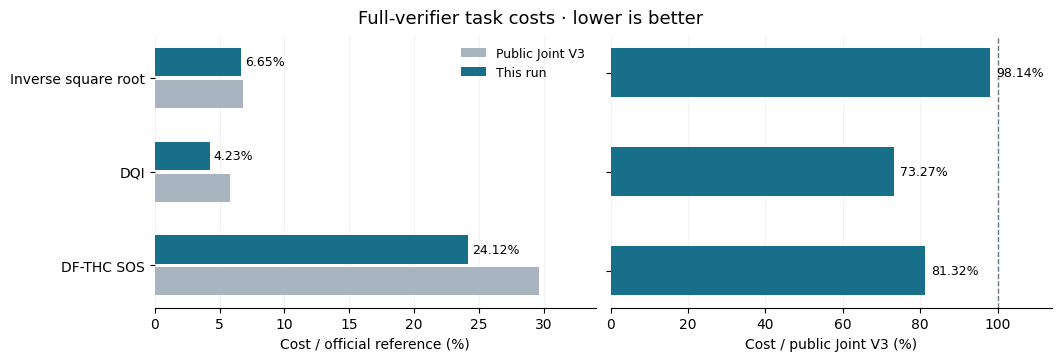

,Stage,Public_Joint_V3_913Q,Compact_v3_dry_run_884Q,This_run
0,Extraction + inverse,946592,954478,641608
1,Polynomial conversion + inverse,150872,156972,157992
2,Forney phase,327600,327600,348075


Static stage counts: partial/resource evidence. Verifier mean Toffolis include conditional execution.


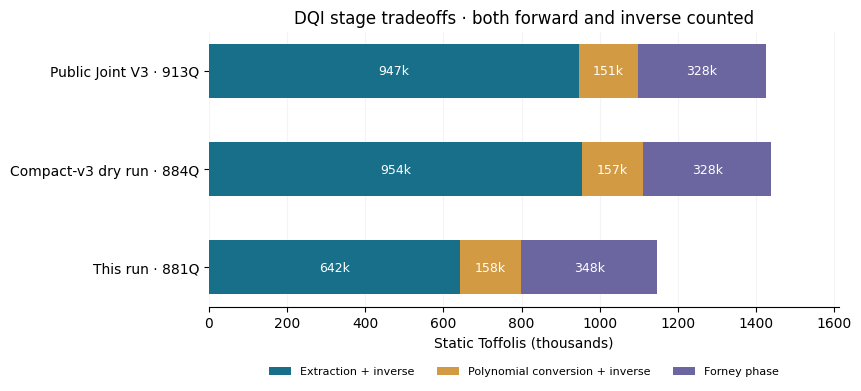

In [59]:
import matplotlib.pyplot as plt
names = ['invsqrt', 'dqi', 'dfthcsos']
labels = ['Inverse square root', 'DQI', 'DF-THC SOS']
previous = [140719.11744801095, 1409486347360.8557, 995288595.0601857]
current = [results[n]['score'] for n in names]
colors = ['#a8b4c0', '#176f8a']
x = np.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), layout='constrained')
for values, offset, color, label in ((previous, .17, colors[0], 'Public Joint V3'),
                                    (current, -.17, colors[1], 'This run')):
    bars = axes[0].barh(x+offset, [100*c/P.REFERENCE_COSTS[n] for n,c in zip(names,values)],
                        height=.30, color=color, label=label)
    if label=='This run': axes[0].bar_label(bars, fmt='%.2f%%', padding=3, fontsize=9)
axes[0].set(yticks=x, yticklabels=labels, xlabel='Cost / official reference (%)', xlim=(0,34))
axes[0].invert_yaxis()
axes[0].legend(frameon=False, loc='upper right', fontsize=9)
bars = axes[1].barh(x, [100*c/p for c,p in zip(current,previous)], color=colors[1],height=.5)
axes[1].bar_label(bars, fmt='%.2f%%', padding=4, fontsize=9)
axes[1].axvline(100,color='#6b7680',lw=1,ls='--')
axes[1].set(yticks=x,yticklabels=[],xlabel='Cost / public Joint V3 (%)',xlim=(0,114))
axes[1].invert_yaxis()
for ax in axes:
    ax.spines[['top','right','left']].set_visible(False)
    ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
fig.suptitle('Full-verifier task costs · lower is better',fontsize=13)
fig.savefig(REPORTS/'cost_comparison.png',dpi=160)
plt.show()

build = json.loads((REPORTS/'dqi_build.json').read_text(encoding='utf-8'))
stage = {s['boundary']:s['toffolis_since_previous'] for s in build['stages']}
now = [stage['moment_to_fraction']+stage['fraction_to_moments'],
       stage['fraction_to_polynomials']+stage['polynomials_to_fraction'],stage['phase_correction']]
stage_table = pd.DataFrame(dict(Stage=['Extraction + inverse','Polynomial conversion + inverse','Forney phase'],
    Public_Joint_V3_913Q=[946592,150872,327600],
    Compact_v3_dry_run_884Q=[954478,156972,327600],This_run=now))
stage_table.to_csv(REPORTS/'dqi_stage_counts.csv',index=False)
display(stage_table)
print('Static stage counts: partial/resource evidence. Verifier mean Toffolis include conditional execution.')
fig, ax = plt.subplots(figsize=(8.5,3.8),layout='constrained')
stage_colors = ['#176f8a','#d29a43','#6c66a0']
versions = ['Public Joint V3 · 913Q','Compact-v3 dry run · 884Q',f'This run · {dqi_result["num_qubits"]}Q']
counts = np.array([stage_table[c].to_numpy() for c in stage_table.columns[1:]])/1000
left = np.zeros(3)
for j,(label,color) in enumerate(zip(stage_table['Stage'],stage_colors)):
    bars = ax.barh(np.arange(3), counts[:,j],left=left,color=color,height=.55,label=label)
    ax.bar_label(bars,labels=[f'{v:.0f}k' for v in counts[:,j]],label_type='center',color='white',fontsize=9)
    left += counts[:,j]
ax.set(yticks=np.arange(3),yticklabels=versions,xlabel='Static Toffolis (thousands)',xlim=(0,max(left)*1.12),
       title='DQI stage tradeoffs · both forward and inverse counted')
ax.invert_yaxis()
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.18),ncol=3,fontsize=8)
ax.spines[['top','right','left']].set_visible(False)
ax.grid(axis='x',alpha=.13);ax.set_axisbelow(True)
fig.savefig(REPORTS/'dqi_stages.png',dpi=160)
plt.show()


## Assemble the verified artifact

The official file-reader preflight checks registers, instructions, numerical
arrays and layout. It is an archive contract check, separate from the three
full task verifiers above. We then compress exactly 11 members, reopen the
ZIP and stream SHA256 over every decompressed member. Reports and source
notices stay beside the submission archive.


In [60]:
%%writefile metric_preflight.py
"""Official Kaggle metric v10 readers, unchanged except formatting.
Source: https://www.kaggle.com/code/metric/google-quantum-ai-metric
Adapter preflight_directory only checks the file contract; task verification is separate.
"""
import json
import math
import pathlib
import random
import stat
import sys
import time
import tokenize
import zipfile
import zlib
from collections.abc import Callable, Mapping
from typing import Any
import numpy as np
import pandas as pd
ALLOWED_INSTRUCTIONS = {'X', 'CX', 'CCX', 'Z', 'CZ', 'CCZ', 'Z_POW', 'NEG', 'SWAP', 'CSWAP', 'R', 'HMR', 'BIT_INVERT', 'BIT_STORE0', 'BIT_STORE1', 'PUSH_CONDITION', 'POP_CONDITION', 'INFO_TAG', 'DEBUG_PRINT'}
MAX_QUBIT_OR_BIT_ID = 2 ** 30 // 1536
MAX_NPZ_BYTES = 2 ** 26

class ParticipantVisibleError(Exception):
    pass

def read_circuit(path: pathlib.Path, max_registers: int) -> Any:
    """Return a submitted .kmx or .kmb circuit as a kickmix.Circuit; raise ValueError unless it is fit to verify.

    kickmix validates a file as it parses it, within limits that keep parsing cheap, but simulating
    takes memory that grows with the largest qubit and bit ids, which kickmix allows up to ~5e8,
    so those are capped at MAX_QUBIT_OR_BIT_ID. kickmix also allows a million registers, at
    ~110 bytes each even if empty, so a circuit may have at most `max_registers`, the most its
    benchmark needs. Every register must be named: the dfthcsos verifier crashes on an unnamed one.
    """
    import kickmix
    circuit = kickmix.Circuit.from_file(path, format=path.suffix.removeprefix('.'))
    unsupported = set(circuit.operation_statistics()) - ALLOWED_INSTRUCTIONS
    if unsupported:
        raise ValueError(f'unsupported instructions {sorted(unsupported)}')
    largest_id = max(circuit.num_qubits, circuit.num_bits) - 1
    if largest_id >= MAX_QUBIT_OR_BIT_ID:
        raise ValueError(f'qubit or bit id {largest_id} is above the limit of {MAX_QUBIT_OR_BIT_ID - 1}')
    if circuit.num_registers > max_registers:
        raise ValueError(f'{circuit.num_registers} registers, above the limit of {max_registers} for this benchmark')
    if not all((isinstance(name, str) for name in circuit.register_data)):
        raise ValueError('every register needs a name, given by its REGISTER line')
    return circuit

def read_npz(path: pathlib.Path, spec: Mapping[str, tuple[str, tuple[int | str, ...]]]) -> dict[str, np.ndarray]:
    """Return the arrays `spec` names from an .npz; raise ValueError unless each is a plain number array as specified.

    `spec` maps each key to the numpy dtype kinds it may have, such as 'f' for floats, and its shape,
    in which a string names a dimension of any positive size that must agree wherever it recurs.

    Each array's header is a Python literal of its dtype and shape, which np.load trusts: a few KB
    of deflated zeros can claim a terabyte-sized array, and the dtype can be anything numpy can
    describe, from structured and nested types to Python objects that need unpickling. So the
    headers are read first, and the arrays loaded only if each is a plain number type of its kind,
    not big-endian, with its shape, and they total at most MAX_NPZ_BYTES. Only format 1.0 headers,
    which numpy.savez writes, are accepted, and numpy refuses any over 10 KB before parsing it.
    """
    dimensions: dict[str, int] = {}
    total = 0
    with zipfile.ZipFile(path) as archive:
        members = {name.removesuffix('.npy'): name for name in archive.namelist()}
        missing = [key for key in spec if key not in members]
        if missing:
            raise ValueError(f'{path.name} has no {missing}')
        for key, (kinds, expected_shape) in spec.items():
            with archive.open(members[key]) as member:
                if np.lib.format.read_magic(member) != (1, 0):
                    raise ValueError(f'{key} in {path.name} is not in .npy format 1.0, which numpy.savez writes')
                shape, _, dtype = np.lib.format.read_array_header_1_0(member)
            if dtype.kind not in kinds or dtype.names is not None or dtype.subdtype is not None or (dtype.byteorder == '>'):
                raise ValueError(f'{key} in {path.name} has dtype {dtype}, not a plain number type of numpy kind {kinds!r}')
            matches = len(shape) == len(expected_shape) and all((size > 0 and size == (dimensions.setdefault(expected, size) if isinstance(expected, str) else expected) for size, expected in zip(shape, expected_shape, strict=True)))
            if not matches:
                raise ValueError(f'{key} in {path.name} has shape {shape}, not {expected_shape} with its named dimensions as in {dimensions}')
            total += math.prod(shape) * dtype.itemsize
    if total > MAX_NPZ_BYTES:
        raise ValueError(f'the arrays in {path.name} take {total:,} bytes, above the limit of {MAX_NPZ_BYTES:,}')
    with np.load(path, allow_pickle=False) as npz:
        return {key: np.array(npz[key]) for key in spec}

def find_one(root: pathlib.Path, name: str, description: str, is_dir: bool=False) -> pathlib.Path:
    """The one path called `name` (a glob) under `root`, where the submission unpacked; raise ParticipantVisibleError otherwise."""
    paths = [path for path in root.rglob(name) if path.is_dir() == is_dir and '__MACOSX' not in path.relative_to(root).parts]
    if len(paths) != 1:
        raise ParticipantVisibleError(f'The submission must contain exactly one {description}, found {len(paths)}.')
    return paths[0]


def preflight_directory(directory):
    root = pathlib.Path(directory).resolve()
    inv_path = find_one(root, 'invsqrt.km[xb]', 'inverse circuit')
    dqi_path = find_one(root, 'dqi.km[xb]', 'DQI circuit')
    chemistry = find_one(root, 'dfthcsos', 'chemistry directory', is_dir=True)
    inv = read_circuit(inv_path, 1)
    inv_qubits = inv.num_qubits
    del inv
    decoder = read_circuit(dqi_path, 4095 + 70)
    decoder_qubits = decoder.num_qubits
    del decoder
    angles = sorted(chemistry.glob('angle_k_*.km[xb]'))
    if not angles or {p.stem for p in angles} != {f'angle_k_{i}' for i in range(len(angles))}:
        raise ValueError('Angle circuits must have consecutive numbering with no duplicate formats')
    angle_widths = []
    for path in angles:
        circuit = read_circuit(path, 128)
        if circuit.num_qubits > 128:
            raise ValueError('ANGLE circuit exceeds the 128-qubit cap')
        angle_widths.append(circuit.num_qubits)
        del circuit
    specification = {
        'U': ('f', ('R', 'B', 76)), 'W': ('f', ('R', 'B', 'C')),
        'H2_I': ('f', ('R', 'C')), 'H1_I': ('f', ()),
        'Hsym_lower': ('f', (2926,)), 'tree_edges': ('iu', (75, 2))
    }
    npz_path = find_one(chemistry, 'submission.npz', 'factorization')
    arrays = read_npz(npz_path, specification)
    paths = [inv_path, dqi_path, *sorted(angles, key=lambda p: int(p.stem.rsplit('_', 1)[1])), npz_path]
    return {'status': 'PASS', 'scope': 'Official file readers and archive layout; separate task PASS required',
            'invsqrt_qubits': inv_qubits, 'dqi_qubits': decoder_qubits,
            'angle_qubits': angle_widths, 'factorization_shape': list(arrays['W'].shape),
            'archive_members': [str(p.relative_to(root)).replace('\\', '/') for p in paths]}


Writing metric_preflight.py


In [61]:
assert P.digest(WORK/'metric_preflight.py') == '44e9449a044d766ed80435f11e7c013b1a45c2224472731b1a6808b9a5ca6eb5'

spec = importlib.util.spec_from_file_location('metric_preflight', WORK/'metric_preflight.py')
metric = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = metric
spec.loader.exec_module(metric)
archive_started = time.monotonic()
contract = metric.preflight_directory(FINAL)
assert contract['status']=='PASS'
contract['classification'] = 'partial/archive contract; full task reports are separate'
P.save(REPORTS/'archive_preflight.json', contract)
members = {'invsqrt.kmb','dqi.kmb','dfthcsos/submission.npz'} | {
    f'dfthcsos/angle_k_{i}.kmb' for i in range(ANGLE_COUNT)}
assert set(contract['archive_members']) == members and len(members)==11
archive = WORK/'submission.zip'
manifest = P.make_archive(FINAL, archive, members)
P.save(REPORTS/'submission_manifest.json', manifest)
member_hashes = {r['file']:r['sha256'] for r in manifest}
assert member_hashes['invsqrt.kmb']==P.AR_SHA
assert member_hashes['dqi.kmb']==P.DQI_SHA
assert P.official_manifest(COMP)==EXPECTED_OFFICIAL
main_run_seconds = time.monotonic()-RUN_STARTED
release_receipt = dict(revision='PAIRED_DQI_V6_THC_JOINT_NORM_EXP225A_V7',
    revision_status='ALL_THREE_FRESH_FULL_PASS_NOT_SUBMITTED',
    verification_mode='fresh_full_all_three_tasks',
    all_full_checks={n:dict(status=r['status'], classification=r['classification'],
        fresh=True, score=r['score'], verified_shots=r['verified_shots'],
        report_path='reports/'+('chemistry_full' if n=='dfthcsos' else
            'invsqrt_full' if n=='invsqrt' else 'dqi_full')+'.json') for n,r in results.items()},
    development_salt=SALT, seed_override=None, dqi_log2_delta=-128.0,
    archive_sha256=P.digest(archive), archive_bytes=archive.stat().st_size,
    member_count=len(members), member_sha256=member_hashes,
    archive_member_hashes_rechecked=True, new_projected_score=projected_score,
    new_observed_competition_score=None, public_dataset='anazemcev/vqcc-viberteam-verified-circuits',
    chemistry_package_manifest_sha256=RELEASE_PINS['chem_package_manifest_sha256'], source_manifest_sha256=P.digest(REPORTS/'source_manifest.json'),
    official_verifiers_sha256=EXPECTED_OFFICIAL, official_verifiers_unchanged=True,
    arithmetic_unchanged_public_binary=True, original_arithmetic_fitter_available=False,
    decoder_source_built=True, chemistry_source_compiled=True, chemistry_training_rerun=False, all_8_angle_hashes_identical=True,
    private_input_datasets=[], kernel_sources=[],
    competition_submission_performed_by_notebook=False,
    main_run_seconds=main_run_seconds, archive_seconds=time.monotonic()-archive_started)
P.save(REPORTS/'release_receipt.json', release_receipt)
print(f'ALL THREE FRESH FULL PASS; 11 ZIP members rehashed; '
      f'projection {projected_score:.9f}; main run {main_run_seconds/60:.2f} min.', flush=True)


ALL THREE FRESH FULL PASS; 11 ZIP members rehashed; projection 11.384375393; main run 21.91 min.


In [62]:
elapsed = time.monotonic()-RUN_STARTED
P.save(REPORTS/'runtime.json', dict(classification='measured full CPU Run All',
    full_run_seconds=elapsed, main_run_seconds=main_run_seconds,
    chemistry_recompile_seconds=chem_compile_seconds,
    dqi_build_seconds=dqi_build['build_seconds'],
    dqi_verification_seconds=dqi_result['wall_seconds'],
    arithmetic_verification_seconds=inv_result['wall_seconds'],
    chemistry_verification_seconds=chemistry_result['wall_seconds']))
runtime_display.update(Markdown(f'**Measured CPU Run All: {elapsed/60:.2f} minutes.** '
    f'All three fresh FULL-PASS; 11 archive members rehashed. Development projection {projected_score:.6f}; '
    'leaderboard result unknown.'))


## Credits, licenses and limits

**Dmitrii Gluzdov** supplies the single-group THC factorization and the ANF compiler `chemistry_r5.py`, Apache-2.0. His original public v4 NPZ is redistributed unchanged and SHA256 authenticated. **Ahmed Berat Ozer** supplies the v4 integration idea and readable wrapper. The ANF/measurement-erasure lineage credits **Artem Nazemtsev / anazemcev**; the pebbling and signed half-open gauge credit **Kozykorpesh**. ViberTeam K adds the independent complete-H fixed-word joint W/native-offset refit adapted from F/H, deterministic public-input CPU replay, packaging and verification. Phuc Thai's published description inspired joint norm refinement.

**Phuc Thai** supplies the unchanged EXP-225a arithmetic binary and the EXP-119a pairing idea; **marsyas** supplies the fused phase-stage arithmetic idea. **SomeJoint / Agniv Banerjee** supplies the decoder and **Manwithacat** the mask projection; paired-v6 is ViberTeam E's source implementation, retained unchanged. The inherited lineage includes **Gu et al.**, **Guang Hao Low**, the organizers' starter kit, **k256net/k256.dev**, **Sumit Chongder**, **Kirill Tymchishin / Kirill Tym**, **Zongao Bian**, **Alex Chilton**, **Rudra**, **LightningV08**, **Mizero Lucky Gall** and authors retained in source notices.

`LICENSE` contains Apache-2.0; `NOTICE.txt`, `thc_NOTICE.txt` and embedded notices retain attribution. Official data, verifiers, Kickmix and inherited numerical inputs keep their own terms. No endorsement is implied. The original arithmetic fitter is unpublished; its unchanged public binary is the reproducible boundary.

The public fixed development salt differs from the secret leaderboard salt. A full sampled PASS supports these exact bytes; the score above remains a development estimate until independently graded. Ahmed v4's 11.22420 is the observed leaderboard snapshot. This notebook creates a verified archive but never submits to the competition.
